# Setup

In [28]:
# Libraries
%load_ext autoreload
%autoreload 2

import random
import json
from typing import Dict, Any, Optional, Tuple
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from PIL import Image
from typing import List, Optional
import torch
from tqdm.notebook import tqdm
from scipy.stats import ttest_rel, shapiro, wilcoxon, norm, sem
import statsmodels.formula.api as smf

# --- Custom packages ---
from compcats.datasets.fmri import nsd
from compcats.datasets.fmri.utils import nsd_ds_utils
from compcats.utils import model_utils, coco_utils, responsecomparison_utils as rc_utils
import main_analysis as ma
import paths

# Paths
RESULTS_DIR = 'results'
MODELS_DIR = 'models'
PLOTS_DIR = f'{RESULTS_DIR}/plots/preprint/section6'
os.makedirs(PLOTS_DIR, exist_ok=True)
BAGS_DIR = 'interpretation_bags'
os.makedirs(BAGS_DIR, exist_ok=True)
NSD_DIR = paths.NSD_DIR
GRILLSPECTOR_LOCALIZER_DIR = paths.GRILLSPECTOR_LOCALIZER_DIR
COCO_ANNOTATIONS_PATH = paths.COCO_ANNOTATIONS_PATH

# Plot settings
import matplotlib as mpl
from matplotlib import rcParams
rcParams.update({'figure.autolayout': False})
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
mpl.rcParams['font.family'] = 'Avenir'

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
TOP_MODEL_NAMES = [
    'vitb16siglip2res224',
    'resnet50openaiclip',
    'convnexttinyimagenet1kv1',
    'resnet101openaiclip',
    'vitb14dinov2reg',
    'resnet50simclr',
    'resnet50toponettau30',
    'cornets',
    'resnet101imagenet1kv1',
    'vitb14dinov2'
]

STANDARD_MODEL_NAME = 'resnet50imagenet1kv2'

ALL_MODEL_NAMES = [STANDARD_MODEL_NAME] + TOP_MODEL_NAMES

MODEL_NAMES_DICT = {
    'resnet50imagenet1kv2': 'ResNet-50\nImageNet1K',
    'vitb16siglip2res224': 'ViT-B/16\nSigLIP2',
    'resnet50openaiclip': 'ResNet-50\nCLIP',
    'convnexttinyimagenet1kv1': 'ConvNeXt-Tiny\nImageNet1K',
    'resnet101openaiclip': 'ResNet-101\nCLIP',
    'vitb14dinov2reg': 'ViT-B/14\nDINOv2-Registers',
    'resnet50simclr': 'ResNet-50\nSimCLR',
    'resnet50toponettau30': 'ResNet-50\nTopoNet',
    'cornets': 'CORnet-S',
    'resnet101imagenet1kv1': 'ResNet-101\nImageNet1K',
    'vitb14dinov2': 'ViT-B/14\nDINOv2'
}

# Helper functions

In [3]:
# Linear mixed effects model and simple-effects tests for interaction

def median_diff_bootstrap(
    a: np.ndarray | list[float],
    b: np.ndarray | list[float],
    B: int = 10,
    ci: float = 0.95,
    rng: Optional[np.random.Generator] = None,
) -> Dict[str, Any]:
    """
    Compute the bootstrap standard error and confidence interval for the
    difference between the medians of two independent samples (conditions).

    Parameters
    ----------
    a : array-like of shape (n_A,)
        Responses for condition A (e.g., 25 stimuli for condition 1).
    b : array-like of shape (n_B,)
        Responses for condition B (e.g., 25 stimuli for condition 2).
        The two sets are assumed to be *independent* (no stimulus matching).

    B : int, default=10000
        Number of bootstrap resamples to perform.

    ci : float, default=0.95
        Confidence interval level (e.g., 0.95 for 95% CI).

    rng : np.random.Generator, optional
        Optional NumPy random number generator. If None, a new default generator
        will be created.

    Returns
    -------
    result : dict
        Dictionary with the following keys:
            - "delta": float, observed difference of medians (median(a) - median(b))
            - "sem": float, bootstrap standard error of delta
            - "ci_lo": float, lower bound of the percentile CI
            - "ci_hi": float, upper bound of the percentile CI
            - "boot": np.ndarray of shape (B,), bootstrap distribution of delta values

    Notes
    -----
    This method resamples within each condition independently (with replacement)
    and recomputes the difference of medians for each bootstrap draw.
    It provides a valid uncertainty estimate even when stimuli are not matched
    across conditions (e.g., 25 independent images per condition).
    """
    # fresh seeded RNG per call unless user supplies one
    rng = np.random.default_rng(42) if rng is None else rng

    a, b = np.asarray(a), np.asarray(b)

    delta_hat = np.median(a) - np.median(b)
    deltas = np.empty(B)

    nA, nB = len(a), len(b)
    for i in range(B):
        a_bs = a[rng.integers(0, nA, nA)]
        b_bs = b[rng.integers(0, nB, nB)]
        deltas[i] = np.median(a_bs) - np.median(b_bs)

    sem = deltas.std(ddof=1)
    alpha = 1 - ci
    lo, hi = np.quantile(deltas, [alpha / 2, 1 - alpha / 2])

    return {"delta": delta_hat, "sem": sem, "ci_lo": lo, "ci_hi": hi, "boot": deltas}

def run_lmm_legacy(
    df: pd.DataFrame,
):
    """
    PS - This is before adding output file option.
    
    Fit a linear mixed-effects model to the given DataFrame and
    compute simple-effects tests for the interaction terms.

    Parameters
    ----------
    df : pd.DataFrame
        DataFrame containing the data with columns:
            - "response": float, the response variable
            - "system": categorical, system type (e.g., "subject", "model")
            - "condition": categorical, condition type (e.g., "bag1", "bag2")
            - "subject": categorical, subject identifier for random effects

    Returns
    -------
    None
        Prints the model summary and simple-effects test results.
    """
    # Ensure categorical dtype (important!)
    df["system"] = df["system"].astype("category")
    df["condition"] = df["condition"].astype("category")

    print("\n=== LMM ===")
    model = smf.mixedlm("response ~ condition * system", 
                        data=df, 
                        groups="subject", 
                        re_formula="~1")
    result = model.fit()
    print("Random intercept var:", float(result.cov_re.iloc[0,0]))
    print(result.summary())

    # --- Identify parameter names programmatically ---
    # Assumes 2 levels for condition and 2 for system (your case).
    cond_levels = list(df["condition"].cat.categories)
    sys_levels  = list(df["system"].cat.categories)
    cond_base, cond_other = cond_levels[0], cond_levels[1]
    sys_base,  sys_other  = sys_levels[0],  sys_levels[1]

    # Build the exact coefficient labels that statsmodels used
    b_intercept = "Intercept"
    b_cond = f"condition[T.{cond_other}]"
    b_sys  = f"system[T.{sys_other}]"
    b_int  = f"{b_cond}:{b_sys}"

    params = result.params
    cov    = result.cov_params()

    def lincomb(weights: dict[str, float]):
        """
        Linearly combine named coefficients with given weights and
        return estimate, SE, z, p, and 95% CI.
        """
        # Build full weight vector aligned with params index
        w = np.zeros(len(params))
        for name, val in weights.items():
            if name not in params.index:
                raise KeyError(f"Coefficient '{name}' not found in model params: {list(params.index)}")
            w[params.index.get_loc(name)] = val
        est = float(np.dot(w, params.values))
        se  = float(np.sqrt(w @ cov.values @ w))
        z   = est / se if se > 0 else np.nan
        p   = 2 * norm.sf(abs(z)) if se > 0 else np.nan
        ci_lo = est - 1.96 * se
        ci_hi = est + 1.96 * se
        return est, se, z, p, ci_lo, ci_hi

    # --- Simple effects ---

    # 1) System difference within each condition
    #    (subject - model) at baseline condition
    est1 = lincomb({b_sys: 1.0})
    #    (subject - model) at the other condition
    est2 = lincomb({b_sys: 1.0, b_int: 1.0})

    # 2) Condition difference within each system
    #    (other - baseline) for the model
    est3 = lincomb({b_cond: 1.0})
    #    (other - baseline) for the subject
    est4 = lincomb({b_cond: 1.0, b_int: 1.0})

    rows = [
        (f"System diff @ {cond_base}  ({sys_other} - {sys_base})",) + est1,
        (f"System diff @ {cond_other} ({sys_other} - {sys_base})",) + est2,
        (f"Condition diff @ {sys_base}  ({cond_other} - {cond_base})",) + est3,
        (f"Condition diff @ {sys_other} ({cond_other} - {cond_base})",) + est4,
    ]

    simple_effects = pd.DataFrame(
        rows,
        columns=["Effect", "Estimate", "SE", "z", "p", "CI_low", "CI_high"]
    )

    print("\n=== Baselines ===")
    print("Baseline system   :", sys_base)
    print("Baseline condition:", cond_base)

    print("\n=== Simple-effects tests ===")
    print(simple_effects.round(4).to_string(index=False))

def run_lmm(df: pd.DataFrame, output_path: Optional[str] = None):
    """
    Fit a linear mixed-effects model to the given DataFrame and
    compute simple-effects tests for the interaction terms.

    Parameters
    ----------
    df : pd.DataFrame
        DataFrame containing the data with columns:
            - "response": float, the response variable
            - "system": categorical, system type (e.g., "subject", "model")
            - "condition": categorical, condition type (e.g., "bag1", "bag2")
            - "subject": categorical, subject identifier for random effects
    output_path : str, optional
        Path to a text file where the output will be written.
        If None (default), results are printed to the terminal.

    Returns
    -------
    None
        Prints or writes the model summary and simple-effects test results.
    """
    # Ensure categorical dtype (important!)
    df["system"] = df["system"].astype("category")
    df["condition"] = df["condition"].astype("category")
    model_name = set(df["system"].unique()) - {"subject"}
    model_name = list(model_name)[0] if model_name else None

    # Choose output stream
    out = open(output_path, "a") if output_path else None
    def write(s=""):
        if out:
            out.write(s + "\n")
        else:
            print(s)

    write("\n" + "="*80)
    if model_name:
        write(f"Model name: {model_name}")
    write(f"LMM Results:")
    write("-"*80)
    write("="*80 + "\n")

    write("=== LINEAR MIXED-EFFECTS MODEL ===")
    model = smf.mixedlm("response ~ condition * system",
                        data=df, groups="subject", re_formula="~1")
    result = model.fit(method="lbfgs", reml=True, maxiter=2000)
    # print("mle_retvals:", result.mle_retvals)
    write(f"Random intercept var: {float(result.cov_re.iloc[0,0]):.6f}")
    write(result.summary().as_text())

    # --- Extract interaction term (the one with ":") ---
    interaction_term = [name for name in result.pvalues.index if ":" in name][0]
    interaction_p = float(result.pvalues[interaction_term])

    # --- Print formatted result ---
    if interaction_p <= 0.05:
        write(f"Interaction ({interaction_term}) p = {interaction_p:.5f}  --> SIGNIFICANT")
    else:
        write(f"Interaction ({interaction_term}) p = {interaction_p:.5f}  --> NOT SIGNIFICANT")


    # --- Identify parameter names programmatically ---
    cond_levels = list(df["condition"].cat.categories)
    sys_levels  = list(df["system"].cat.categories)
    cond_base, cond_other = cond_levels[0], cond_levels[1]
    sys_base,  sys_other  = sys_levels[0],  sys_levels[1]

    # Build coefficient labels as they appear in statsmodels
    b_cond = f"condition[T.{cond_other}]"
    b_sys  = f"system[T.{sys_other}]"
    b_int  = f"{b_cond}:{b_sys}"

    params = result.params
    cov    = result.cov_params()

    def lincomb(weights: dict[str, float]):
        """Linearly combine named coefficients and return estimate, SE, z, p, and 95% CI."""
        w = np.zeros(len(params))
        for name, val in weights.items():
            if name not in params.index:
                raise KeyError(f"Coefficient '{name}' not found in model params: {list(params.index)}")
            w[params.index.get_loc(name)] = val
        est = float(np.dot(w, params.values))
        se  = float(np.sqrt(w @ cov.values @ w))
        z   = est / se if se > 0 else np.nan
        p   = 2 * norm.sf(abs(z)) if se > 0 else np.nan
        ci_lo = est - 1.96 * se
        ci_hi = est + 1.96 * se
        return est, se, z, round(p, 5), ci_lo, ci_hi

    # --- Simple effects ---
    est1 = lincomb({b_sys: 1.0})                # System diff @ baseline
    est2 = lincomb({b_sys: 1.0, b_int: 1.0})    # System diff @ other condition
    est3 = lincomb({b_cond: 1.0})               # Condition diff @ model
    est4 = lincomb({b_cond: 1.0, b_int: 1.0})   # Condition diff @ subject

    rows = [
        (f"System diff @ {cond_base}  ({sys_other} - {sys_base})",) + est1,
        (f"System diff @ {cond_other} ({sys_other} - {sys_base})",) + est2,
        (f"Condition diff @ {sys_base}  ({cond_other} - {cond_base})",) + est3,
        (f"Condition diff @ {sys_other} ({cond_other} - {cond_base})",) + est4,
    ]

    simple_effects = pd.DataFrame(
        rows,
        columns=["Effect", "Estimate", "SE", "z", "p", "CI_low", "CI_high"]
    )

    write("\n=== BASELINES ===")
    write(f"Baseline system   : {sys_base}")
    write(f"Baseline condition: {cond_base}")

    write("\n=== SIMPLE-EFFECTS TESTS ===")
    write(simple_effects.round(4).to_string(index=False))

    if out:
        out.close()
        print(f"Results written to: {output_path}")

In [4]:
# Data utils

def get_data(
    subject: int,
    froi: str,
    subset: int | None, # 515 for shared, None for subject-specific set
    model_name: str,
    nsdids: Optional[List[int]] = None
):
    tthreshold = 7
    model_localizer = 'grillspector'
    model_localizer_dir = GRILLSPECTOR_LOCALIZER_DIR
    # Get model and layer
    model = ma.get_model(model_name)
    layer = ma.get_froi_models_layers(froi, froi)[model_name]
    # Subject data
    subject_data, images_df = nsd.get_betas(
        NSD_DIR, subject, froi, tthreshold, subset=subset, voxels=True
    )
    # Model data
    model_data = model_utils.get_dataset_activations(
        MODELS_DIR, NSD_DIR, model, layer, 'nsd', froi, tthreshold, subset=subset,
        froi_localizer=model_localizer, froi_localizer_dir=model_localizer_dir, device='cpu'
    )
    # Stimuli
    stimuli = nsd.get_stimuli_dataset(NSD_DIR, transform=None, subset=subset).all_stimuli
    # Add info to images_df
    images_df = coco_utils.add_image_info_to_df(images_df, COCO_ANNOTATIONS_PATH)
    # Choose subject-specific images if needed
    if subset is None:
        shared1000_nsdids = nsd_ds_utils.get_subset_nsdids(paths.NSD_DIR, 1000)
        subject_data = subject_data[~images_df['nsdId'].isin(shared1000_nsdids)]
        images_df = images_df[~images_df['nsdId'].isin(shared1000_nsdids)].reset_index(drop=True)
        subject_nsdids = images_df['nsdId'].values
        stimuli = stimuli[subject_nsdids]
        model_data = model_data[subject_nsdids]

    # Get correlations for validation
    pearsonr = rc_utils.pearsonr(
        subject_data.mean(axis=-1), model_data.mean(axis=-1)
    )
    rdmr = rc_utils.rdmr(subject_data, model_data)
    print(f"Full subset, \nMean Pearson r: {pearsonr:.4f}, RDMR: {rdmr:.4f}")

    # Store Voxel/Unit-averaged responses
    subject_data_mean = subject_data.mean(axis=-1).cpu().numpy()
    model_data_mean = model_data.mean(axis=-1).cpu().numpy()
    ## Also store z-scored versions
    subject_data_mean_zscored = (subject_data_mean - subject_data_mean.mean()) / subject_data_mean.std()
    model_data_mean_zscored = (model_data_mean - model_data_mean.mean()) / model_data_mean.std()

    if nsdids is not None:
        subject_data_mean_nsdid_subset = subject_data_mean[np.isin(images_df['nsdId'].values, nsdids)]
        model_data_mean_nsdid_subset = model_data_mean[np.isin(images_df['nsdId'].values, nsdids)]
        subject_data_mean_zscored_nsdid_subset = subject_data_mean_zscored[np.isin(images_df['nsdId'].values, nsdids)]
        model_data_mean_zscored_nsdid_subset = model_data_mean_zscored[np.isin(images_df['nsdId'].values, nsdids)]
        # Get correlations for validation
        pearsonr_mean = rc_utils.pearsonr(
            torch.tensor(subject_data_mean_nsdid_subset),
            torch.tensor(model_data_mean_nsdid_subset)
        )
        pearsonr_mean_zscored = rc_utils.pearsonr(
            torch.tensor(subject_data_mean_zscored_nsdid_subset), 
            torch.tensor(model_data_mean_zscored_nsdid_subset)
        )
        print(f"nsd ID subset mean, \nMean Pearson r: {pearsonr_mean:.4f}, Z-scored Pearson r: {pearsonr_mean_zscored:.4f}")

        subject_data_mean_zscored = subject_data_mean_zscored_nsdid_subset
        model_data_mean_zscored = model_data_mean_zscored_nsdid_subset

        nsdid_indices = np.isin(images_df['nsdId'].values, nsdids)
        subject_data = subject_data[nsdid_indices]
        stimuli = stimuli[nsdid_indices]
        model_data = model_data[nsdid_indices]
        images_df = images_df[nsdid_indices].reset_index(drop=True)

    mean_responses_df = pd.DataFrame({
        'idx': images_df.index,
        'nsd_image_id': images_df['nsdId'],
        'subject_response': subject_data_mean_zscored,
        'model_response': model_data_mean_zscored,
        'response_diff': subject_data_mean_zscored - model_data_mean_zscored,
        'labels': images_df['labels'],
    })
    return mean_responses_df, images_df, stimuli, subject_data, model_data

In [5]:
# JSON saving utils

def format_list(lst, indent_level, indent_size=4, max_per_line=5):
    indent = " " * (indent_level * indent_size)
    inner_indent = " " * ((indent_level + 1) * indent_size)

    lines = []
    for i in range(0, len(lst), max_per_line):
        chunk = lst[i:i + max_per_line]
        line = ", ".join(str(x) for x in chunk)
        lines.append(inner_indent + line)

    return "[\n" + ",\n".join(lines) + "\n" + indent + "]"

def custom_json(obj, indent_level=0):
    indent_size = 4
    indent = " " * (indent_level * indent_size)

    if isinstance(obj, dict):
        items = []
        for k, v in obj.items():
            formatted_value = custom_json(v, indent_level + 1)
            items.append(f'{indent}{" " * indent_size}"{k}": {formatted_value}')
        return "{\n" + ",\n".join(items) + "\n" + indent + "}"

    elif isinstance(obj, list):
        # If it's a list of ints/floats → format 10 per line
        if all(isinstance(x, (int, float)) for x in obj):
            return format_list(obj, indent_level)
        else:
            # fallback
            return json.dumps(obj, indent=4)

    else:
        return json.dumps(obj)

def save_dict_as_json(d: Dict[Any, Any], file_path: str):
    with open(file_path, "w", encoding="utf-8") as f:
        f.write(custom_json(d))
    print(f"Saved dict to {file_path}")

def load_dict_from_json(file_path: str) -> Tuple[Dict[int, Any], List[str], List[str]]:
    with open(file_path, "r", encoding="utf-8") as f:
        loaded_dict = json.load(f)
    # convert top-level keys back to int
    loaded_dict = {
        int(k): v for k, v in loaded_dict.items()
    }
    example_subject = 2
    comparisons_present = list(loaded_dict[example_subject].keys())
    bags_present = []
    for comparison in loaded_dict[example_subject]:
        for bag_key in loaded_dict[example_subject][comparison].keys():
            bags_present.append(bag_key)
    bags_present = list(set(bags_present))
    print(f"Loaded dict from {file_path}")
    print(f'Comparisons present: {comparisons_present}')
    print(f'Bags present: {bags_present}')
    return loaded_dict, comparisons_present, bags_present

def print_bags_statistics(
    bags_dict: Dict[int, Any],
    comparisons_considered: List[str],
    bags_considered: List[str]
):
    bag_nsamples_df = []
    for subject in range(2, 9):
        sbj_row = {'subject': subject}
        sbj_bags = bags_dict[subject]
        for comparison_type in sbj_bags:
            if comparison_type not in comparisons_considered:
                continue
            comparison_dict = sbj_bags[comparison_type]
            for bag_key, bag_nsdids in comparison_dict.items():
                if bag_key in bags_considered:
                    sbj_row[bag_key] = len(bag_nsdids)
        bag_nsamples_df.append(sbj_row)
    bag_nsamples_df = pd.DataFrame(bag_nsamples_df)
    display(bag_nsamples_df)

    # Print total, mean and std per bag
    for bag_label in bags_considered:
        total = bag_nsamples_df[bag_label].sum()
        mean = bag_nsamples_df[bag_label].mean()
        std = bag_nsamples_df[bag_label].std()
        print(f"{bag_label}: Total={total}, Mean={mean:.2f}, Std={std:.2f}")

# Stimuli bags

In [6]:
# bags_successful_nsamples_path = f'{BAGS_DIR}/bags_successful_nsamples.json'
# bags_successful_nsamples, comparisons_nsamples, bags_nsamples = load_dict_from_json(bags_successful_nsamples_path)
# print_bags_statistics(bags_successful_nsamples, comparisons_nsamples, bags_nsamples)

bags_successful_25samples_path = f'{BAGS_DIR}/bags_successful_25samples.json'
bags_successful_25samples, comparisons_25samples, bags_25samples = load_dict_from_json(bags_successful_25samples_path)
print_bags_statistics(bags_successful_25samples, comparisons_25samples, bags_25samples)

Loaded dict from interpretation_bags/bags_successful_25samples.json
Comparisons present: ['faces', 'bodies', 'scenes']
Bags present: ['with_humans', 'limbs_covered', 'animal_faces', 'limbs_visible', 'without_humans', 'human_faces']


,subject,human_faces,animal_faces,limbs_visible,limbs_covered,without_humans,with_humans
0,2,25,25,25,25,25,25
1,3,25,25,25,25,25,25
2,4,25,25,25,25,25,25
3,5,25,25,25,25,25,25
4,6,25,25,25,25,25,25
5,7,25,25,25,25,25,25
6,8,25,25,25,25,25,25


with_humans: Total=175, Mean=25.00, Std=0.00
limbs_covered: Total=175, Mean=25.00, Std=0.00
animal_faces: Total=175, Mean=25.00, Std=0.00
limbs_visible: Total=175, Mean=25.00, Std=0.00
without_humans: Total=175, Mean=25.00, Std=0.00
human_faces: Total=175, Mean=25.00, Std=0.00


# Main figure: Fig 6

## Setup

In [7]:
# STIMULI = nsd.get_stimuli_dataset(NSD_DIR, transform=None, subset=None).all_stimuli

frois = ['FFA', 'EBA', 'PPA']
subjects = [2, 3, 4, 5, 6, 7, 8]  # NSD subjects
mean_zscored_responses_df_path = f'results/exploration/explore_interpret/subject_specific_mean_zscored_responses.csv'
resp_df = pd.read_csv(mean_zscored_responses_df_path)

froi_bags = {
    'FFA': 'faces',
    'EBA': 'bodies',
    'PPA': 'scenes',
}
# model_color = '#944e1f' # Brown
# subject_color = '#fde0c5' # Light peach

stats_dir = f'{PLOTS_DIR}/main_figure/stats'
os.makedirs(stats_dir, exist_ok=True)

plot_dir = f'{PLOTS_DIR}/main_figure'
os.makedirs(plot_dir, exist_ok=True)

human_color = '#d24c34' # Light peach
model_color = '#15a6cc' # Light blue

## Stats

In [ ]:
execute_lmm = False
stats_dir = f'{PLOTS_DIR}/main_figure/stats'
os.makedirs(stats_dir, exist_ok=True)
dfs_dir = f'{PLOTS_DIR}/main_figure/stats/dataframes'
os.makedirs(dfs_dir, exist_ok=True)

stimuli_bags = bags_successful_25samples
# comparions_25samples, bags_25samples
# ['limbs_covered', 'limbs_visible', 'with_humans', 'without_humans', 'animal_faces', 'human_faces']
bags_dict = {
    'FFA': ('faces', ['animal_faces', 'human_faces']),
    'EBA': ('bodies', ['limbs_covered', 'limbs_visible']),
    'PPA': ('scenes', ['without_humans', 'with_humans']),
}

# for each froi
for froi in frois:
    comparison_type = bags_dict[froi][0]
    bag_type1, bag_type2 = bags_dict[froi][1]
    lmm_output_file_path = f'{stats_dir}/lmm_{froi}_comparison={comparison_type}_{bag_type1}_vs_{bag_type2}.txt'
    print(f'Stats for {froi}...')
    # print(f'Delta: {bags[subjects[0]][bag_type]["bag1"]["label"]} - {bags[subjects[0]][bag_type]["bag2"]["label"]}')

    # Variables for storing bag responses
    models_bags_median_responses = {}
    subject_bags_median_responses = []

    # Models
    for model_name in ALL_MODEL_NAMES:
        model_bags_median_responses = []
        df = []
        for subject in subjects:
            bag1_nsdids = stimuli_bags[subject][comparison_type][bag_type1]
            bag2_nsdids = stimuli_bags[subject][comparison_type][bag_type2]
            sbj_froi_mdl_subset_resp_df = resp_df[
                (resp_df['subject'] == subject) &
                (resp_df['froi'] == froi)
            ]
            subject_responses_bag1 = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_nsdids)
            ]['subject_response']
            if len(subject_responses_bag1) < 25:
                missing_nsdids = set(bag1_nsdids) - set(sbj_froi_mdl_subset_resp_df['nsd_id'])
                print(f'Subject {subject} - {bag_type1} - {len(subject_responses_bag1)} samples - Missing NSD IDs: {missing_nsdids}')
                repeated = list({x for x in bag1_nsdids if bag1_nsdids.count(x) > 1})
                print(f'Repeated NSD IDs: {repeated}')
            for pt in subject_responses_bag1:
                df.append({
                    'response': pt,
                    'system': 'subject',
                    'condition': bag_type1,
                    'subject': subject,
                })
            subject_responses_bag2 = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_nsdids)
            ]['subject_response']
            if len(subject_responses_bag2) < 25:
                missing_nsdids = set(bag2_nsdids) - set(sbj_froi_mdl_subset_resp_df['nsd_id'])
                print(f'Subject {subject} - {bag_type2} - {len(subject_responses_bag2)} samples, Missing NSD IDs: {missing_nsdids}')
                repeated = list({x for x in bag2_nsdids if bag2_nsdids.count(x) > 1})
                print(f'Repeated NSD IDs: {repeated}')
            for pt in subject_responses_bag2:
                df.append({
                    'response': pt,
                    'system': 'subject',
                    'condition': bag_type2,
                    'subject': subject,
                })
            model_responses_bag1 = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_nsdids)
            ][f'{model_name}_response']
            if len(model_responses_bag1) < 25:
                missing_nsdids = set(bag1_nsdids) - set(sbj_froi_mdl_subset_resp_df['nsd_id'])
                print(f'Model {model_name} - Subject {subject} - {bag_type1} - {len(model_responses_bag1)} samples, Missing NSD IDs: {missing_nsdids}')
                repeated = list({x for x in bag1_nsdids if bag1_nsdids.count(x) > 1})
                print(f'Repeated NSD IDs: {repeated}')
            for pt in model_responses_bag1:
                df.append({
                    'response': pt,
                    'system': model_name,
                    'condition': bag_type1,
                    'subject': subject,
                })
            model_responses_bag2 = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_nsdids)
            ][f'{model_name}_response']
            if len(model_responses_bag2) < 25:
                missing_nsdids = set(bag2_nsdids) - set(sbj_froi_mdl_subset_resp_df['nsd_id'])
                print(f'Model {model_name} - Subject {subject} - {bag_type2} - {len(model_responses_bag2)} samples, Missing NSD IDs: {missing_nsdids}')
                repeated = list({x for x in bag2_nsdids if bag2_nsdids.count(x) > 1})
                print(f'Repeated NSD IDs: {repeated}')
            for pt in model_responses_bag2:
                df.append({
                    'response': pt,
                    'system': model_name,
                    'condition': bag_type2,
                    'subject': subject,
                })
            model_bags_median_responses.append([np.median(model_responses_bag1), np.median(model_responses_bag2)])
        models_bags_median_responses[model_name] = np.array(model_bags_median_responses)
        df = pd.DataFrame(df)
        if execute_lmm:
            run_lmm(df, lmm_output_file_path)
            # Save the dataframe used for the LMM
            df.to_csv(f'{dfs_dir}/{model_name}_{froi}_comparison={comparison_type}_{bag_type1}_vs_{bag_type2}.csv', index=False)
    #     break
    # break
    print('\n\n')

Stats for FFA...


/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


Results written to: results/plots/preprint/section6/main_figure/stats/lmm_FFA_comparison=faces_animal_faces_vs_human_faces.txt


/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


Results written to: results/plots/preprint/section6/main_figure/stats/lmm_FFA_comparison=faces_animal_faces_vs_human_faces.txt


...

/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


Results written to: results/plots/preprint/section6/main_figure/stats/lmm_PPA_comparison=scenes_without_humans_vs_with_humans.txt


/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


Results written to: results/plots/preprint/section6/main_figure/stats/lmm_PPA_comparison=scenes_without_humans_vs_with_humans.txt
Results written to: results/plots/preprint/section6/main_figure/stats/lmm_PPA_comparison=scenes_without_humans_vs_with_humans.txt





/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


## Stimuli

In [ ]:
all_stimuli, _ = nsd.get_subset_stimuli(NSD_DIR, None)
stimuli_bags = bags_successful_25samples
# Loop over subjects 2-8, make a folder
# For Faces and scenes_perspective, loop over bags, make a folder for them
# Save the first 3 images from each bag
for subject in range(2, 9):
    subject_dir = f'{PLOTS_DIR}/main_figure/stimuli/subject_{subject}'
    if not os.path.exists(subject_dir):
        os.makedirs(subject_dir, exist_ok=True)
    for category in ['faces', 'scenes', 'bodies']:
        category_dir = f'{subject_dir}/{category}'
        if not os.path.exists(category_dir):
            os.makedirs(category_dir, exist_ok=True)
        for bag_label, bag_nsdids in stimuli_bags[subject][category].items():
            bag_dir = f'{category_dir}/{bag_label}'
            if not os.path.exists(bag_dir):
                os.makedirs(bag_dir, exist_ok=True)
            for nsdid in bag_nsdids:
                img = all_stimuli[nsd_id]
                # Save the image as a jpg
                img = Image.fromarray(img)
                img.save(f'{bag_dir}/{nsd_id}.jpg')
                # print(f"Saved image {nsd_id} to {bag_dir}/{nsd_id}.jpg")

## Fig 6c: held-out images, subjects and models

Processing FFA...
Maximum value across all models and subjects: 4.495260342857143, Minimum value across all models and subjects: 0.42831436142857143


Processing EBA...
Maximum value across all models and subjects: 2.1674917714285713, Minimum value across all models and subjects: 0.060588431142857155


Processing PPA...
Maximum value across all models and subjects: 0.6047176842857143, Minimum value across all models and subjects: -0.5358185985714286




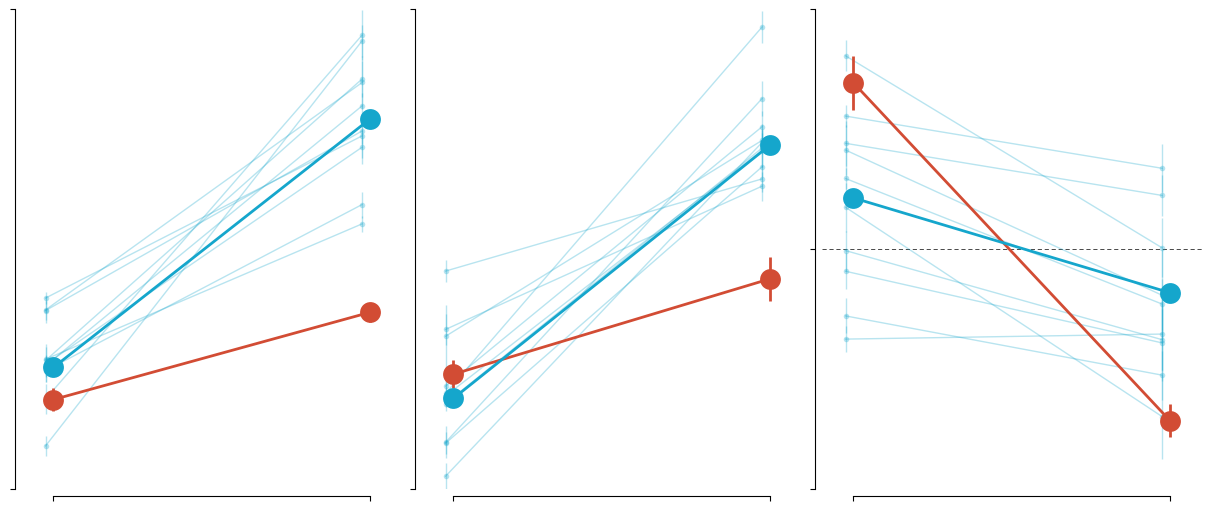

In [9]:
savefig = True
hide_y_info = True # Hide y-axis label and tick labels
figname = 'fig6_models_brains_interpretation.pdf'

stimuli_bags = bags_successful_25samples
# comparions_25samples, bags_25samples
# ['limbs_covered', 'limbs_visible', 'with_humans', 'without_humans', 'animal_faces', 'human_faces']
bags_dict = {
    'FFA': ('faces', ['animal_faces', 'human_faces']),
    'EBA': ('bodies', ['limbs_covered', 'limbs_visible']),
    'PPA': ('scenes', ['without_humans', 'with_humans']),
}

# fig, axes = plt.subplots(2, len(frois), figsize=(4*len(frois), 10), constrained_layout=True)
fig, axes = plt.subplots(1, len(frois), figsize=(4*len(frois), 5), constrained_layout=True)
show_errorbars = True
show_individual_points = False # Do show individual points to show the distribution across subjects, but not error bars since we have few subjects and they can be misleading
show_collated_model_median = True # In plot 2, make individual model points tiny and plot the median across models as a big point
assert (not show_individual_points) and (show_collated_model_median), "If showing individual points, we should not show the collated median, since the individual points will show the distribution across subjects. If not showing individual points, we should show the collated median to summarize the central tendency across subjects."
plot_limits_dict = { # Keep it the same for plot 0 and 1 to allow slope interpretation,
    # For ylims, add a 1% offset to min to give some space below the lowest point, and set the max to accommodate the highest point across both plots
    'ylim': {
        'FFA': [0, 4.75],
        'EBA': [0, 2.25],
        'PPA': [-0.75, 0.75], 
    }, # all min y-lims have a 0.05 offset to give some space below the lowest point, and all max y-lims are set to accommodate the highest point across both plots
    'yticks': {'FFA': np.array([0, 4.75]),'EBA': np.array([0, 2.25]),'PPA': np.array([-0.75, 0, 0.75])},
}
plot_y_pad = 0.05
x_positions = np.array([0, 0.3])
plot_x_pad = (x_positions[1] - x_positions[0]) * 0.1 # 10% of the distance between the two collated points
jitter_collated_points = False
collated_points_offset = 0 #(x_positions[1] - x_positions[0]) * 0.025 # 2.5% of the distance between the two collated points
collated_points_alpha = 1 # 0.8
collated_points_marker_size = 15 # 10
collated_points_linewidth = 2
individual_points_offset = (x_positions[1] - x_positions[0]) * 0.025 # 2.5% # old: 1% beyond the collated points
individual_points_alpha = 0.3
individual_points_marker_size = 4
individual_points_linewidth = 1

for froi_idx, froi in enumerate(frois):
    print(f'Processing {froi}...')
    # Subplot 1: Brains vs. ResNet-50 ImageNet-1k
    # plot_idx = 0
    # ax_current = axes[plot_idx, froi_idx]
    # model_name = STANDARD_MODEL_NAME
    bags_class, (bag1_type, bag2_type) = bags_dict[froi][0], (bags_dict[froi][1][0], bags_dict[froi][1][1])
    bag_types_present = stimuli_bags[list(stimuli_bags.keys())[-1]][bags_class].keys()
    bag_types_passed = sorted([bag1_type, bag2_type])
    bag_types_loaded = sorted(bag_types_present)
    assert bag_types_passed == bag_types_loaded, f"Bag types passed ({bag_types_passed}) do not match bag types loaded ({bag_types_loaded})"
    # model_points, subject_points = [], []
    # for subject in range(2, 9):
    #     # Get the indices of the bag types in the original order
    #     bag1_nsdids = stimuli_bags[subject][bags_class][bag1_type]
    #     bag2_nsdids = stimuli_bags[subject][bags_class][bag2_type]
    #     assert len(bag1_nsdids) == 25, f"Expected 25 nsdids for bag1, got {len(bag1_nsdids)}"
    #     assert len(bag2_nsdids) == 25, f"Expected 25 nsdids for bag2, got {len(bag2_nsdids)}"
    #     model_responses_bag1_median = resp_df[
    #                         (resp_df['subject'] == subject) &
    #                         (resp_df['froi'] == froi) &
    #                         (resp_df['nsd_id'].isin(bag1_nsdids))
    #                     ][f'{model_name}_response'].median()
    #     model_responses_bag2_median = resp_df[
    #                         (resp_df['subject'] == subject) &
    #                         (resp_df['froi'] == froi) &
    #                         (resp_df['nsd_id'].isin(bag2_nsdids))
    #                     ][f'{model_name}_response'].median()
    #     subject_responses_bag1_median = resp_df[
    #                         (resp_df['subject'] == subject) &
    #                         (resp_df['froi'] == froi) &
    #                         (resp_df['nsd_id'].isin(bag1_nsdids))
    #                     ]['subject_response'].median()
    #     subject_responses_bag2_median = resp_df[
    #                         (resp_df['subject'] == subject) &
    #                         (resp_df['froi'] == froi) &
    #                         (resp_df['nsd_id'].isin(bag2_nsdids))
    #                     ]['subject_response'].median()
    #     model_points.append((model_responses_bag1_median, model_responses_bag2_median))
    #     subject_points.append((subject_responses_bag1_median, subject_responses_bag2_median))
    # model_points = np.array(model_points)
    # subject_points = np.array(subject_points)
    # print(f'Maximum value: {max(model_points.max(), subject_points.max())}, Minimum value: {min(model_points.min(), subject_points.min())}')
    # # x-axis = bags, y-axis = responses
    # # first plot mean across subjects for each bag (+- SEM), and connect the 2 points across bags with a line
    # model_means = model_points.mean(axis=0)
    # model_sems = model_points.std(axis=0) / np.sqrt(len(model_points))
    # subject_means = subject_points.mean(axis=0)
    # subject_sems = subject_points.std(axis=0) / np.sqrt(len(subject_points))
    # print(f'Model means: {model_means}, Subject means: {subject_means}')
    # if show_errorbars:
    #     # Model
    #     ax_current.errorbar(
    #         x_positions - collated_points_offset,
    #         model_means, yerr=model_sems, fmt='-o', color=model_color, label='ResNet-50 ImageNet-1k',
    #         alpha=collated_points_alpha, markersize=collated_points_marker_size,
    #         linewidth=collated_points_linewidth, mec='none', mew=0, zorder=10
    #     )
    #     # Subject
    #     ax_current.errorbar(
    #         x_positions + collated_points_offset, subject_means, yerr=subject_sems,
    #         fmt='-o', color=human_color, label='NSD Subjects',
    #         alpha=collated_points_alpha, markersize=collated_points_marker_size,
    #         linewidth=collated_points_linewidth, mec='none', mew=0, zorder=9
    #     )
    # else:
    #     # Model
    #     ax_current.plot(
    #         x_positions - collated_points_offset, model_means, 'o-', color=model_color, label='ResNet-50 ImageNet-1k',
    #         alpha=collated_points_alpha, markersize=collated_points_marker_size,
    #         linewidth=collated_points_linewidth, mec='none', mew=0, zorder=10
    #     )
    #     # Subject
    #     ax_current.plot(
    #         x_positions + collated_points_offset, subject_means, 'o-', color=human_color, label='NSD Subjects',
    #         alpha=collated_points_alpha, markersize=collated_points_marker_size,
    #         linewidth=collated_points_linewidth, mec='none', mew=0, zorder=9
    #     )
    # if show_individual_points:
    #     for i in range(len(model_points)):
    #         # Model
    #         ax_current.plot(
    #             x_positions - collated_points_offset - individual_points_offset,
    #             model_points[i], '.-', color=model_color, alpha=individual_points_alpha,
    #             markersize=individual_points_marker_size, linewidth=individual_points_linewidth,
    #             mec='none', mew=0
    #         )
    #         # Subjects
    #         ax_current.plot(
    #             x_positions + collated_points_offset + individual_points_offset, 
    #             subject_points[i], '.-', color=human_color, alpha=individual_points_alpha,
    #             markersize=individual_points_marker_size, linewidth=individual_points_linewidth,
    #             mec='none', mew=0
    #         )
    # ax_current.axhline(
    #         y=0, color='k', alpha=1, linewidth=0.5, zorder=-10,
    #         linestyle=(0, (6, 4))  # (offset, (dash_length, gap_length))
    #     )
    # if hide_y_info:
    #     ax_current.set_yticklabels([])
    #     ax_current.set_ylabel('')
    # else:
    #     ax_current.set_ylabel('Voxel/Unit-averaged responses, z-scored')
    # ax_current.set_yticks(plot_limits_dict['yticks'][froi])
    # # ax_current.set_title(f'{froi} - {bag1_type.replace("_", " ").title()} vs. {bag2_type.replace("_", " ").title()}')
    # # ax_current.legend()
    # ax_current.set_ylim(plot_limits_dict['ylim'][froi])
    # ax_current.spines['top'].set_visible(False)
    # ax_current.spines['right'].set_visible(False)
    # # No x-axis, since it's redundant with the second plot, and we want to visually connect the two plots by aligning the y-axes and removing the x-axis from the first plot
    # ax_current.spines['bottom'].set_visible(False)
    # ax_current.tick_params(bottom=False)
    # ax_current.set_xticks([])
    # # ax_current.set_xticks(x_positions)
    # # ax_current.set_xticklabels([bag1_type.replace('_', ' ').title(), bag2_type.replace('_', ' ').title()])
    # # ax_current.spines['bottom'].set_position(('outward', 5))
    # # ax_current.spines['bottom'].set_bounds(x_positions)
    # ax_current.spines['left'].set_position(('outward', 5))
    # ax_current.spines['left'].set_bounds((np.min(plot_limits_dict['yticks'][froi]), np.max(plot_limits_dict['yticks'][froi])))
    # ax_current.set_xlim(x_positions[0] - plot_x_pad, x_positions[1] + plot_x_pad)

    # Plot 2: Brains vs. Top models
    # Only plot the mean across subjects for each bag, and connect the 2 points across bags with a line (no individual points)
    # plot_idx = 1
    if jitter_collated_points:
        np.random.seed(42) # Set seed for reproducibility of jitter
        collated_points_x_jitter = np.random.uniform(-collated_points_offset * 0.5, collated_points_offset * 0.5, size=len(TOP_MODEL_NAMES))
        # Expand and copy across an extra dimension collated_points_x_jitter
        collated_points_x_jitter = np.expand_dims(collated_points_x_jitter, axis=1)
        collated_points_x_jitter = np.repeat(collated_points_x_jitter, repeats=2, axis=1)
    else:
        collated_points_x_jitter = np.zeros((len(TOP_MODEL_NAMES), 2))
    # ax_current = axes[plot_idx, froi_idx]
    ax_current = axes[froi_idx]
    subject_points = [] # Reset subject points to avoid redundant computation across models
    all_model_points = [] # For show_collated_model_median
    all_means = [] # To figure out plot limits across all models and subjects
    for model_idx, model_name in enumerate(TOP_MODEL_NAMES):
        model_points = []
        for subject in range(2, 9):
            # Get the indices of the bag types in the original order
            bag1_nsdids = stimuli_bags[subject][bags_class][bag1_type]
            bag2_nsdids = stimuli_bags[subject][bags_class][bag2_type]
            assert len(bag1_nsdids) == 25, f"Expected 25 nsdids for bag1, got {len(bag1_nsdids)}"
            assert len(bag2_nsdids) == 25, f"Expected 25 nsdids for bag2, got {len(bag2_nsdids)}"
            model_responses_bag1_median = resp_df[
                                (resp_df['subject'] == subject) &
                                (resp_df['froi'] == froi) &
                                (resp_df['nsd_id'].isin(bag1_nsdids))
                            ][f'{model_name}_response'].median()
            model_responses_bag2_median = resp_df[
                                (resp_df['subject'] == subject) &
                                (resp_df['froi'] == froi) &
                                (resp_df['nsd_id'].isin(bag2_nsdids))
                            ][f'{model_name}_response'].median()
            model_points.append((model_responses_bag1_median, model_responses_bag2_median))
            if model_idx == 0: # Avoid redundant computation of subject responses across models
                subject_responses_bag1_median = resp_df[
                                    (resp_df['subject'] == subject) &
                                    (resp_df['froi'] == froi) &
                                    (resp_df['nsd_id'].isin(bag1_nsdids))
                                ]['subject_response'].median()
                subject_responses_bag2_median = resp_df[
                                    (resp_df['subject'] == subject) &
                                    (resp_df['froi'] == froi) &
                                    (resp_df['nsd_id'].isin(bag2_nsdids))
                                ]['subject_response'].median()
                subject_points.append((subject_responses_bag1_median, subject_responses_bag2_median))
        all_model_points += model_points
        model_points = np.array(model_points)
        if model_idx == 0: # Avoid redundant computation of subject responses across models
            subject_points = np.array(subject_points)
            subject_means = subject_points.mean(axis=0)
            subject_sems = subject_points.std(axis=0) / np.sqrt(len(subject_points))
            all_means += subject_means.tolist()
        # x-axis = bags, y-axis = responses
        # first plot mean across subjects for each bag (+- SEM), and connect the 2 points across bags with a line
        model_means = model_points.mean(axis=0)
        model_sems = model_points.std(axis=0) / np.sqrt(len(model_points))
        all_means += model_means.tolist()
        # Model
        if show_collated_model_median:
            model_alpha_ = individual_points_alpha
            model_marker_size_ = individual_points_marker_size
            model_linewidth_ = individual_points_linewidth
            extra_offset = individual_points_offset
        else:
            model_alpha_ = collated_points_alpha
            model_marker_size_ = collated_points_marker_size
            model_linewidth_ = collated_points_linewidth
            extra_offset = 0
        if show_errorbars:
            ax_current.errorbar(
                x_positions - collated_points_offset + collated_points_x_jitter[model_idx] - extra_offset,
                model_means, yerr=model_sems, fmt='-o', color=model_color, label=model_name,
                alpha=model_alpha_, markersize=model_marker_size_, linewidth=model_linewidth_,
                mec='none', mew=0
            )
        else:
            ax_current.plot(
                x_positions - collated_points_offset + collated_points_x_jitter[model_idx] - extra_offset,
                model_means, 'o-', color=model_color, label=model_name,
                alpha=model_alpha_, markersize=model_marker_size_, linewidth=model_linewidth_,
                mec='none', mew=0
            )
    print(f'Maximum value across all models and subjects: {max(all_means)}, Minimum value across all models and subjects: {min(all_means)}')
    # Subject
    if show_errorbars:
        ax_current.errorbar(
            x_positions + collated_points_offset, subject_means, yerr=subject_sems,
            fmt='-o', color=human_color, label='NSD Subjects',
            alpha=collated_points_alpha, markersize=collated_points_marker_size,
            linewidth=collated_points_linewidth, mec='none', mew=0, zorder=9
        )
    else:
        ax_current.plot(
            x_positions + collated_points_offset, subject_means, 'o-', color=human_color, label='NSD Subjects',
            alpha=collated_points_alpha, markersize=collated_points_marker_size,
            linewidth=collated_points_linewidth, mec='none', mew=0, zorder=9
        )
    if show_collated_model_median:
        all_model_points = np.array(all_model_points)
        collated_model_median = np.median(all_model_points, axis=0)
        ax_current.plot(
            x_positions - collated_points_offset, collated_model_median, 'o-', color=model_color,
            label='Median across top models', markersize=collated_points_marker_size, alpha=collated_points_alpha,
            linewidth=collated_points_linewidth, mec='none', mew=0, zorder=10
        )
    ax_current.axhline(
            y=0, color='k', alpha=1, linewidth=0.5, zorder=-10,
            linestyle=(0, (6, 4))  # (offset, (dash_length, gap_length))
        )
    ax_current.set_xticks(x_positions)
    # ax_current.set_xticklabels([bag1_type.replace('_', ' ').title(), bag2_type.replace('_', ' ').title()])
    ax_current.set_xticklabels([])
    if hide_y_info:
        ax_current.set_yticklabels([])
        ax_current.set_ylabel('')
    else:
        ax_current.set_ylabel('Voxel/Unit-averaged responses, z-scored')
    # ax_current.set_title(f'{froi} - {bag1_type.replace("_", " ").title()} vs. {bag2_type.replace("_", " ").title()}')
    # ax_current.legend()
    ax_current.set_ylim(plot_limits_dict['ylim'][froi])
    ax_current.set_yticks(plot_limits_dict['yticks'][froi])
    ax_current.spines['top'].set_visible(False)
    ax_current.spines['right'].set_visible(False)
    ax_current.spines['bottom'].set_position(('outward', 5))
    ax_current.spines['bottom'].set_bounds(x_positions)
    ax_current.spines['left'].set_position(('outward', 5))
    ax_current.spines['left'].set_bounds((np.min(plot_limits_dict['yticks'][froi]), np.max(plot_limits_dict['yticks'][froi])))
    ax_current.set_xlim(x_positions[0] - plot_x_pad, x_positions[1] + plot_x_pad)
    print('\n')

# plt.tight_layout()
if savefig:
    plt.savefig(f'{plot_dir}/{figname}', dpi=300, transparent=True) # , bbox_inches='tight'
plt.show()
print('\n\n')

## Legacy

In [ ]:
savefig = False

stimuli_bags = bags_successful_25samples
# comparions_25samples, bags_25samples
# ['limbs_covered', 'limbs_visible', 'with_humans', 'without_humans', 'animal_faces', 'human_faces']
bags_dict = {
    'FFA': ('faces', ['animal_faces', 'human_faces']),
    'EBA': ('bodies', ['limbs_covered', 'limbs_visible']),
    'PPA': ('scenes', ['with_humans', 'without_humans']),
}

froi_lims = {
    'FFA': [0, 6.25],
    'PPA': [-1, 1.25],
    'EBA': [-1, 3.25],
}
froi_ticks = {
    'FFA': np.array([0, 3, 6]),
    'PPA': np.array([-1, 0, 1]),
    'EBA': np.array([-1, 0, 1, 2, 3]),
}
# froi_labels = {
#     'FFA': 'face-selective',
#     'EBA': 'body-selective',
#     'PPA': 'scene-selective',
# }

# for froi in frois:
froi = 'FFA'
# fig, axes = plt.subplots(1, 2, figsize=(5, 10), constrained_layout=True)
# Subplot 1: Brains vs. ResNet-50 ImageNet-1k
bags_class, (bag1_type, bag2_type) = bags_dict[froi][0], (bags_dict[froi][1][0], bags_dict[froi][1][1])
bag_types_present = stimuli_bags[list(stimuli_bags.keys())[-1]][bags_class].keys()
bag_types_passed = sorted([bag1_type, bag2_type])
bag_types_loaded = sorted(bag_types_present)
assert bag_types_passed == bag_types_loaded, f"Bag types passed ({bag_types_passed}) do not match bag types loaded ({bag_types_loaded})"
# for subject in range(2, 9):
subject = 2
# Get the indices of the bag types in the original order
bag1_nsdids = stimuli_bags[list(stimuli_bags.keys())[subject]][bags_class][bag1_type]
bag2_nsdids = stimuli_bags[list(stimuli_bags.keys())[subject]][bags_class][bag2_type]
assert len(bag1_nsdids) == 25, f"Expected 25 nsdids for bag1, got {len(bag1_nsdids)}"
assert len(bag2_nsdids) == 25, f"Expected 25 nsdids for bag2, got {len(bag2_nsdids)}"
model_responses_bag1_median = np.median(resp_df[
                    (resp_df['subject'] == subject) &
                    (resp_df['froi'] == froi) &
                    (resp_df['nsd_id'].isin(bag1_nsdids))
                ]['response'])

model_responses_bag2_median = np.median(resp_df[
                    (resp_df['subject'] == subject) &
                    (resp_df['froi'] == froi) &
                    (resp_df['nsd_id'].isin(bag2_nsdids))
                ]['response'])

for bidx, bag_type in enumerate(bag_types):
    bag1_label = stimuli_bags[2][bag_type]['bag1']['label']
    bag2_label = stimuli_bags[2][bag_type]['bag2']['label']
    for fidx, froi in enumerate(frois):
        ax = axes[fidx, bidx]
        if fidx == bidx: # Highlight the diagonal
            ax.set_facecolor((0.5, 0.5, 0.5, 0.1))
        ax_pts = []
        y_lims = froi_lims[froi]
        y_ticks = froi_ticks[froi]
        # y=0 line
        ax.axhline(y=0, color='k', linestyle='--', linewidth=1, alpha=0.8)
        for model_name in reversed(TOP_MODEL_NAMES):
            model_pts = []
            for subject in range(2, 9):
                bag1_nsdids = bags[subject][bag_type]['bag1']['nsdids']
                bag2_nsdids = bags[subject][bag_type]['bag2']['nsdids']
                model_responses_bag1_median = np.median(resp_df[
                    (resp_df['subject'] == subject) &
                    (resp_df['froi'] == froi) &
                    (resp_df['nsd_id'].isin(bag1_nsdids))
                ][f'{model_name}_response'])
                model_responses_bag2_median = np.median(resp_df[
                    (resp_df['subject'] == subject) &
                    (resp_df['froi'] == froi) &
                    (resp_df['nsd_id'].isin(bag2_nsdids))
                ][f'{model_name}_response'])
                model_pts.append((model_responses_bag1_median, model_responses_bag2_median))
            model_pts = np.array(model_pts)
            model_pts_medians = np.median(model_pts, axis=0)
            ax_pts += model_pts_medians.tolist()
            ax.plot(
                [0, 1],
                [model_pts_medians[0], model_pts_medians[1]],
                '-o',
                color=rn50imgnet_color if model_name == 'resnet50imagenet1kv2' else othermodels_color,
                alpha=1 if model_name == 'resnet50imagenet1kv2' else 0.4,
                markersize=8,
                linewidth=1,
                # zorder=5,
                # label=model_name if model_name == 'resnet50imagenet1kv2' else ("other models" if bidx == 0 and fidx == 0 else ""),
            )
        # Add median across subjects
        subject_pts = []
        for subject in range(2, 9):
            bag1_nsdids = bags[subject][bag_type]['bag1']['nsdids']
            bag2_nsdids = bags[subject][bag_type]['bag2']['nsdids']
            subject_responses_bag1_median = np.median(resp_df[
                (resp_df['subject'] == subject) &
                (resp_df['froi'] == froi) &
                (resp_df['nsd_id'].isin(bag1_nsdids))
            ]['subject_response'])
            subject_responses_bag2_median = np.median(resp_df[
                (resp_df['subject'] == subject) &
                (resp_df['froi'] == froi) &
                (resp_df['nsd_id'].isin(bag2_nsdids))
            ]['subject_response'])
            subject_pts.append((subject_responses_bag1_median, subject_responses_bag2_median))
        subject_pts = np.array(subject_pts)
        subject_pts_medians = np.median(subject_pts, axis=0)
        ax_pts += subject_pts_medians.tolist()
        ax.plot(
            [0, 1],
            [subject_pts_medians[0], subject_pts_medians[1]],
            '-o',
            color=subjects_color,
            alpha=1,
            markersize=8,
            linewidth=1,
            # zorder=6,
            label='Subjects' if bidx == 0 and fidx == 0 else "",
        )
        # Plot properties
        ax_pts = np.array(ax_pts)
        ax_min = np.min([ax_pts.min() - 0.1*(ax_pts.max() - ax_pts.min()), -0.1])
        ax_max = np.max([ax_pts.max() + 0.1*(ax_pts.max() - ax_pts.min()), 0.1])
        # Set legend labels manually
        ax.plot([], [], '-o', color=rn50imgnet_color, alpha=1, markersize=8, linewidth=1, label='ResNet-50 ImageNet-1k')
        ax.plot([], [], '-o', color=othermodels_color, alpha=0.4, markersize=8, linewidth=1, label='Top models')
        ax.set_xticks([0, 1])
        ax.set_xticklabels([bag1_label, bag2_label])
        ax.set_xlim([-0.1, 1.1])
        ax.set_ylim(ax_min, ax_max)
        # ax.set_yticks(y_ticks)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_position(('outward', 5))
        ax.spines['bottom'].set_position(('outward', 5))
        # ax.spines['left'].set_bounds(y_ticks.min(), y_ticks.max())
        ax.spines['bottom'].set_bounds(0, 1)
        ax.set_ylabel(froi_labels[froi] if bidx == 0 else "")
        type_label = f'{bag1_label} vs. {bag2_label}'
        if fidx == 0:
            ax.set_title(f"{type_label}", fontsize=12)
        else:
            ax.set_title("")
        if bidx == 0 and fidx == 0:
            ax.legend(frameon=False, fontsize=8, loc='upper right')
if savefig:
    raise NotImplementedError
    # plt.savefig(f'{PLOTS_DIR}/supfig_lineplot_allmodelsfrois.pdf', dpi=300, bbox_inches='tight')
else:
    plt.show()
plt.close()

In [8]:
savefig = True
execute_lmm = False

froi_lims = {
    'FFA': [0, 4],
    'PPA': [-1, 1],
    'EBA': [0, 2],
}
froi_ticks = {
    'FFA': np.array([0, 2, 4]),
    'PPA': np.array([-1, 0, 1]),
    'EBA': np.array([0, 1, 2]),
}

model_name = 'resnet50imagenet1kv2'
subset = None # 515 for shared, None for subject-specific set
# x_system_offset = 0.2
# x_category_offset = 0.0425

for froi in frois:
    bag_type = froi_bags[froi]
    lmm_output_file_path = f'{results_dir}/lmm_{froi}_bags_{bag_type}.txt'
    print(f'Plotting {froi}...')
    print(f'Delta: {bags[subjects[0]][bag_type]["bag1"]["label"]} - {bags[subjects[0]][bag_type]["bag2"]["label"]}')
    # for model_name in TOP_MODEL_NAMES:
    df = []
    fig, axes = plt.subplots(1, 1, figsize=(3, 5), constrained_layout=True)
    y_lims = froi_lims[froi]
    y_ticks = froi_ticks[froi]
    bag1_subject_responses_medians = []
    bag1_subject_responses_sems = []
    bag2_subject_responses_medians = []
    bag2_subject_responses_sems = []
    bag1_model_responses_medians = []
    bag1_model_responses_sems = []
    bag2_model_responses_medians = []
    bag2_model_responses_sems = []
    for subject in subjects:
        bag1_nsdids = bags[subject][bag_type]['bag1']['nsdids']
        bag2_nsdids = bags[subject][bag_type]['bag2']['nsdids']
        sbj_froi_mdl_subset_resp_df =resp_df[
            (resp_df['subject'] == subject) &
            (resp_df['froi'] == froi)
        ]
        subject_responses_bag1 = sbj_froi_mdl_subset_resp_df[
            sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_nsdids)
        ]['subject_response']
        bag1_subject_responses_medians.append(np.median(subject_responses_bag1))
        bag1_subject_responses_sems.append(sem(subject_responses_bag1))
        for pt in subject_responses_bag1:
            df.append({
                'response': pt,
                'system': 'subject',
                'condition': bags[subject][bag_type]['bag1']['label'],
                'subject': subject,
            })
        subject_responses_bag2 = sbj_froi_mdl_subset_resp_df[
            sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_nsdids)
        ]['subject_response']
        bag2_subject_responses_medians.append(np.median(subject_responses_bag2))
        bag2_subject_responses_sems.append(sem(subject_responses_bag2))
        for pt in subject_responses_bag2:
            df.append({
                'response': pt,
                'system': 'subject',
                'condition': bags[subject][bag_type]['bag2']['label'],
                'subject': subject,
            })
        # subject_point_sem = median_diff_bootstrap(
        #     np.array(subject_responses_bag1_),
        #     np.array(subject_responses_bag2_),
        # )['sem']
        # subjects_response_deltas_median.append(np.median(subject_responses_bag1) - np.median(subject_responses_bag2))
        # subjects_response_deltas_sem.append(subject_point_sem)
        model_responses_bag1 = sbj_froi_mdl_subset_resp_df[
            sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_nsdids)
        ][f'{model_name}_response']
        bag1_model_responses_medians.append(np.median(model_responses_bag1))
        bag1_model_responses_sems.append(sem(model_responses_bag1))
        for pt in model_responses_bag1:
            df.append({
                'response': pt,
                'system': model_name,
                'condition': bags[subject][bag_type]['bag1']['label'],
                'subject': subject,
            })
        model_responses_bag2 = sbj_froi_mdl_subset_resp_df[
            sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_nsdids)
        ][f'{model_name}_response']
        bag2_model_responses_medians.append(np.median(model_responses_bag2))
        bag2_model_responses_sems.append(sem(model_responses_bag2))
        for pt in model_responses_bag2:
            df.append({
                'response': pt,
                'system': model_name,
                'condition': bags[subject][bag_type]['bag2']['label'],
                'subject': subject,
            })
        # model_response_deltas_median.append(np.median(model_responses_bag1) - np.median(model_responses_bag2))
        # model_point_sem = median_diff_bootstrap(
        #     np.array(model_responses_bag1),
        #     np.array(model_responses_bag2),
        # )['sem']
        # model_response_deltas_sem.append(model_point_sem)
    df = pd.DataFrame(df)
    if execute_lmm:
        run_lmm(df, lmm_output_file_path)
    
    # Stats: Wilcoxon signed-rank test
    # print(np.median(subjects_response_deltas_median), np.median(model_response_deltas_median))
    # stat, p_value = wilcoxon(subjects_response_deltas_median, model_response_deltas_median)
    # print(f'  Wilcoxon signed-rank test: statistic={stat}, p-value={p_value}')

    ax = axes
    # Add a horizontal line at y=0
    ax.axhline(y=0, color='k', linestyle='--', linewidth=1, alpha=0.8)
    x_positions = [0, 1, 3, 4]

    # Plot a boxplot of medians for subjects and model for bag1 and bag2
    subject_data = [bag1_subject_responses_medians, bag2_subject_responses_medians]
    model_data = [bag1_model_responses_medians, bag2_model_responses_medians]
    box_colors = [bag1_color, bag2_color]
    box_labels = [bags[subjects[0]][bag_type]['bag1']['label'], bags[subjects[0]][bag_type]['bag2']['label']]
    box = ax.boxplot(
        subject_data + model_data,
        positions=x_positions,
        widths=0.4,
        patch_artist=True,
        medianprops=dict(color='black', linewidth=1.5),
        boxprops=dict(linewidth=1.5),
        whiskerprops=dict(linewidth=1.5),
        capprops=dict(linewidth=1.5),
        flierprops=dict(marker='o', color='gray', alpha=0.5, markersize=5, markeredgecolor='none')
    )
    for i, patch in enumerate(box['boxes']):
        color = box_colors[i % 2]
        patch.set_facecolor(color)
    
    # Add individual data points with SEM error bars
    for i, y in enumerate(subject_data + model_data):
        # x = np.random.normal(x_positions[i], 0.05, size=len(y))  # Add some jitter to the x-axis
        x = np.full_like(y, x_positions[i])  # No jitter
        ax.errorbar(x, y, fmt='o', color='gray', alpha=0.7, markersize=4, capsize=0)

    # Plot a boxplot of the response deltas, subjects and model
    # box_data = [subjects_response_deltas_median, model_response_deltas_median]
    # box_colors = [subject_color, model_color]
    # box_labels = ['Subject', 'Model']
    # box = ax.boxplot(
    #     box_data,
    #     positions=[0, 1],
    #     widths=0.4,
    #     patch_artist=True,
    #     medianprops=dict(color='black', linewidth=1.5),
    #     boxprops=dict(linewidth=1.5),
    #     whiskerprops=dict(linewidth=1.5),
    #     capprops=dict(linewidth=1.5),
    #     flierprops=dict(marker='o', color='gray', alpha=0.5, markersize=5, markeredgecolor='none')
    # )
    # for patch, color in zip(box['boxes'], box_colors):
    #     patch.set_facecolor(color)

    # # Add individual data points with SEM error bars
    # # for i, (y, sem) in enumerate(zip(box_data, [subjects_response_deltas_sem, model_response_deltas_sem])):
    # #     x = np.random.normal(i, 0.05, size=len(y))  # Add some jitter to the x-axis
    # #     ax.errorbar(x, y, yerr=sem, fmt='o', color='gray', alpha=0.7, markersize=5, capsize=0)
    # for i, y in enumerate(box_data):
    #     x = np.random.normal(i, 0.05, size=len(y))  # Add some jitter to the x-axis
    #     ax.errorbar(x, y, fmt='o', color='gray', alpha=0.7, markersize=5, capsize=0)

    ax.legend(
        [
            box["boxes"][0],
            box["boxes"][1],
        ],
        box_labels,
        loc='best',
        fontsize=10,
        frameon=False,
    )
    ax.set_xticks([0.5, 3.5])
    ax.set_xticklabels(['Subject', 'Model'], fontsize=12)
    ax.set_ylim(y_lims)
    ax.set_yticks(y_ticks)
    ax.set_ylabel('Response Delta (z-scored)')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_position(('outward', 5))
    ax.spines['bottom'].set_position(('outward', 5))
    ax.spines['left'].set_bounds(y_ticks.min(), y_ticks.max())
    ax.spines['bottom'].set_bounds(0.5, 3.5)

    # plt.tight_layout()
    if savefig:
        plt.savefig(f'{plot_dir}/{froi}_subject2to8_resnet50imagenet_bags_responses.pdf', dpi=300, bbox_inches='tight')
    else:
        plt.show()
    plt.close()

Plotting FFA...
Delta: Human Faces - Animal Faces
Plotting PPA...
Delta: Without humans - With humans
Plotting EBA...
Delta: Typical Bodies - Covered Atypical Poses


### d, g, j: Held-out subjects vs. Held-out top models

In [10]:
savefig = True
execute_lmm = False

froi_lims = {
    'FFA': [0, 5],
    'PPA': [-0.1, 1.5],
    'EBA': [0, 2],
}
froi_ticks = {
    'FFA': np.array([0, 2.5, 5]),
    'PPA': np.array([0, 0.75, 1.5]),
    'EBA': np.array([0, 1, 2]),
}

subset = None # 515 for shared, None for subject-specific set
# x_system_offset = 0.2
# x_category_offset = 0.0425

subjects_color = '#d24c34'  # Red
models_color = '#15a6cc'    # Cyan

# for each froi
for froi in frois:
    bag_type = froi_bags[froi]
    lmm_output_file_path = f'{results_dir}/lmm_{froi}_bags_{bag_type}.txt'
    print(f'Plotting {froi}...')
    print(f'Delta: {bags[subjects[0]][bag_type]["bag1"]["label"]} - {bags[subjects[0]][bag_type]["bag2"]["label"]}')

    # Variables for storing bag responses
    models_bags_median_responses = {}
    subject_bags_median_responses = []

    # Subjects
    for subject in subjects:
        bag1_nsdids = bags[subject][bag_type]['bag1']['nsdids']
        bag2_nsdids = bags[subject][bag_type]['bag2']['nsdids']
        sbj_froi_mdl_subset_resp_df =resp_df[
            (resp_df['subject'] == subject) &
            (resp_df['froi'] == froi)
        ]
        subject_responses_bag1 = sbj_froi_mdl_subset_resp_df[
            sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_nsdids)
        ]['subject_response']
        subject_responses_bag2 = sbj_froi_mdl_subset_resp_df[
            sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_nsdids)
        ]['subject_response']
        subject_bags_median_responses.append([np.median(subject_responses_bag1), np.median(subject_responses_bag2)])
    subject_bags_median_responses = np.array(subject_bags_median_responses)

    # Models
    for model_name in TOP_MODEL_NAMES:
        # Skip resnet50imagenet1kv2 as it's the main model being compared
        if model_name == 'resnet50imagenet1kv2':
            continue
        model_bags_median_responses = []
        df = []
        for subject in subjects:
            bag1_nsdids = bags[subject][bag_type]['bag1']['nsdids']
            bag2_nsdids = bags[subject][bag_type]['bag2']['nsdids']
            sbj_froi_mdl_subset_resp_df =resp_df[
                (resp_df['subject'] == subject) &
                (resp_df['froi'] == froi)
            ]
            subject_responses_bag1 = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_nsdids)
            ]['subject_response']
            for pt in subject_responses_bag1:
                df.append({
                    'response': pt,
                    'system': 'subject',
                    'condition': bags[subject][bag_type]['bag1']['label'],
                    'subject': subject,
                })
            subject_responses_bag2 = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_nsdids)
            ]['subject_response']
            for pt in subject_responses_bag2:
                df.append({
                    'response': pt,
                    'system': 'subject',
                    'condition': bags[subject][bag_type]['bag2']['label'],
                    'subject': subject,
                })
            model_responses_bag1 = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_nsdids)
            ][f'{model_name}_response']
            for pt in model_responses_bag1:
                df.append({
                    'response': pt,
                    'system': model_name,
                    'condition': bags[subject][bag_type]['bag1']['label'],
                    'subject': subject,
                })
            model_responses_bag2 = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_nsdids)
            ][f'{model_name}_response']
            for pt in model_responses_bag2:
                df.append({
                    'response': pt,
                    'system': model_name,
                    'condition': bags[subject][bag_type]['bag2']['label'],
                    'subject': subject,
                })
            model_bags_median_responses.append([np.median(model_responses_bag1), np.median(model_responses_bag2)])
        models_bags_median_responses[model_name] = np.array(model_bags_median_responses)
        df = pd.DataFrame(df)
        if execute_lmm:
            run_lmm(df, lmm_output_file_path)
    
    # Stats: Wilcoxon signed-rank test
    # print(np.median(subjects_response_deltas_median), np.median(model_response_deltas_median))
    # stat, p_value = wilcoxon(subjects_response_deltas_median, model_response_deltas_median)
    # print(f'  Wilcoxon signed-rank test: statistic={stat}, p-value={p_value}')

    fig, axes = plt.subplots(1, 1, figsize=(3, 5), constrained_layout=True)
    y_lims = froi_lims[froi]
    y_ticks = froi_ticks[froi]

    ax = axes
    # Add a horizontal line at y=0
    ax.axhline(y=0, color='k', linestyle='--', linewidth=1, alpha=0.8)
    jitter_scale = 0.8

    # Draw a shaded area for subject delta ± SEM
    subjects_sem = sem(subject_bags_median_responses[:,0] - subject_bags_median_responses[:,1])
    subjects_median = np.median(subject_bags_median_responses[:,0]) - np.median(subject_bags_median_responses[:,1])
    ax.fill_between(
        x=[-jitter_scale, jitter_scale],
        y1=subjects_median - subjects_sem,
        y2=subjects_median + subjects_sem,
        color=subjects_color,
        alpha=0.2,
        # label='Subject Δ ± SEM',
    )
    # Draw a line for subject delta
    ax.plot(
        [-jitter_scale, jitter_scale],
        [subjects_median, subjects_median],
        color=subjects_color,
        linestyle='-',
        linewidth=2,
        # label='Subject Δ',
    )

    # Collect all model median deltas for plotting later
    all_models_median_deltas = []
    # For each model, plot a point with error bars
    x_jitter = np.linspace(-(jitter_scale/2), jitter_scale/2, len(models_bags_median_responses))
    for model_idx, (model_name, model_bags_median_responses) in enumerate(models_bags_median_responses.items()):
        model_sem = sem(model_bags_median_responses[:,0] - model_bags_median_responses[:,1])
        model_median = np.median(model_bags_median_responses[:,0]) - np.median(model_bags_median_responses[:,1])
        all_models_median_deltas.append(model_median)
        # Plot error bar
        ax.errorbar(
            x=x_jitter[model_idx],
            y=model_median,
            yerr=model_sem,
            fmt='o',
            color=models_color,
            markeredgewidth=0,
            ecolor=models_color,
            elinewidth=1,
            capsize=0,
            markersize=6,
            alpha=0.9,
        )
        # Plot point
        # ax.plot(
        #     0,
        #     model_median,
        #     'o',
        #     color=models_color,
        #     markersize=8,
        #     alpha=0.9,
        #     label=f'{model_name} Δ',
        # )
    
    collated_models_median = np.median(all_models_median_deltas)
    collated_models_sem = sem(all_models_median_deltas)
    # Draw a shaded area for all models delta ± SEM
    ax.fill_between(
        x=[-jitter_scale, jitter_scale],
        y1=collated_models_median - collated_models_sem,
        y2=collated_models_median + collated_models_sem,
        color=models_color,
        alpha=0.2,
        # label='Model Δ ± SEM',
    )
    # Draw a line for subject delta
    ax.plot(
        [-jitter_scale, jitter_scale],
        [collated_models_median, collated_models_median],
        color=models_color,
        linestyle='-',
        linewidth=2,
        # label='Model Δ',
    )

    # ax.legend(
    #     [
    #         box["boxes"][0],
    #         box["boxes"][1],
    #     ],
    #     box_labels,
    #     loc='best',
    #     fontsize=10,
    #     frameon=False,
    # )
    ax.set_xticks([])
    ax.set_xticklabels([])
    ax.set_ylim(y_lims)
    ax.set_yticks(y_ticks)
    ax.set_ylabel('Response Delta (z-scored)')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.spines['left'].set_position(('outward', 5))
    ax.spines['bottom'].set_position(('outward', 5))
    ax.spines['left'].set_bounds(y_ticks.min(), y_ticks.max())
    ax.spines['bottom'].set_bounds(0.5, 3.5)
    ax.get_xaxis().set_visible(False)


    # plt.tight_layout()
    if savefig:
        plt.savefig(f'{plot_dir}/{froi}_subject2to8_heldoutmodels_bags_deltas.pdf', dpi=300, bbox_inches='tight')
    else:
        plt.show()
    plt.close()

Plotting FFA...
Delta: Human Faces - Animal Faces
Plotting PPA...
Delta: Without humans - With humans
Plotting EBA...
Delta: Typical Bodies - Covered Atypical Poses


### d, g, j: Control

Plotting FFA...
Delta: Human Faces - Animal Faces


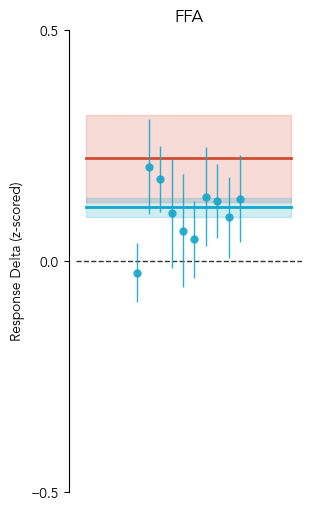

Plotting PPA...
Delta: Without humans - With humans


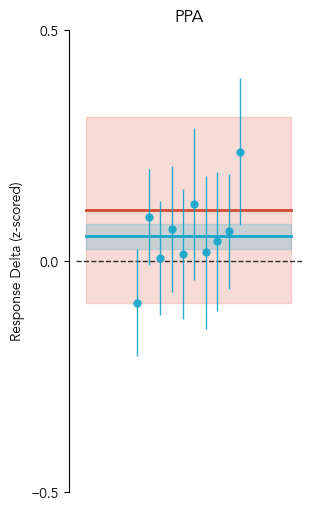

Plotting EBA...
Delta: Typical Bodies - Covered Atypical Poses


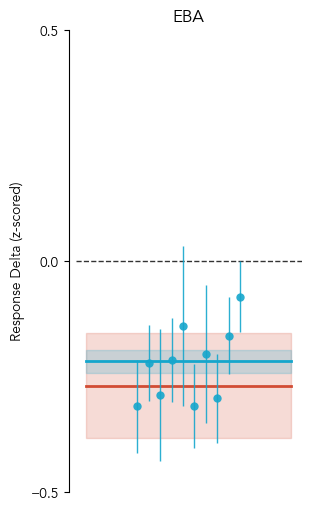

In [104]:
savefig = False
execute_lmm = False

froi_lims = {
    'FFA': [-0.5, 0.5],
    'PPA': [-0.5, 0.5],
    'EBA': [-0.5, 0.5],
}
froi_ticks = {
    'FFA': np.array([-0.5, 0, 0.5]),
    'PPA': np.array([-0.5, 0, 0.5]),
    'EBA': np.array([-0.5, 0, 0.5]),
}

subset = None # 515 for shared, None for subject-specific set
# x_system_offset = 0.2
# x_category_offset = 0.0425

subjects_color = '#d24c34'  # Red
models_color = '#15a6cc'    # Cyan

# for each froi
for froi in frois:
    bag_type = froi_bags[froi]
    lmm_output_file_path = f'{results_dir}/lmm_{froi}_bags_{bag_type}.txt'
    print(f'Plotting {froi}...')
    print(f'Delta: {bags[subjects[0]][bag_type]["bag1"]["label"]} - {bags[subjects[0]][bag_type]["bag2"]["label"]}')

    # Variables for storing bag responses
    models_bags_median_responses = {}
    subject_bags_median_responses = []

    randomly_selected_nsdids = {}

    # Subjects
    for subject in subjects:
        subject_bags = bags[subject]
        subject_selected_nsdids = []
        for bag_type in subject_bags:
            subject_selected_nsdids += (subject_bags[bag_type]['bag1']['nsdids'] + subject_bags[bag_type]['bag2']['nsdids'])
        selected_nsdids = [nsdids_ for bag in bags[subject][bag_type].values() for nsdids_ in bag['nsdids']]
        original_bag1_nsdids = bags[subject][bag_type]['bag1']['nsdids']
        original_bag2_nsdids = bags[subject][bag_type]['bag2']['nsdids']
        # Randomly select new bag nsdids from the subject's available nsdids,
        bag1_nstim = len(original_bag1_nsdids)
        bag2_nstim = len(original_bag2_nsdids)
        subject_all_nsdids = set(resp_df[(resp_df['subject'] == subject)]['nsd_id'].unique())
        subject_candidate_nsdids = list(subject_all_nsdids - set(subject_selected_nsdids))
        # np.random.seed(42)
        bag1_nsdids = np.random.choice(subject_candidate_nsdids, size=bag1_nstim, replace=False).tolist()
        remaining_candidate_nsdids = list(set(subject_candidate_nsdids) - set(bag1_nsdids))
        bag2_nsdids = np.random.choice(remaining_candidate_nsdids, size=bag2_nstim, replace=False).tolist()
        # if subject == subjects[0]:
        #     print(f'Subject {subject} random bag nsdids:')
        #     print(f'  Original Bag1 ({bags[subject][bag_type]["bag1"]["label"]}): {sorted(original_bag1_nsdids)}')
        #     print(f'  Bag1 ({bags[subject][bag_type]["bag1"]["label"]}): {sorted(bag1_nsdids)}')
        #     print(f'  Original Bag2 ({bags[subject][bag_type]["bag2"]["label"]}): {sorted(original_bag2_nsdids)}')
        #     print(f'  Bag2 ({bags[subject][bag_type]["bag2"]["label"]}): {sorted(bag2_nsdids)}')
        randomly_selected_nsdids[subject] = {
            'bag1': bag1_nsdids,
            'bag2': bag2_nsdids,
        }
        sbj_froi_mdl_subset_resp_df =resp_df[
            (resp_df['subject'] == subject) &
            (resp_df['froi'] == froi)
        ]
        subject_responses_bag1 = sbj_froi_mdl_subset_resp_df[
            sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_nsdids)
        ]['subject_response']
        subject_responses_bag2 = sbj_froi_mdl_subset_resp_df[
            sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_nsdids)
        ]['subject_response']
        subject_bags_median_responses.append([np.median(subject_responses_bag1), np.median(subject_responses_bag2)])
    subject_bags_median_responses = np.array(subject_bags_median_responses)

    # Models
    for model_name in TOP_MODEL_NAMES:
        # Skip resnet50imagenet1kv2 as it's the main model being compared
        if model_name == 'resnet50imagenet1kv2':
            continue
        model_bags_median_responses = []
        df = []
        for subject in subjects:
            bag1_nsdids = randomly_selected_nsdids[subject]['bag1']
            bag2_nsdids = randomly_selected_nsdids[subject]['bag2']
            sbj_froi_mdl_subset_resp_df =resp_df[
                (resp_df['subject'] == subject) &
                (resp_df['froi'] == froi)
            ]
            subject_responses_bag1 = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_nsdids)
            ]['subject_response']
            for pt in subject_responses_bag1:
                df.append({
                    'response': pt,
                    'system': 'subject',
                    'condition': bags[subject][bag_type]['bag1']['label'],
                    'subject': subject,
                })
            subject_responses_bag2 = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_nsdids)
            ]['subject_response']
            for pt in subject_responses_bag2:
                df.append({
                    'response': pt,
                    'system': 'subject',
                    'condition': bags[subject][bag_type]['bag2']['label'],
                    'subject': subject,
                })
            model_responses_bag1 = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_nsdids)
            ][f'{model_name}_response']
            for pt in model_responses_bag1:
                df.append({
                    'response': pt,
                    'system': model_name,
                    'condition': bags[subject][bag_type]['bag1']['label'],
                    'subject': subject,
                })
            model_responses_bag2 = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_nsdids)
            ][f'{model_name}_response']
            for pt in model_responses_bag2:
                df.append({
                    'response': pt,
                    'system': model_name,
                    'condition': bags[subject][bag_type]['bag2']['label'],
                    'subject': subject,
                })
            model_bags_median_responses.append([np.median(model_responses_bag1), np.median(model_responses_bag2)])
        models_bags_median_responses[model_name] = np.array(model_bags_median_responses)
    df = pd.DataFrame(df)
    if execute_lmm:
        run_lmm(df, lmm_output_file_path)
    
    # Stats: Wilcoxon signed-rank test
    # print(np.median(subjects_response_deltas_median), np.median(model_response_deltas_median))
    # stat, p_value = wilcoxon(subjects_response_deltas_median, model_response_deltas_median)
    # print(f'  Wilcoxon signed-rank test: statistic={stat}, p-value={p_value}')

    fig, axes = plt.subplots(1, 1, figsize=(3, 5), constrained_layout=True)
    y_lims = froi_lims[froi]
    y_ticks = froi_ticks[froi]

    ax = axes
    # Add a horizontal line at y=0
    ax.axhline(y=0, color='k', linestyle='--', linewidth=1, alpha=0.8)
    jitter_scale = 0.8

    # Draw a shaded area for subject delta ± SEM
    subjects_sem = sem(subject_bags_median_responses[:,0] - subject_bags_median_responses[:,1])
    subjects_median = np.median(subject_bags_median_responses[:,0]) - np.median(subject_bags_median_responses[:,1])
    ax.fill_between(
        x=[-jitter_scale, jitter_scale],
        y1=subjects_median - subjects_sem,
        y2=subjects_median + subjects_sem,
        color=subjects_color,
        alpha=0.2,
        # label='Subject Δ ± SEM',
    )
    # Draw a line for subject delta
    ax.plot(
        [-jitter_scale, jitter_scale],
        [subjects_median, subjects_median],
        color=subjects_color,
        linestyle='-',
        linewidth=2,
        # label='Subject Δ',
    )

    # Collect all model median deltas for plotting later
    all_models_median_deltas = []
    # For each model, plot a point with error bars
    x_jitter = np.linspace(-(jitter_scale/2), jitter_scale/2, len(models_bags_median_responses))
    for model_idx, (model_name, model_bags_median_responses) in enumerate(models_bags_median_responses.items()):
        model_sem = sem(model_bags_median_responses[:,0] - model_bags_median_responses[:,1])
        model_median = np.median(model_bags_median_responses[:,0]) - np.median(model_bags_median_responses[:,1])
        all_models_median_deltas.append(model_median)
        # Plot error bar
        ax.errorbar(
            x=x_jitter[model_idx],
            y=model_median,
            yerr=model_sem,
            fmt='o',
            color=models_color,
            markeredgewidth=0,
            ecolor=models_color,
            elinewidth=1,
            capsize=0,
            markersize=6,
            alpha=0.9,
        )
        # Plot point
        # ax.plot(
        #     0,
        #     model_median,
        #     'o',
        #     color=models_color,
        #     markersize=8,
        #     alpha=0.9,
        #     label=f'{model_name} Δ',
        # )
    
    collated_models_median = np.median(all_models_median_deltas)
    collated_models_sem = sem(all_models_median_deltas)
    # Draw a shaded area for all models delta ± SEM
    ax.fill_between(
        x=[-jitter_scale, jitter_scale],
        y1=collated_models_median - collated_models_sem,
        y2=collated_models_median + collated_models_sem,
        color=models_color,
        alpha=0.2,
        # label='Model Δ ± SEM',
    )
    # Draw a line for subject delta
    ax.plot(
        [-jitter_scale, jitter_scale],
        [collated_models_median, collated_models_median],
        color=models_color,
        linestyle='-',
        linewidth=2,
        # label='Model Δ',
    )

    # ax.legend(
    #     [
    #         box["boxes"][0],
    #         box["boxes"][1],
    #     ],
    #     box_labels,
    #     loc='best',
    #     fontsize=10,
    #     frameon=False,
    # )
    ax.set_xticks([])
    ax.set_xticklabels([])
    ax.set_ylim(y_lims)
    ax.set_yticks(y_ticks)
    ax.set_ylabel('Response Delta (z-scored)')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.spines['left'].set_position(('outward', 5))
    ax.spines['bottom'].set_position(('outward', 5))
    ax.spines['left'].set_bounds(y_ticks.min(), y_ticks.max())
    ax.spines['bottom'].set_bounds(0.5, 3.5)
    ax.get_xaxis().set_visible(False)
    # Title
    ax.set_title(froi)


    # plt.tight_layout()
    if savefig:
        plt.savefig(f'{plot_dir}/{froi}_subject2to8_heldoutmodels_bags_deltas.pdf', dpi=300, bbox_inches='tight')
    else:
        plt.show()
    plt.close()

### b, c, d: Old

In [5]:
# STIMULI = nsd.get_stimuli_dataset(NSD_DIR, transform=None, subset=None).all_stimuli

frois = ['FFA', 'PPA', 'EBA']
subjects = [2, 3, 4, 5, 6, 7, 8]  # NSD subjects
mean_zscored_responses_df_path = f'results/exploration/explore_interpret/subject_specific_mean_zscored_responses.csv'
resp_df = pd.read_csv(mean_zscored_responses_df_path)

froi_bags = {
    'FFA': 'faces',
    'PPA': 'scenes',
    'EBA': 'bodies',
}
model_color = '#944e1f' # Brown
subject_color = '#fde0c5' # Light peach

results_dir = f'{RESULTS_DIR}/fig6_stats'
os.makedirs(results_dir, exist_ok=True)

Plotting FFA...
Delta: Human Faces - Animal Faces
Results written to: results/fig6_stats/lmm_FFA_bags_faces.txt


/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


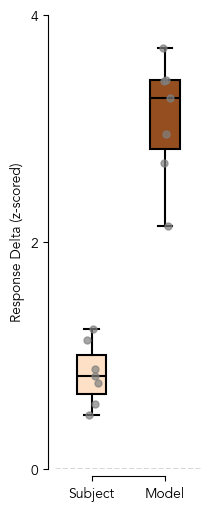

Results written to: results/fig6_stats/lmm_FFA_bags_faces.txt


/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


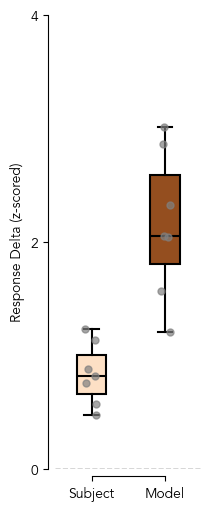

/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


Results written to: results/fig6_stats/lmm_FFA_bags_faces.txt


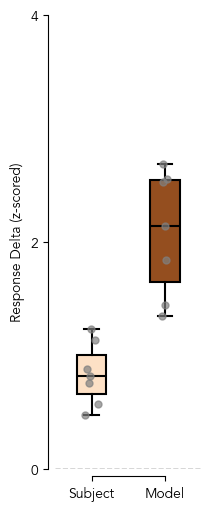

/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


Results written to: results/fig6_stats/lmm_FFA_bags_faces.txt


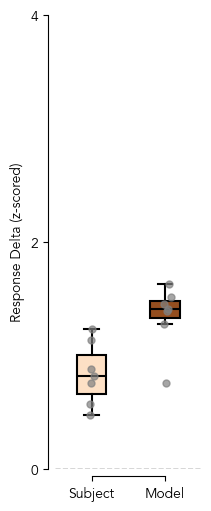

/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


Results written to: results/fig6_stats/lmm_FFA_bags_faces.txt


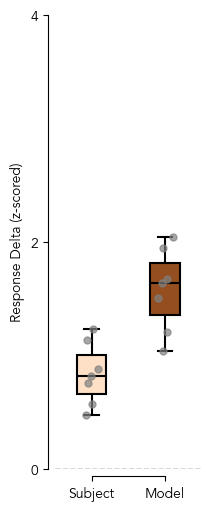

/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


Results written to: results/fig6_stats/lmm_FFA_bags_faces.txt


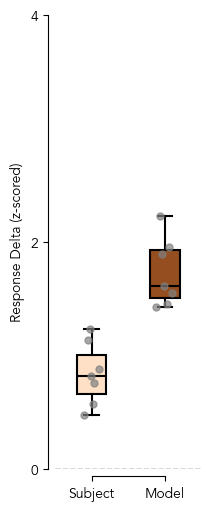

/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


Results written to: results/fig6_stats/lmm_FFA_bags_faces.txt


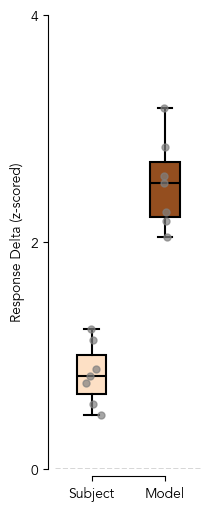

/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


Results written to: results/fig6_stats/lmm_FFA_bags_faces.txt


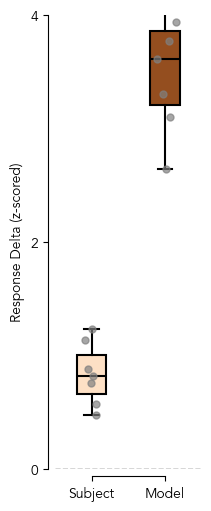

/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


Results written to: results/fig6_stats/lmm_FFA_bags_faces.txt


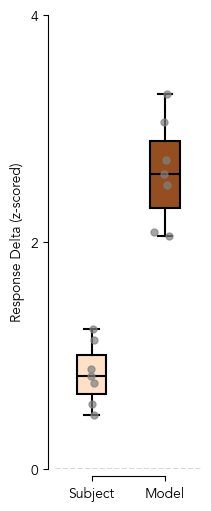

/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


Results written to: results/fig6_stats/lmm_FFA_bags_faces.txt


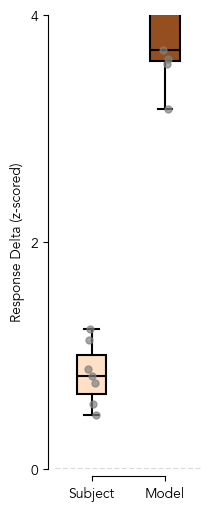

Results written to: results/fig6_stats/lmm_FFA_bags_faces.txt


/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


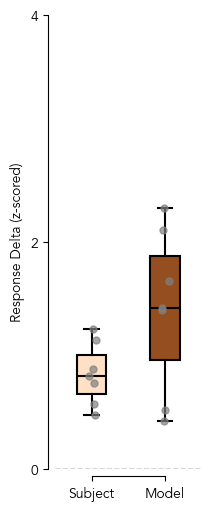

Plotting PPA...
Delta: Without humans - With humans
Results written to: results/fig6_stats/lmm_PPA_bags_scenes.txt


/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


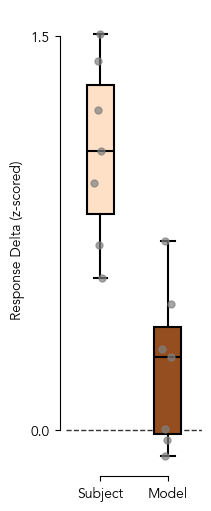

Results written to: results/fig6_stats/lmm_PPA_bags_scenes.txt


/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


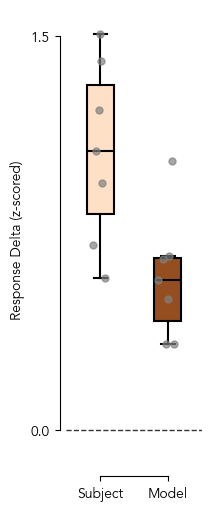

/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


Results written to: results/fig6_stats/lmm_PPA_bags_scenes.txt


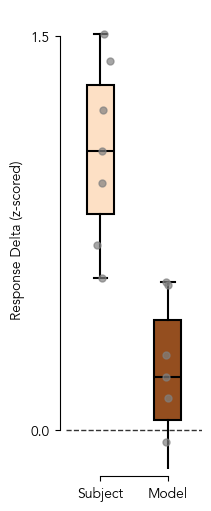

/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


Results written to: results/fig6_stats/lmm_PPA_bags_scenes.txt


/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


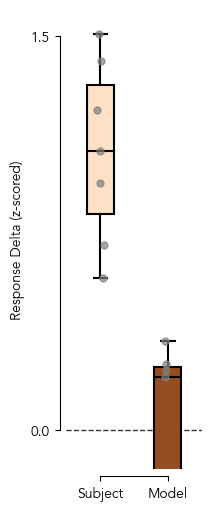

/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


Results written to: results/fig6_stats/lmm_PPA_bags_scenes.txt


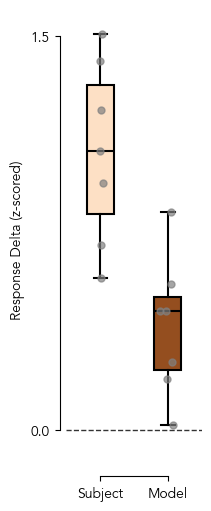

Results written to: results/fig6_stats/lmm_PPA_bags_scenes.txt


/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


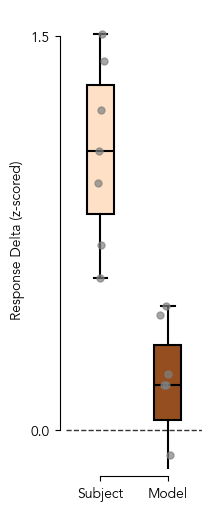

Results written to: results/fig6_stats/lmm_PPA_bags_scenes.txt


/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


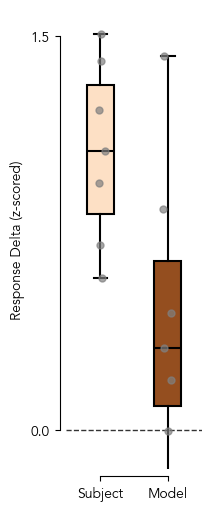

Results written to: results/fig6_stats/lmm_PPA_bags_scenes.txt


/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


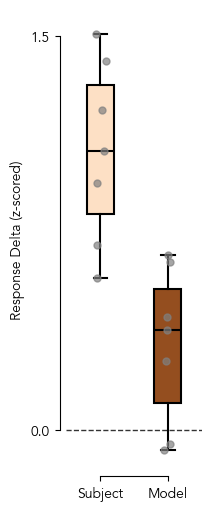

Results written to: results/fig6_stats/lmm_PPA_bags_scenes.txt


/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


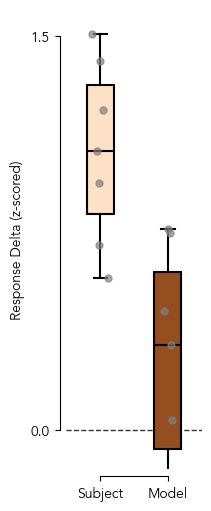

Results written to: results/fig6_stats/lmm_PPA_bags_scenes.txt


/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


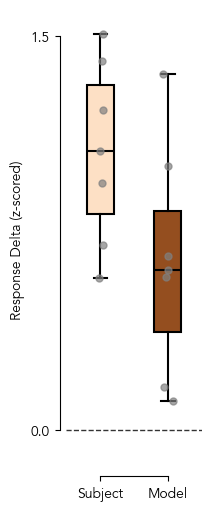

/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


Results written to: results/fig6_stats/lmm_PPA_bags_scenes.txt


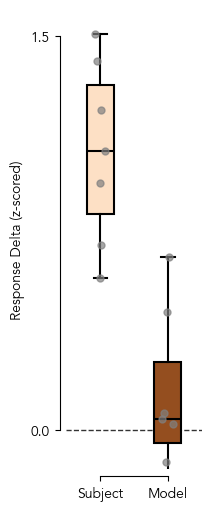

/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


Plotting EBA...
Delta: Typical Bodies - Covered Atypical Poses
Results written to: results/fig6_stats/lmm_EBA_bags_bodies.txt


/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


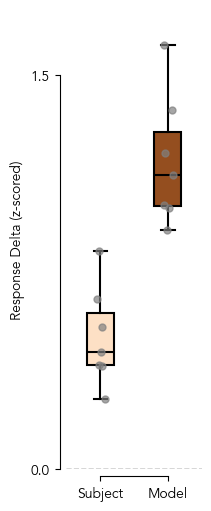

/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


Results written to: results/fig6_stats/lmm_EBA_bags_bodies.txt


/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


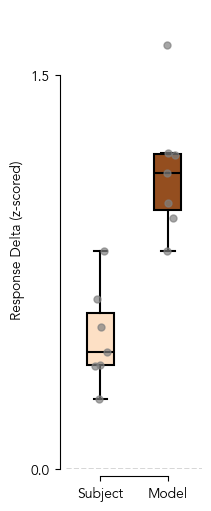

/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


Results written to: results/fig6_stats/lmm_EBA_bags_bodies.txt


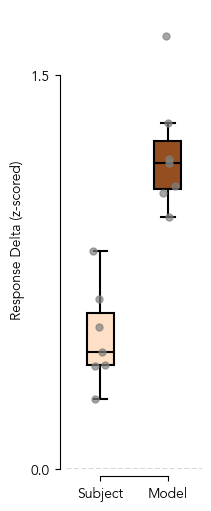

/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


Results written to: results/fig6_stats/lmm_EBA_bags_bodies.txt


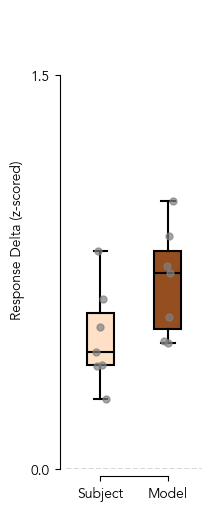

/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


Results written to: results/fig6_stats/lmm_EBA_bags_bodies.txt


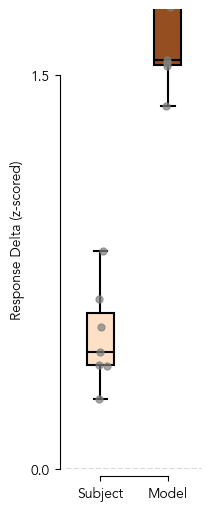

/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


Results written to: results/fig6_stats/lmm_EBA_bags_bodies.txt


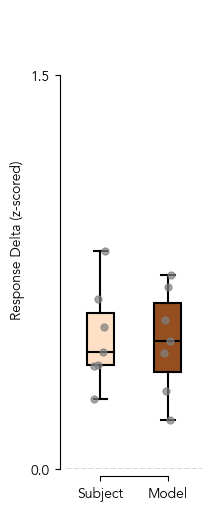

/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


Results written to: results/fig6_stats/lmm_EBA_bags_bodies.txt


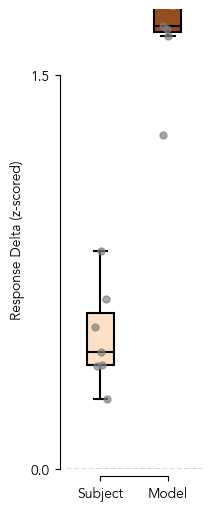

/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


Results written to: results/fig6_stats/lmm_EBA_bags_bodies.txt


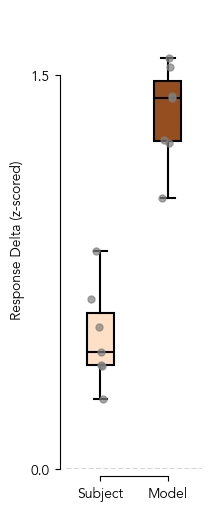

/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


Results written to: results/fig6_stats/lmm_EBA_bags_bodies.txt


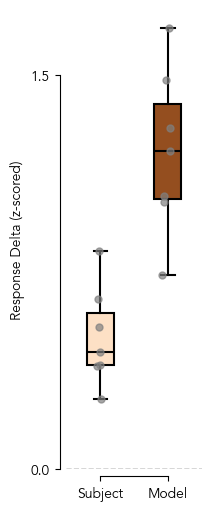

/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


Results written to: results/fig6_stats/lmm_EBA_bags_bodies.txt


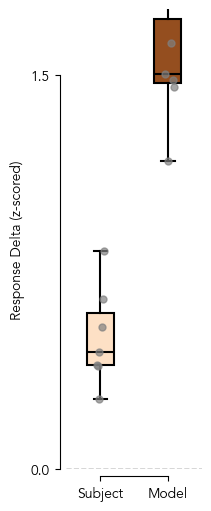

/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


Results written to: results/fig6_stats/lmm_EBA_bags_bodies.txt


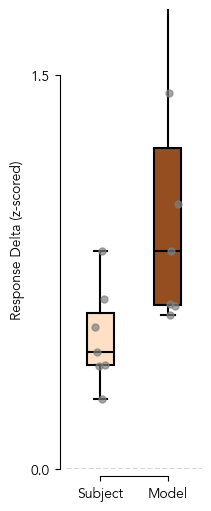

In [ ]:
savefig = False
execute_lmm = False

froi_lims = {
    'FFA': [0, 4],
    'PPA': [-0.15, 1.6],
    'EBA': [0, 1.75],
}
froi_ticks = {
    'FFA': np.array([0, 2, 4]),
    'PPA': np.array([0, 1.5]),
    'EBA': np.array([0, 1.5]),
}

model_name = 'resnet50imagenet1kv2'
subset = None # 515 for shared, None for subject-specific set
# x_system_offset = 0.2
# x_category_offset = 0.0425

for froi in frois:
    bag_type = froi_bags[froi]
    lmm_output_file_path = f'{results_dir}/lmm_{froi}_bags_{bag_type}.txt'
    print(f'Plotting {froi}...')
    print(f'Delta: {bags[subjects[0]][bag_type]["bag1"]["label"]} - {bags[subjects[0]][bag_type]["bag2"]["label"]}')
    for model_name in TOP_MODEL_NAMES:
        df = []
        fig, axes = plt.subplots(1, 1, figsize=(2, 5), constrained_layout=True)
        y_lims = froi_lims[froi]
        y_ticks = froi_ticks[froi]
        model_response_deltas_median = []
        # model_response_deltas_sem = []
        subjects_response_deltas_median = []
        # subjects_response_deltas_sem = []

        for subject in subjects:
            bag1_nsdids = bags[subject][bag_type]['bag1']['nsdids']
            bag2_nsdids = bags[subject][bag_type]['bag2']['nsdids']
            sbj_froi_mdl_subset_resp_df =resp_df[
                (resp_df['subject'] == subject) &
                (resp_df['froi'] == froi)
            ]
            subject_responses_bag1_ = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_nsdids)
            ]['subject_response']
            for pt in subject_responses_bag1_:
                df.append({
                    'response': pt,
                    'system': 'subject',
                    'condition': bags[subject][bag_type]['bag1']['label'],
                    'subject': subject,
                })
            subject_responses_bag2_ = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_nsdids)
            ]['subject_response']
            for pt in subject_responses_bag2_:
                df.append({
                    'response': pt,
                    'system': 'subject',
                    'condition': bags[subject][bag_type]['bag2']['label'],
                    'subject': subject,
                })
            # subject_point_sem = median_diff_bootstrap(
            #     np.array(subject_responses_bag1_),
            #     np.array(subject_responses_bag2_),
            # )['sem']
            subjects_response_deltas_median.append(np.median(subject_responses_bag1_) - np.median(subject_responses_bag2_))
            # subjects_response_deltas_sem.append(subject_point_sem)
            model_responses_bag1_ = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_nsdids)
            ][f'{model_name}_response']
            for pt in model_responses_bag1_:
                df.append({
                    'response': pt,
                    'system': model_name,
                    'condition': bags[subject][bag_type]['bag1']['label'],
                    'subject': subject,
                })
            model_responses_bag2_ = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_nsdids)
            ][f'{model_name}_response']
            for pt in model_responses_bag2_:
                df.append({
                    'response': pt,
                    'system': model_name,
                    'condition': bags[subject][bag_type]['bag2']['label'],
                    'subject': subject,
                })
            model_response_deltas_median.append(np.median(model_responses_bag1_) - np.median(model_responses_bag2_))
            # model_point_sem = median_diff_bootstrap(
            #     np.array(model_responses_bag1_),
            #     np.array(model_responses_bag2_),
            # )['sem']
            # model_response_deltas_sem.append(model_point_sem)
        df = pd.DataFrame(df)
        if execute_lmm:
            run_lmm(df, lmm_output_file_path)
        
        # Stats: Wilcoxon signed-rank test
        # print(np.median(subjects_response_deltas_median), np.median(model_response_deltas_median))
        # stat, p_value = wilcoxon(subjects_response_deltas_median, model_response_deltas_median)
        # print(f'  Wilcoxon signed-rank test: statistic={stat}, p-value={p_value}')

        ax = axes
        # Add a horizontal line at y=0
        ax.axhline(y=0, color='k', linestyle='--', linewidth=1, alpha=0.8)

        # Plot a boxplot of the response deltas, subjects and model
        box_data = [subjects_response_deltas_median, model_response_deltas_median]
        box_colors = [subject_color, model_color]
        box_labels = ['Subject', 'Model']
        box = ax.boxplot(
            box_data,
            positions=[0, 1],
            widths=0.4,
            patch_artist=True,
            medianprops=dict(color='black', linewidth=1.5),
            boxprops=dict(linewidth=1.5),
            whiskerprops=dict(linewidth=1.5),
            capprops=dict(linewidth=1.5),
            flierprops=dict(marker='o', color='gray', alpha=0.5, markersize=5, markeredgecolor='none')
        )
        for patch, color in zip(box['boxes'], box_colors):
            patch.set_facecolor(color)

        # Add individual data points with SEM error bars
        # for i, (y, sem) in enumerate(zip(box_data, [subjects_response_deltas_sem, model_response_deltas_sem])):
        #     x = np.random.normal(i, 0.05, size=len(y))  # Add some jitter to the x-axis
        #     ax.errorbar(x, y, yerr=sem, fmt='o', color='gray', alpha=0.7, markersize=5, capsize=0)
        for i, y in enumerate(box_data):
            x = np.random.normal(i, 0.05, size=len(y))  # Add some jitter to the x-axis
            ax.errorbar(x, y, fmt='o', color='gray', alpha=0.7, markersize=5, capsize=0)

        ax.set_xticks([0, 1])
        ax.set_xticklabels(box_labels)
        ax.set_ylim(y_lims)
        ax.set_yticks(y_ticks)
        ax.set_ylabel('Response Delta (z-scored)')
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_position(('outward', 5))
        ax.spines['bottom'].set_position(('outward', 5))
        ax.spines['left'].set_bounds(y_ticks.min(), y_ticks.max())
        ax.spines['bottom'].set_bounds(0, 1)

        # plt.tight_layout()
        if savefig:
            plt.savefig(f'{PLOTS_DIR}/fig6_lineplot_{froi}_{model_name}.pdf', dpi=300, bbox_inches='tight')
        else:
            plt.show()
        plt.close()

# Supplementary figures

## Fig S13: Hypothesis transfer

### Setup

In [20]:
# STIMULI = nsd.get_stimuli_dataset(NSD_DIR, transform=None, subset=None).all_stimuli

frois = ['FFA', 'EBA', 'PPA']
subjects = [2, 3, 4, 5, 6, 7, 8]  # NSD subjects
mean_zscored_responses_df_path = f'results/exploration/explore_interpret/subject_specific_mean_zscored_responses.csv'
resp_df = pd.read_csv(mean_zscored_responses_df_path)

froi_bags = {
    'FFA': 'faces',
    'EBA': 'bodies',
    'PPA': 'scenes',
}
# model_color = '#944e1f' # Brown
# subject_color = '#fde0c5' # Light peach

stats_dir = f'{PLOTS_DIR}/supplementary_figures/hypothesis_transfer/stats'
os.makedirs(stats_dir, exist_ok=True)

plot_dir = f'{PLOTS_DIR}/supplementary_figures/hypothesis_transfer'
os.makedirs(plot_dir, exist_ok=True)

dfs_dir = f'{stats_dir}/dataframes'
os.makedirs(dfs_dir, exist_ok=True)

human_color = '#d24c34' # Light peach
model_color = '#15a6cc' # Light blue

bags_successful_25samples_path = f'{BAGS_DIR}/bags_successful_25samples.json'
bags_successful_25samples, comparisons_25samples, bags_25samples = load_dict_from_json(bags_successful_25samples_path)
print_bags_statistics(bags_successful_25samples, comparisons_25samples, bags_25samples)

Loaded dict from interpretation_bags/bags_successful_25samples.json
Comparisons present: ['faces', 'bodies', 'scenes']
Bags present: ['human_faces', 'limbs_visible', 'with_humans', 'without_humans', 'limbs_covered', 'animal_faces']


,subject,human_faces,animal_faces,limbs_visible,limbs_covered,without_humans,with_humans
0,2,25,25,25,25,25,25
1,3,25,25,25,25,25,25
2,4,25,25,25,25,25,25
3,5,25,25,25,25,25,25
4,6,25,25,25,25,25,25
5,7,25,25,25,25,25,25
6,8,25,25,25,25,25,25


human_faces: Total=175, Mean=25.00, Std=0.00
limbs_visible: Total=175, Mean=25.00, Std=0.00
with_humans: Total=175, Mean=25.00, Std=0.00
without_humans: Total=175, Mean=25.00, Std=0.00
limbs_covered: Total=175, Mean=25.00, Std=0.00
animal_faces: Total=175, Mean=25.00, Std=0.00


### Stats

In [ ]:
execute_lmm = False

stimuli_bags = bags_successful_25samples
# comparions_25samples, bags_25samples
# ['limbs_covered', 'limbs_visible', 'with_humans', 'without_humans', 'animal_faces', 'human_faces']
bags_dict = {
    'FFA': ('faces', ['animal_faces', 'human_faces']),
    'EBA': ('bodies', ['limbs_covered', 'limbs_visible']),
    'PPA': ('scenes', ['without_humans', 'with_humans']),
}

# for each froi
for froi in frois:
    for cfroi in frois:
        comparison_type = bags_dict[cfroi][0]
        bag_type1, bag_type2 = bags_dict[cfroi][1]
        lmm_output_file_path = f'{stats_dir}/lmm_{froi}_comparison={comparison_type}_{bag_type1}_vs_{bag_type2}.txt'
        print(f'Stats for {froi}, comparison: {comparison_type} - {bag_type1} vs {bag_type2}...')
        # print(f'Delta: {bags[subjects[0]][bag_type]["bag1"]["label"]} - {bags[subjects[0]][bag_type]["bag2"]["label"]}')

        # Variables for storing bag responses
        models_bags_median_responses = {}
        subject_bags_median_responses = []

        # Models
        for model_name in ALL_MODEL_NAMES:
            model_bags_median_responses = []
            df = []
            for subject in subjects:
                bag1_nsdids = stimuli_bags[subject][comparison_type][bag_type1]
                bag2_nsdids = stimuli_bags[subject][comparison_type][bag_type2]
                sbj_froi_mdl_subset_resp_df = resp_df[
                    (resp_df['subject'] == subject) &
                    (resp_df['froi'] == froi)
                ]
                subject_responses_bag1 = sbj_froi_mdl_subset_resp_df[
                    sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_nsdids)
                ]['subject_response']
                if len(subject_responses_bag1) < 25:
                    missing_nsdids = set(bag1_nsdids) - set(sbj_froi_mdl_subset_resp_df['nsd_id'])
                    print(f'Subject {subject} - {bag_type1} - {len(subject_responses_bag1)} samples - Missing NSD IDs: {missing_nsdids}')
                    repeated = list({x for x in bag1_nsdids if bag1_nsdids.count(x) > 1})
                    print(f'Repeated NSD IDs: {repeated}')
                for pt in subject_responses_bag1:
                    df.append({
                        'response': pt,
                        'system': 'subject',
                        'condition': bag_type1,
                        'subject': subject,
                    })
                subject_responses_bag2 = sbj_froi_mdl_subset_resp_df[
                    sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_nsdids)
                ]['subject_response']
                if len(subject_responses_bag2) < 25:
                    missing_nsdids = set(bag2_nsdids) - set(sbj_froi_mdl_subset_resp_df['nsd_id'])
                    print(f'Subject {subject} - {bag_type2} - {len(subject_responses_bag2)} samples, Missing NSD IDs: {missing_nsdids}')
                    repeated = list({x for x in bag2_nsdids if bag2_nsdids.count(x) > 1})
                    print(f'Repeated NSD IDs: {repeated}')
                for pt in subject_responses_bag2:
                    df.append({
                        'response': pt,
                        'system': 'subject',
                        'condition': bag_type2,
                        'subject': subject,
                    })
                model_responses_bag1 = sbj_froi_mdl_subset_resp_df[
                    sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_nsdids)
                ][f'{model_name}_response']
                if len(model_responses_bag1) < 25:
                    missing_nsdids = set(bag1_nsdids) - set(sbj_froi_mdl_subset_resp_df['nsd_id'])
                    print(f'Model {model_name} - Subject {subject} - {bag_type1} - {len(model_responses_bag1)} samples, Missing NSD IDs: {missing_nsdids}')
                    repeated = list({x for x in bag1_nsdids if bag1_nsdids.count(x) > 1})
                    print(f'Repeated NSD IDs: {repeated}')
                for pt in model_responses_bag1:
                    df.append({
                        'response': pt,
                        'system': model_name,
                        'condition': bag_type1,
                        'subject': subject,
                    })
                model_responses_bag2 = sbj_froi_mdl_subset_resp_df[
                    sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_nsdids)
                ][f'{model_name}_response']
                if len(model_responses_bag2) < 25:
                    missing_nsdids = set(bag2_nsdids) - set(sbj_froi_mdl_subset_resp_df['nsd_id'])
                    print(f'Model {model_name} - Subject {subject} - {bag_type2} - {len(model_responses_bag2)} samples, Missing NSD IDs: {missing_nsdids}')
                    repeated = list({x for x in bag2_nsdids if bag2_nsdids.count(x) > 1})
                    print(f'Repeated NSD IDs: {repeated}')
                for pt in model_responses_bag2:
                    df.append({
                        'response': pt,
                        'system': model_name,
                        'condition': bag_type2,
                        'subject': subject,
                    })
                model_bags_median_responses.append([np.median(model_responses_bag1), np.median(model_responses_bag2)])
            models_bags_median_responses[model_name] = np.array(model_bags_median_responses)
            df = pd.DataFrame(df)
            if execute_lmm:
                run_lmm(df, lmm_output_file_path)
                # Save the dataframe used for the LMM
                df.to_csv(f'{dfs_dir}/{model_name}_{froi}_comparison={comparison_type}_{bag_type1}_vs_{bag_type2}.csv', index=False)
        #     break
        # break
        print('\n\n')

Stats for FFA, comparison: faces - animal_faces vs human_faces...


/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


Results written to: results/plots/preprint/section6/supplementary_figures/hypothesis_transfer/stats/lmm_FFA_comparison=faces_animal_faces_vs_human_faces.txt


/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


Results written to: results/plots/preprint/section6/supplementary_figures/hypothesis_transfer/stats/lmm_FFA_comparison=faces_animal_faces_vs_human_faces.txt


...

/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


Results written to: results/plots/preprint/section6/supplementary_figures/hypothesis_transfer/stats/lmm_PPA_comparison=scenes_without_humans_vs_with_humans.txt


/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


Results written to: results/plots/preprint/section6/supplementary_figures/hypothesis_transfer/stats/lmm_PPA_comparison=scenes_without_humans_vs_with_humans.txt
Results written to: results/plots/preprint/section6/supplementary_figures/hypothesis_transfer/stats/lmm_PPA_comparison=scenes_without_humans_vs_with_humans.txt





/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


### Plot

Processing FFA, comparison type: faces...
Maximum value across all models and subjects: 4.495260342857143, Minimum value across all models and subjects: 0.42831436142857143
Processing FFA, comparison type: bodies...
Maximum value across all models and subjects: 1.1723300857142858, Minimum value across all models and subjects: -0.49330136714285716
Processing FFA, comparison type: scenes...
Maximum value across all models and subjects: 0.9772997914285716, Minimum value across all models and subjects: -1.1491452071428572
Processing EBA, comparison type: faces...
Maximum value across all models and subjects: 0.43357842357142856, Minimum value across all models and subjects: -1.7546242714285716
Processing EBA, comparison type: bodies...
Maximum value across all models and subjects: 2.1674917714285713, Minimum value across all models and subjects: 0.060588431142857155
Processing EBA, comparison type: scenes...
Maximum value across all models and subjects: 1.4867566, Minimum value across all 

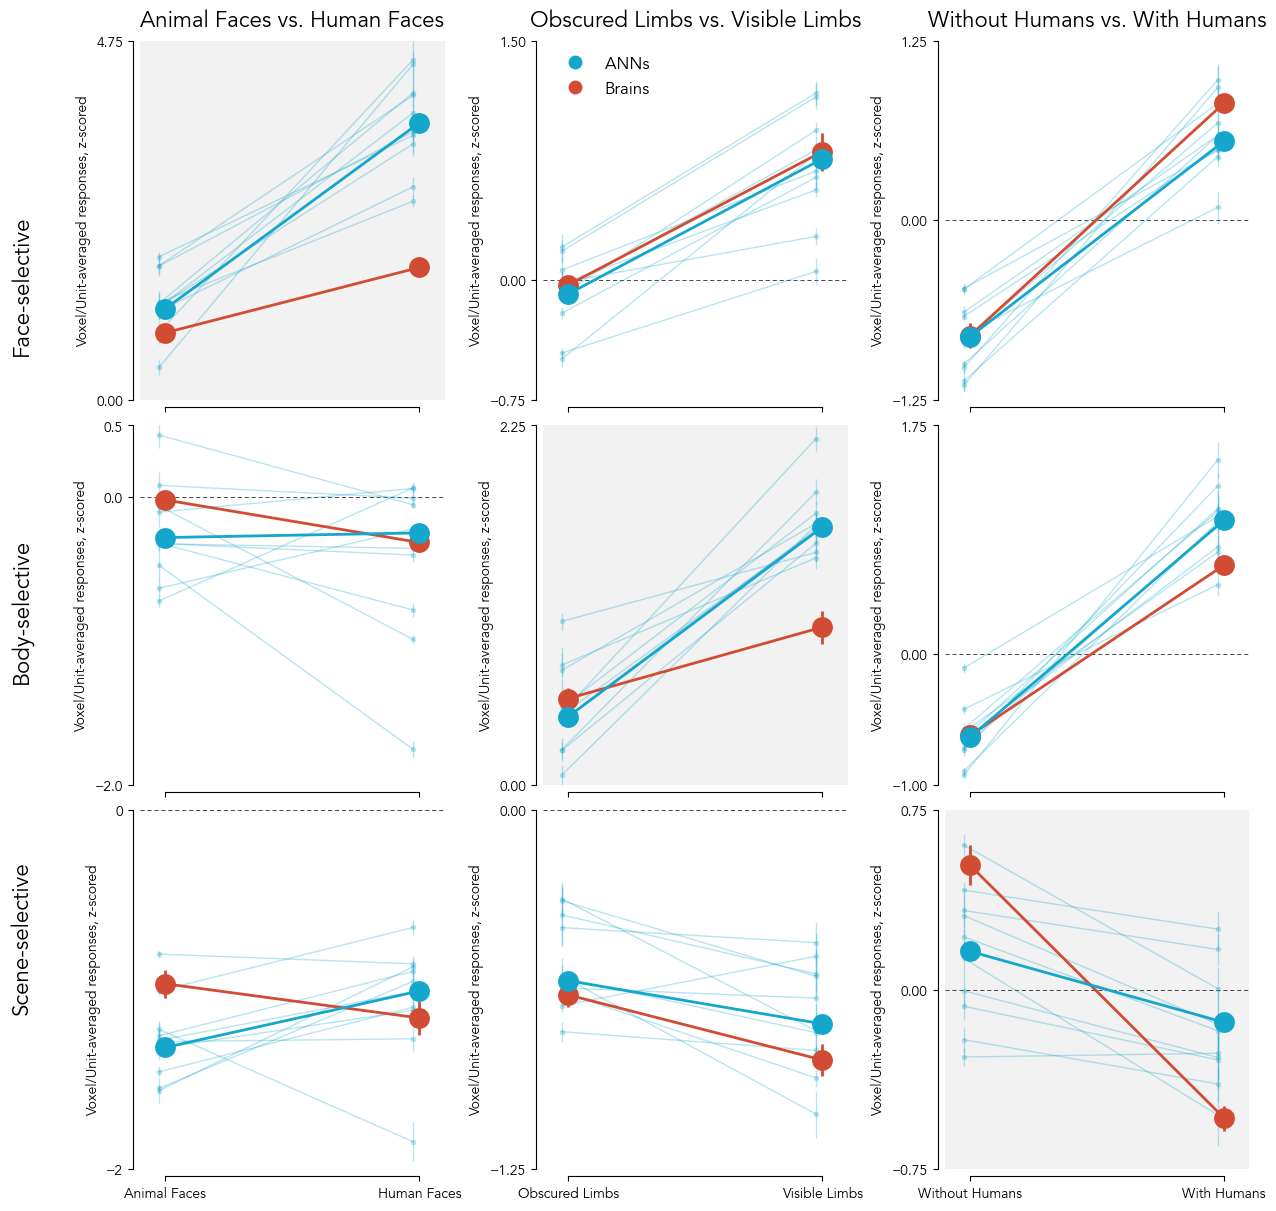

In [47]:
savefig = True
hide_y_info = False # Hide y-axis label and tick labels
figname = 'figS13_HypothesisTransfer.pdf' # TODO: 'fig6_models_brains_interpretation.pdf'

stimuli_bags = bags_successful_25samples
# comparions_25samples, bags_25samples
# ['limbs_covered', 'limbs_visible', 'with_humans', 'without_humans', 'animal_faces', 'human_faces']
bags_dict = {
    'FFA': ('faces', ['animal_faces', 'human_faces']),
    'EBA': ('bodies', ['limbs_covered', 'limbs_visible']),
    'PPA': ('scenes', ['without_humans', 'with_humans']),
}

bag_labels_dict = {
    'animal_faces': 'Animal Faces',
    'human_faces': 'Human Faces',
    'limbs_covered': 'Obscured Limbs',
    'limbs_visible': 'Visible Limbs',
    'without_humans': 'Without Humans',
    'with_humans': 'With Humans',
}
froi_y_labels_dict = {
    'FFA': 'Face-selective',
    'EBA': 'Body-selective',
    'PPA': 'Scene-selective',
}

fig, axes = plt.subplots(len(frois), len(frois), figsize=(4*len(frois), 4*len(frois)), constrained_layout=True)
show_errorbars = True
show_individual_points = False # Do show individual points to show the distribution across subjects, but not error bars since we have few subjects and they can be misleading
show_collated_model_median = True # In plot 2, make individual model points tiny and plot the median across models as a big point
assert (not show_individual_points) and (show_collated_model_median), "If showing individual points, we should not show the collated median, since the individual points will show the distribution across subjects. If not showing individual points, we should show the collated median to summarize the central tendency across subjects."
# Processing FFA, comparison type: faces...
# Maximum value across all models and subjects: 4.495260342857143, Minimum value across all models and subjects: 0.42831436142857143
# Processing FFA, comparison type: bodies...
# Maximum value across all models and subjects: 1.1723300857142858, Minimum value across all models and subjects: -0.49330136714285716
# Processing FFA, comparison type: scenes...
# Maximum value across all models and subjects: 0.9772997914285716, Minimum value across all models and subjects: -1.1491452071428572

# Processing EBA, comparison type: faces...
# Maximum value across all models and subjects: 0.43357842357142856, Minimum value across all models and subjects: -1.7546242714285716
# Processing EBA, comparison type: bodies...
# Maximum value across all models and subjects: 2.1674917714285713, Minimum value across all models and subjects: 0.060588431142857155
# Processing EBA, comparison type: scenes...
# Maximum value across all models and subjects: 1.4867566, Minimum value across all models and subjects: -0.9289107257142858

# Processing PPA, comparison type: faces...
# Maximum value across all models and subjects: -0.6531198042857141, Minimum value across all models and subjects: -1.8461885285714286
# Processing PPA, comparison type: bodies...
# Maximum value across all models and subjects: -0.3081453514285714, Minimum value across all models and subjects: -1.057798222857143
# Processing PPA, comparison type: scenes...
# Maximum value across all models and subjects: 0.6047176842857143, Minimum value across all models and subjects: -0.5358185985714286

plot_limits_dict = { # Keep it the same for plot 0 and 1 to allow slope interpretation,
    # For ylims, add a 1% offset to min to give some space below the lowest point, and set the max to accommodate the highest point across both plots
    'ylim': {
        'FFA': {
            'faces': [0, 4.75],
            'bodies': [-0.75, 1.5],
            'scenes': [-1.25, 1.25],
        },
        'EBA': {
            'faces': [-2, 0.5],
            'bodies': [0, 2.25],
            'scenes': [-1, 1.75],
        },
        'PPA': {
            'faces': [-2, 0],
            'bodies': [-1.25, 0],
            'scenes': [-0.75, 0.75],
        }, 
    }, # all min y-lims have a 0.05 offset to give some space below the lowest point, and all max y-lims are set to accommodate the highest point across both plots
    # 'yticks': {'FFA': np.array([0, 4.5]),'EBA': np.array([0, 2.25]),'PPA': np.array([-0.75, 0, 0.85])},
    'yticks': {
        'FFA': {
            'faces': np.array([0, 4.75]),
            'bodies': np.array([-0.75, 0, 1.5]),
            'scenes': np.array([-1.25, 0, 1.25]), # 1 or 1.23
        },
        'EBA': {
            'faces': np.array([-2, 0, 0.5]),
            'bodies': np.array([0, 2.25]),
            'scenes': np.array([-1, 0, 1.75]),
        },
        'PPA': {
            'faces': np.array([-2, 0]),
            'bodies': np.array([-1.25, 0]),
            'scenes': np.array([-0.75, 0, 0.75]),
        },
    },
}
plot_y_pad = 0.05
x_positions = np.array([0, 0.3])
plot_x_pad = (x_positions[1] - x_positions[0]) * 0.1 # 10% of the distance between the two collated points
jitter_collated_points = False
collated_points_offset = 0 #(x_positions[1] - x_positions[0]) * 0.025 # 2.5% of the distance between the two collated points
collated_points_alpha = 1 # 0.8
collated_points_marker_size = 15 # 10
collated_points_linewidth = 2
individual_points_offset = (x_positions[1] - x_positions[0]) * 0.025 # 2.5% # old: 1% beyond the collated points
individual_points_alpha = 0.3
individual_points_marker_size = 4
individual_points_linewidth = 1

from matplotlib.patches import Rectangle
for froi_idx, froi in enumerate(frois):
    for cidx, cfroi in enumerate(frois): # Comparison type
        ax_current = axes[froi_idx, cidx]
        if froi_idx == cidx: # Highlight the diagonal
            # ax_current.set_facecolor((0.5, 0.5, 0.5, 0.25)) # Light gray with some transparency
            rect = Rectangle(
                (0, 0), 1, 1,
                transform=ax_current.transAxes,
                facecolor=(0.5, 0.5, 0.5, 0.1),
                edgecolor='none',
                zorder=-50,     # behind everything
                clip_on=False
            )
            ax_current.add_patch(rect)
        bags_class, (bag1_type, bag2_type) = bags_dict[cfroi][0], (bags_dict[cfroi][1][0], bags_dict[cfroi][1][1])
        print(f'Processing {froi}, comparison type: {bags_class}...')
        bag_types_present = stimuli_bags[list(stimuli_bags.keys())[-1]][bags_class].keys()
        bag_types_passed = sorted([bag1_type, bag2_type])
        bag_types_loaded = sorted(bag_types_present)
        assert bag_types_passed == bag_types_loaded, f"Bag types passed ({bag_types_passed}) do not match bag types loaded ({bag_types_loaded})"

        # Plot 2: Brains vs. Top models
        # Only plot the mean across subjects for each bag, and connect the 2 points across bags with a line (no individual points)
        if jitter_collated_points:
            np.random.seed(42) # Set seed for reproducibility of jitter
            collated_points_x_jitter = np.random.uniform(-collated_points_offset * 0.5, collated_points_offset * 0.5, size=len(TOP_MODEL_NAMES))
            # Expand and copy across an extra dimension collated_points_x_jitter
            collated_points_x_jitter = np.expand_dims(collated_points_x_jitter, axis=1)
            collated_points_x_jitter = np.repeat(collated_points_x_jitter, repeats=2, axis=1)
        else:
            collated_points_x_jitter = np.zeros((len(TOP_MODEL_NAMES), 2))
        subject_points = [] # Reset subject points to avoid redundant computation across models
        all_model_points = [] # For show_collated_model_median
        all_means = [] # To figure out plot limits across all models and subjects
        for model_idx, model_name in enumerate(TOP_MODEL_NAMES):
            model_points = []
            for subject in range(2, 9):
                # Get the indices of the bag types in the original order
                bag1_nsdids = stimuli_bags[subject][bags_class][bag1_type]
                bag2_nsdids = stimuli_bags[subject][bags_class][bag2_type]
                assert len(bag1_nsdids) == 25, f"Expected 25 nsdids for bag1, got {len(bag1_nsdids)}"
                assert len(bag2_nsdids) == 25, f"Expected 25 nsdids for bag2, got {len(bag2_nsdids)}"
                model_responses_bag1_median = resp_df[
                                    (resp_df['subject'] == subject) &
                                    (resp_df['froi'] == froi) &
                                    (resp_df['nsd_id'].isin(bag1_nsdids))
                                ][f'{model_name}_response'].median()
                model_responses_bag2_median = resp_df[
                                    (resp_df['subject'] == subject) &
                                    (resp_df['froi'] == froi) &
                                    (resp_df['nsd_id'].isin(bag2_nsdids))
                                ][f'{model_name}_response'].median()
                model_points.append((model_responses_bag1_median, model_responses_bag2_median))
                if model_idx == 0: # Avoid redundant computation of subject responses across models
                    subject_responses_bag1_median = resp_df[
                                        (resp_df['subject'] == subject) &
                                        (resp_df['froi'] == froi) &
                                        (resp_df['nsd_id'].isin(bag1_nsdids))
                                    ]['subject_response'].median()
                    subject_responses_bag2_median = resp_df[
                                        (resp_df['subject'] == subject) &
                                        (resp_df['froi'] == froi) &
                                        (resp_df['nsd_id'].isin(bag2_nsdids))
                                    ]['subject_response'].median()
                    subject_points.append((subject_responses_bag1_median, subject_responses_bag2_median))
            all_model_points += model_points
            model_points = np.array(model_points)
            if model_idx == 0: # Avoid redundant computation of subject responses across models
                subject_points = np.array(subject_points)
                subject_means = subject_points.mean(axis=0)
                subject_sems = subject_points.std(axis=0) / np.sqrt(len(subject_points))
                all_means += subject_means.tolist()
            # x-axis = bags, y-axis = responses
            # first plot mean across subjects for each bag (+- SEM), and connect the 2 points across bags with a line
            model_means = model_points.mean(axis=0)
            model_sems = model_points.std(axis=0) / np.sqrt(len(model_points))
            all_means += model_means.tolist()
            # Model
            if show_collated_model_median:
                model_alpha_ = individual_points_alpha
                model_marker_size_ = individual_points_marker_size
                model_linewidth_ = individual_points_linewidth
                extra_offset = individual_points_offset
            else:
                model_alpha_ = collated_points_alpha
                model_marker_size_ = collated_points_marker_size
                model_linewidth_ = collated_points_linewidth
                extra_offset = 0
            if show_errorbars:
                ax_current.errorbar(
                    x_positions - collated_points_offset + collated_points_x_jitter[model_idx] - extra_offset,
                    model_means, yerr=model_sems, fmt='-o', color=model_color,
                    alpha=model_alpha_, markersize=model_marker_size_, linewidth=model_linewidth_,
                    mec='none', mew=0
                )
            else:
                ax_current.plot(
                    x_positions - collated_points_offset + collated_points_x_jitter[model_idx] - extra_offset,
                    model_means, 'o-', color=model_color,
                    alpha=model_alpha_, markersize=model_marker_size_, linewidth=model_linewidth_,
                    mec='none', mew=0
                )
        print(f'Maximum value across all models and subjects: {max(all_means)}, Minimum value across all models and subjects: {min(all_means)}')
        # Subject
        if show_errorbars:
            ax_current.errorbar(
                x_positions + collated_points_offset, subject_means, yerr=subject_sems,
                fmt='-o', color=human_color,
                alpha=collated_points_alpha, markersize=collated_points_marker_size,
                linewidth=collated_points_linewidth, mec='none', mew=0, zorder=9
            )
        else:
            ax_current.plot(
                x_positions + collated_points_offset, subject_means, 'o-', color=human_color,
                alpha=collated_points_alpha, markersize=collated_points_marker_size,
                linewidth=collated_points_linewidth, mec='none', mew=0, zorder=9
            )
        if show_collated_model_median:
            all_model_points = np.array(all_model_points)
            collated_model_median = np.median(all_model_points, axis=0)
            ax_current.plot(
                x_positions - collated_points_offset, collated_model_median, 'o-', color=model_color,
                markersize=collated_points_marker_size, alpha=collated_points_alpha,
                linewidth=collated_points_linewidth, mec='none', mew=0, zorder=10
            )
        ax_current.axhline(
                y=0, color='k', alpha=1, linewidth=0.5, zorder=-10,
                linestyle=(0, (6, 4))  # (offset, (dash_length, gap_length))
            )
        ax_current.set_xticks(x_positions)
        if froi_idx == len(frois) - 1: # Only set x-tick labels for the bottom row
            ax_current.set_xticklabels([bag_labels_dict[bag1_type], bag_labels_dict[bag2_type]])
        else:
            ax_current.set_xticklabels([])
        if froi_idx == 0: # Add title for comparison type on the top row
            ax_current.set_title(
                f'{bag_labels_dict[bag1_type]} vs. {bag_labels_dict[bag2_type]}',
                fontsize=16, fontweight='bold', pad=10
            )
        if cidx == 0: # Add froi label for the first column
            pos = ax_current.get_position()
            y_center = pos.y0 + pos.height / 2
            fig.text(
                -0.05,
                y_center,
                froi_y_labels_dict[froi],
                va='center',
                rotation='vertical',
                fontsize=16,
                fontweight='bold'
            )
        if hide_y_info:
            ax_current.set_yticklabels([])
            ax_current.set_ylabel('')
        else:
            ax_current.set_ylabel('Voxel/Unit-averaged responses, z-scored')
        if froi_idx == 0 and cidx == 1: # Only add legend for the first subplot to avoid redundancy
            # For legend, plot a model_color point and a human_color point with the same markersize and linewidth as in the plot, and use those for the legend entries
            ax_current.plot([], [], 'o', color=model_color, label='ANNs', markersize=collated_points_marker_size/1.5, linewidth=collated_points_linewidth, mec='none', mew=0)
            ax_current.plot([], [], 'o', color=human_color, label='Brains', markersize=collated_points_marker_size/1.5, linewidth=collated_points_linewidth, mec='none', mew=0)
            ax_current.legend(loc='upper left', frameon=False, fontsize=12)
        # ax_current.set_title(f'{froi} - {bag1_type.replace("_", " ").title()} vs. {bag2_type.replace("_", " ").title()}')
        # ax_current.legend()
        ax_current.set_ylim(plot_limits_dict['ylim'][froi][bags_class])
        ax_current.set_yticks(plot_limits_dict['yticks'][froi][bags_class])
        ax_current.spines['top'].set_visible(False)
        ax_current.spines['right'].set_visible(False)
        ax_current.spines['bottom'].set_position(('outward', 5))
        ax_current.spines['bottom'].set_bounds(x_positions)
        ax_current.spines['left'].set_position(('outward', 5))
        ax_current.spines['left'].set_bounds(
            (
                np.min(plot_limits_dict['yticks'][froi][bags_class]),
                np.max(plot_limits_dict['yticks'][froi][bags_class])
            )
        )
        ax_current.set_xlim(x_positions[0] - plot_x_pad, x_positions[1] + plot_x_pad)

# plt.tight_layout()
if savefig:
    plt.savefig(f'{plot_dir}/{figname}', dpi=300, transparent=True, bbox_inches='tight')
plt.show()
print('\n\n')

## Fig S14: Alternate hypotheses

### Setup

In [51]:
# STIMULI = nsd.get_stimuli_dataset(NSD_DIR, transform=None, subset=None).all_stimuli

frois = ['FFA', 'EBA', 'PPA']
subjects = [2, 3, 4, 5, 6, 7, 8]  # NSD subjects
mean_zscored_responses_df_path = f'results/exploration/explore_interpret/subject_specific_mean_zscored_responses.csv'
resp_df = pd.read_csv(mean_zscored_responses_df_path)

froi_bags = {
    'FFA': 'faces',
    'EBA': 'bodies',
    'PPA': 'scenes',
}
# model_color = '#944e1f' # Brown
# subject_color = '#fde0c5' # Light peach

stats_dir = f'{PLOTS_DIR}/supplementary_figures/extra_hypothesis/stats'
os.makedirs(stats_dir, exist_ok=True)

plot_dir = f'{PLOTS_DIR}/supplementary_figures/extra_hypothesis'
os.makedirs(plot_dir, exist_ok=True)

dfs_dir = f'{stats_dir}/dataframes'
os.makedirs(dfs_dir, exist_ok=True)

human_color = '#d24c34' # Light peach
model_color = '#15a6cc' # Light blue

bags_extra_25samples_path = f'{BAGS_DIR}/bags_extra_25samples.json'
bags_extra_25samples, comparisons_extra_25samples, bags_extra_25samples_names = load_dict_from_json(bags_extra_25samples_path)
print_bags_statistics(bags_extra_25samples, comparisons_extra_25samples, bags_extra_25samples_names)

Loaded dict from interpretation_bags/bags_extra_25samples.json
Comparisons present: ['faces', 'bodies', 'scenes']
Bags present: ['human_bodies', 'human_faces', 'animal_bodies', 'low_navigational_affordance', 'high_navigational_affordance']


,subject,human_faces,human_bodies,animal_bodies,high_navigational_affordance,low_navigational_affordance
0,2,25,25,25,25,25
1,3,25,25,25,25,25
2,4,25,25,25,25,25
3,5,25,25,25,25,25
4,6,25,25,25,25,25
5,7,25,25,25,25,25
6,8,25,25,25,25,25


human_bodies: Total=175, Mean=25.00, Std=0.00
human_faces: Total=175, Mean=25.00, Std=0.00
animal_bodies: Total=175, Mean=25.00, Std=0.00
low_navigational_affordance: Total=175, Mean=25.00, Std=0.00
high_navigational_affordance: Total=175, Mean=25.00, Std=0.00


### Stimuli

In [ ]:
# Store the stimuli for the bags in a folder structure for easy access during figure making

store_stimuli = False
stimuli_bags = bags_extra_25samples
if store_stimuli:
    all_stimuli, _ = nsd.get_subset_stimuli(NSD_DIR, None)
    # Loop over subjects 2-8, make a folder
    # For Faces and scenes_perspective, loop over bags, make a folder for them
    # Save the first 3 images from each bag
    for subject in range(2, 9):
        subject_dir = f'{plot_dir}/stimuli/subject_{subject}'
        os.makedirs(subject_dir, exist_ok=True)
        for category in ['faces', 'scenes', 'bodies']:
            category_dir = f'{subject_dir}/{category}'
            os.makedirs(category_dir, exist_ok=True)
            for bag_label, bag_nsdids in stimuli_bags[subject][category].items():
                bag_dir = f'{category_dir}/{bag_label}'
                os.makedirs(bag_dir, exist_ok=True)
                for nsd_id in bag_nsdids:
                    img = all_stimuli[nsd_id]
                    # Save the image as a jpg
                    img = Image.fromarray(img)
                    img.save(f'{bag_dir}/{nsd_id}.jpg')
                    # print(f"Saved image {nsd_id} to {bag_dir}/{nsd_id}.jpg")

### Stats

In [53]:
execute_lmm = False

stimuli_bags = bags_extra_25samples
# Bags present: ['human_bodies', 'human_faces', 'animal_bodies', 'low_navigational_affordance', 'high_navigational_affordance']
bags_dict = {
    'FFA': ('faces', ['human_bodies', 'human_faces']),
    'EBA': ('bodies', ['animal_bodies', 'human_bodies']),
    'PPA': ('scenes', ['low_navigational_affordance', 'high_navigational_affordance']),
}

# for each froi
for froi in frois:
    for cfroi in frois:
        comparison_type = bags_dict[cfroi][0]
        bag_type1, bag_type2 = bags_dict[cfroi][1]
        lmm_output_file_path = f'{stats_dir}/lmm_{froi}_comparison={comparison_type}_{bag_type1}_vs_{bag_type2}.txt'
        print(f'Stats for {froi}, comparison: {comparison_type} - {bag_type1} vs {bag_type2}...')
        # print(f'Delta: {bags[subjects[0]][bag_type]["bag1"]["label"]} - {bags[subjects[0]][bag_type]["bag2"]["label"]}')

        # Variables for storing bag responses
        models_bags_median_responses = {}
        subject_bags_median_responses = []

        # Models
        for model_name in ALL_MODEL_NAMES:
            model_bags_median_responses = []
            df = []
            for subject in subjects:
                bag1_nsdids = stimuli_bags[subject][comparison_type][bag_type1]
                bag2_nsdids = stimuli_bags[subject][comparison_type][bag_type2]
                sbj_froi_mdl_subset_resp_df = resp_df[
                    (resp_df['subject'] == subject) &
                    (resp_df['froi'] == froi)
                ]
                subject_responses_bag1 = sbj_froi_mdl_subset_resp_df[
                    sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_nsdids)
                ]['subject_response']
                if len(subject_responses_bag1) < 25:
                    missing_nsdids = set(bag1_nsdids) - set(sbj_froi_mdl_subset_resp_df['nsd_id'])
                    print(f'Subject {subject} - {bag_type1} - {len(subject_responses_bag1)} samples - Missing NSD IDs: {missing_nsdids}')
                    repeated = list({x for x in bag1_nsdids if bag1_nsdids.count(x) > 1})
                    print(f'Repeated NSD IDs: {repeated}')
                for pt in subject_responses_bag1:
                    df.append({
                        'response': pt,
                        'system': 'subject',
                        'condition': bag_type1,
                        'subject': subject,
                    })
                subject_responses_bag2 = sbj_froi_mdl_subset_resp_df[
                    sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_nsdids)
                ]['subject_response']
                if len(subject_responses_bag2) < 25:
                    missing_nsdids = set(bag2_nsdids) - set(sbj_froi_mdl_subset_resp_df['nsd_id'])
                    print(f'Subject {subject} - {bag_type2} - {len(subject_responses_bag2)} samples, Missing NSD IDs: {missing_nsdids}')
                    repeated = list({x for x in bag2_nsdids if bag2_nsdids.count(x) > 1})
                    print(f'Repeated NSD IDs: {repeated}')
                for pt in subject_responses_bag2:
                    df.append({
                        'response': pt,
                        'system': 'subject',
                        'condition': bag_type2,
                        'subject': subject,
                    })
                model_responses_bag1 = sbj_froi_mdl_subset_resp_df[
                    sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_nsdids)
                ][f'{model_name}_response']
                if len(model_responses_bag1) < 25:
                    missing_nsdids = set(bag1_nsdids) - set(sbj_froi_mdl_subset_resp_df['nsd_id'])
                    print(f'Model {model_name} - Subject {subject} - {bag_type1} - {len(model_responses_bag1)} samples, Missing NSD IDs: {missing_nsdids}')
                    repeated = list({x for x in bag1_nsdids if bag1_nsdids.count(x) > 1})
                    print(f'Repeated NSD IDs: {repeated}')
                for pt in model_responses_bag1:
                    df.append({
                        'response': pt,
                        'system': model_name,
                        'condition': bag_type1,
                        'subject': subject,
                    })
                model_responses_bag2 = sbj_froi_mdl_subset_resp_df[
                    sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_nsdids)
                ][f'{model_name}_response']
                if len(model_responses_bag2) < 25:
                    missing_nsdids = set(bag2_nsdids) - set(sbj_froi_mdl_subset_resp_df['nsd_id'])
                    print(f'Model {model_name} - Subject {subject} - {bag_type2} - {len(model_responses_bag2)} samples, Missing NSD IDs: {missing_nsdids}')
                    repeated = list({x for x in bag2_nsdids if bag2_nsdids.count(x) > 1})
                    print(f'Repeated NSD IDs: {repeated}')
                for pt in model_responses_bag2:
                    df.append({
                        'response': pt,
                        'system': model_name,
                        'condition': bag_type2,
                        'subject': subject,
                    })
                model_bags_median_responses.append([np.median(model_responses_bag1), np.median(model_responses_bag2)])
            models_bags_median_responses[model_name] = np.array(model_bags_median_responses)
            df = pd.DataFrame(df)
            if execute_lmm:
                run_lmm(df, lmm_output_file_path)
                # Save the dataframe used for the LMM
                df.to_csv(f'{dfs_dir}/{model_name}_{froi}_comparison={comparison_type}_{bag_type1}_vs_{bag_type2}.csv', index=False)
        #     break
        # break
        print('\n\n')

Stats for FFA, comparison: faces - human_bodies vs human_faces...


/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


Results written to: results/plots/preprint/section6/supplementary_figures/extra_hypothesis/stats/lmm_FFA_comparison=faces_human_bodies_vs_human_faces.txt


/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


Results written to: results/plots/preprint/section6/supplementary_figures/extra_hypothesis/stats/lmm_FFA_comparison=faces_human_bodies_vs_human_faces.txt


...

/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


Results written to: results/plots/preprint/section6/supplementary_figures/extra_hypothesis/stats/lmm_PPA_comparison=scenes_low_navigational_affordance_vs_high_navigational_affordance.txt
Subject 5 - high_navigational_affordance - 24 samples, Missing NSD IDs: set()
Repeated NSD IDs: [7895]
Model resnet101imagenet1kv1 - Subject 5 - high_navigational_affordance - 24 samples, Missing NSD IDs: set()
Repeated NSD IDs: [7895]


/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


Results written to: results/plots/preprint/section6/supplementary_figures/extra_hypothesis/stats/lmm_PPA_comparison=scenes_low_navigational_affordance_vs_high_navigational_affordance.txt
Subject 5 - high_navigational_affordance - 24 samples, Missing NSD IDs: set()
Repeated NSD IDs: [7895]
Model vitb14dinov2 - Subject 5 - high_navigational_affordance - 24 samples, Missing NSD IDs: set()
Repeated NSD IDs: [7895]
Results written to: results/plots/preprint/section6/supplementary_figures/extra_hypothesis/stats/lmm_PPA_comparison=scenes_low_navigational_affordance_vs_high_navigational_affordance.txt





/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2206: ConvergenceWarning: MixedLM optimization failed, trying a different optimizer may help.
  warnings.warn(msg, ConvergenceWarning)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2218: ConvergenceWarning: Gradient optimization failed, |grad| = 6.116462
  warnings.warn(msg, ConvergenceWarning)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)

### Plot

Processing FFA, comparison type: faces...
Maximum value across all models and subjects: 4.495260342857143, Minimum value across all models and subjects: 0.05468563270000003
Processing FFA, comparison type: bodies...
Maximum value across all models and subjects: 1.1723300857142858, Minimum value across all models and subjects: -0.18490879814285716
Processing FFA, comparison type: scenes...
Maximum value across all models and subjects: -0.26707488214285713, Minimum value across all models and subjects: -0.8532566007142857
Processing EBA, comparison type: faces...
Maximum value across all models and subjects: 2.1674917714285713, Minimum value across all models and subjects: -1.7546242714285716
Processing EBA, comparison type: bodies...
Maximum value across all models and subjects: 2.1674917714285713, Minimum value across all models and subjects: -0.3600128314285715
Processing EBA, comparison type: scenes...
Maximum value across all models and subjects: -0.42797380285714287, Minimum value 

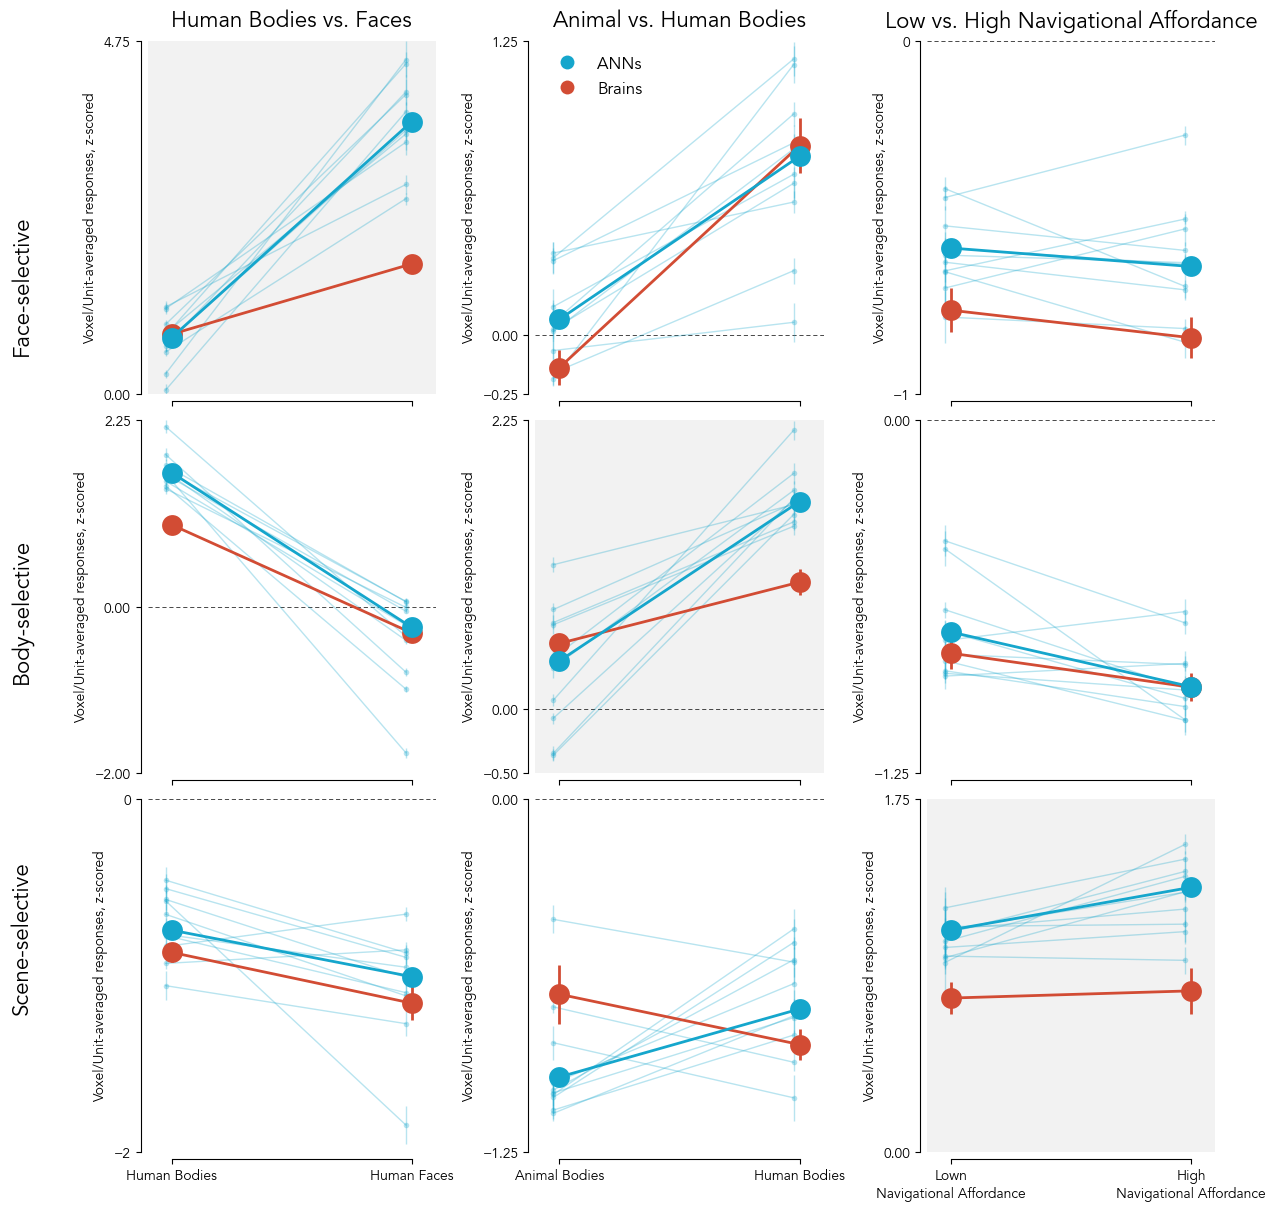

In [58]:
savefig = True
hide_y_info = False # Hide y-axis label and tick labels
figname = 'figS14_ExtraHypotheses.pdf'

stimuli_bags = bags_extra_25samples
# Comparisons present: ['faces', 'bodies', 'scenes']
# Bags present: ['human_bodies', 'human_faces', 'animal_bodies', 'low_navigational_affordance', 'high_navigational_affordance']
bags_dict = {
    'FFA': ('faces', ['human_bodies', 'human_faces']),
    'EBA': ('bodies', ['animal_bodies', 'human_bodies']),
    'PPA': ('scenes', ['low_navigational_affordance', 'high_navigational_affordance']),
}

bag_labels_dict = {
    'human_bodies': 'Human Bodies',
    'human_faces': 'Human Faces',
    'animal_bodies': 'Animal Bodies',
    'low_navigational_affordance': 'Lown\nNavigational Affordance',
    'high_navigational_affordance': 'High\nNavigational Affordance',
}
froi_y_labels_dict = {
    'FFA': 'Face-selective',
    'EBA': 'Body-selective',
    'PPA': 'Scene-selective',
}
comparison_titles_dict = {
    'faces': 'Human Bodies vs. Faces',
    'bodies': 'Animal vs. Human Bodies',
    'scenes': 'Low vs. High Navigational Affordance',
}

fig, axes = plt.subplots(len(frois), len(frois), figsize=(4*len(frois), 4*len(frois)), constrained_layout=True)
show_errorbars = True
show_individual_points = False # Do show individual points to show the distribution across subjects, but not error bars since we have few subjects and they can be misleading
show_collated_model_median = True # In plot 2, make individual model points tiny and plot the median across models as a big point
assert (not show_individual_points) and (show_collated_model_median), "If showing individual points, we should not show the collated median, since the individual points will show the distribution across subjects. If not showing individual points, we should show the collated median to summarize the central tendency across subjects."
# Processing FFA, comparison type: faces...
# Maximum value across all models and subjects: 4.495260342857143, Minimum value across all models and subjects: 0.05468563270000003
# Processing FFA, comparison type: bodies...
# Maximum value across all models and subjects: 1.1723300857142858, Minimum value across all models and subjects: -0.18490879814285716
# Processing FFA, comparison type: scenes...
# Maximum value across all models and subjects: -0.26707488214285713, Minimum value across all models and subjects: -0.8532566007142857

# Processing EBA, comparison type: faces...
# Maximum value across all models and subjects: 2.1674917714285713, Minimum value across all models and subjects: -1.7546242714285716
# Processing EBA, comparison type: bodies...
# Maximum value across all models and subjects: 2.1674917714285713, Minimum value across all models and subjects: -0.3600128314285715
# Processing EBA, comparison type: scenes...
# Maximum value across all models and subjects: -0.42797380285714287, Minimum value across all models and subjects: -1.0632536785714286

# Processing PPA, comparison type: faces...
# Maximum value across all models and subjects: -0.46085486428571426, Minimum value across all models and subjects: -1.8461885285714286
# Processing PPA, comparison type: bodies...
# Maximum value across all models and subjects: -0.42660323714285714, Minimum value across all models and subjects: -1.1124851428571427
# Processing PPA, comparison type: scenes...
# Maximum value across all models and subjects: 1.5238920214285716, Minimum value across all models and subjects: 0.7629906614285714

plot_limits_dict = { # Keep it the same for plot 0 and 1 to allow slope interpretation,
    # For ylims, add a 1% offset to min to give some space below the lowest point, and set the max to accommodate the highest point across both plots
    'ylim': {
        'FFA': {
            'faces': [0, 4.75],
            'bodies': [-0.25, 1.25],
            'scenes': [-1, 0],
        },
        'EBA': {
            'faces': [-2, 2.25],
            'bodies': [-0.5, 2.25],
            'scenes': [-1.25, 0],
        },
        'PPA': {
            'faces': [-2, 0],
            'bodies': [-1.25, 0],
            'scenes': [0, 1.75],
        }, 
    }, # all min y-lims have a 0.05 offset to give some space below the lowest point, and all max y-lims are set to accommodate the highest point across both plots
    # 'yticks': {'FFA': np.array([0, 4.5]),'EBA': np.array([0, 2.25]),'PPA': np.array([-0.75, 0, 0.85])},
    'yticks': {
        'FFA': {
            'faces': np.array([0, 4.75]),
            'bodies': np.array([-0.25, 0, 1.25]),
            'scenes': np.array([-1, 0]),
        },
        'EBA': {
            'faces': np.array([-2, 0, 2.25]),
            'bodies': np.array([-0.5, 0, 2.25]),
            'scenes': np.array([-1.25, 0]),
        },
        'PPA': {
            'faces': np.array([-2, 0]),
            'bodies': np.array([-1.25, 0]),
            'scenes': np.array([0, 1.75]),
        },
    },
}
plot_y_pad = 0.05
x_positions = np.array([0, 0.3])
plot_x_pad = (x_positions[1] - x_positions[0]) * 0.1 # 10% of the distance between the two collated points
jitter_collated_points = False
collated_points_offset = 0 #(x_positions[1] - x_positions[0]) * 0.025 # 2.5% of the distance between the two collated points
collated_points_alpha = 1 # 0.8
collated_points_marker_size = 15 # 10
collated_points_linewidth = 2
individual_points_offset = (x_positions[1] - x_positions[0]) * 0.025 # 2.5% # old: 1% beyond the collated points
individual_points_alpha = 0.3
individual_points_marker_size = 4
individual_points_linewidth = 1

from matplotlib.patches import Rectangle
for froi_idx, froi in enumerate(frois):
    for cidx, cfroi in enumerate(frois): # Comparison type
        ax_current = axes[froi_idx, cidx]
        if froi_idx == cidx: # Highlight the diagonal
            # ax_current.set_facecolor((0.5, 0.5, 0.5, 0.25)) # Light gray with some transparency
            rect = Rectangle(
                (0, 0), 1, 1,
                transform=ax_current.transAxes,
                facecolor=(0.5, 0.5, 0.5, 0.1),
                edgecolor='none',
                zorder=-50,     # behind everything
                clip_on=False
            )
            ax_current.add_patch(rect)
        bags_class, (bag1_type, bag2_type) = bags_dict[cfroi][0], (bags_dict[cfroi][1][0], bags_dict[cfroi][1][1])
        print(f'Processing {froi}, comparison type: {bags_class}...')
        bag_types_present = stimuli_bags[list(stimuli_bags.keys())[-1]][bags_class].keys()
        bag_types_passed = sorted([bag1_type, bag2_type])
        bag_types_loaded = sorted(bag_types_present)
        assert bag_types_passed == bag_types_loaded, f"Bag types passed ({bag_types_passed}) do not match bag types loaded ({bag_types_loaded})"

        # Plot 2: Brains vs. Top models
        # Only plot the mean across subjects for each bag, and connect the 2 points across bags with a line (no individual points)
        if jitter_collated_points:
            np.random.seed(42) # Set seed for reproducibility of jitter
            collated_points_x_jitter = np.random.uniform(-collated_points_offset * 0.5, collated_points_offset * 0.5, size=len(TOP_MODEL_NAMES))
            # Expand and copy across an extra dimension collated_points_x_jitter
            collated_points_x_jitter = np.expand_dims(collated_points_x_jitter, axis=1)
            collated_points_x_jitter = np.repeat(collated_points_x_jitter, repeats=2, axis=1)
        else:
            collated_points_x_jitter = np.zeros((len(TOP_MODEL_NAMES), 2))
        subject_points = [] # Reset subject points to avoid redundant computation across models
        all_model_points = [] # For show_collated_model_median
        all_means = [] # To figure out plot limits across all models and subjects
        for model_idx, model_name in enumerate(TOP_MODEL_NAMES):
            model_points = []
            for subject in range(2, 9):
                # Get the indices of the bag types in the original order
                bag1_nsdids = stimuli_bags[subject][bags_class][bag1_type]
                bag2_nsdids = stimuli_bags[subject][bags_class][bag2_type]
                assert len(bag1_nsdids) == 25, f"Expected 25 nsdids for bag1, got {len(bag1_nsdids)}"
                assert len(bag2_nsdids) == 25, f"Expected 25 nsdids for bag2, got {len(bag2_nsdids)}"
                model_responses_bag1_median = resp_df[
                                    (resp_df['subject'] == subject) &
                                    (resp_df['froi'] == froi) &
                                    (resp_df['nsd_id'].isin(bag1_nsdids))
                                ][f'{model_name}_response'].median()
                model_responses_bag2_median = resp_df[
                                    (resp_df['subject'] == subject) &
                                    (resp_df['froi'] == froi) &
                                    (resp_df['nsd_id'].isin(bag2_nsdids))
                                ][f'{model_name}_response'].median()
                model_points.append((model_responses_bag1_median, model_responses_bag2_median))
                if model_idx == 0: # Avoid redundant computation of subject responses across models
                    subject_responses_bag1_median = resp_df[
                                        (resp_df['subject'] == subject) &
                                        (resp_df['froi'] == froi) &
                                        (resp_df['nsd_id'].isin(bag1_nsdids))
                                    ]['subject_response'].median()
                    subject_responses_bag2_median = resp_df[
                                        (resp_df['subject'] == subject) &
                                        (resp_df['froi'] == froi) &
                                        (resp_df['nsd_id'].isin(bag2_nsdids))
                                    ]['subject_response'].median()
                    subject_points.append((subject_responses_bag1_median, subject_responses_bag2_median))
            all_model_points += model_points
            model_points = np.array(model_points)
            if model_idx == 0: # Avoid redundant computation of subject responses across models
                subject_points = np.array(subject_points)
                subject_means = subject_points.mean(axis=0)
                subject_sems = subject_points.std(axis=0) / np.sqrt(len(subject_points))
                all_means += subject_means.tolist()
            # x-axis = bags, y-axis = responses
            # first plot mean across subjects for each bag (+- SEM), and connect the 2 points across bags with a line
            model_means = model_points.mean(axis=0)
            model_sems = model_points.std(axis=0) / np.sqrt(len(model_points))
            all_means += model_means.tolist()
            # Model
            if show_collated_model_median:
                model_alpha_ = individual_points_alpha
                model_marker_size_ = individual_points_marker_size
                model_linewidth_ = individual_points_linewidth
                extra_offset = individual_points_offset
            else:
                model_alpha_ = collated_points_alpha
                model_marker_size_ = collated_points_marker_size
                model_linewidth_ = collated_points_linewidth
                extra_offset = 0
            if show_errorbars:
                ax_current.errorbar(
                    x_positions - collated_points_offset + collated_points_x_jitter[model_idx] - extra_offset,
                    model_means, yerr=model_sems, fmt='-o', color=model_color,
                    alpha=model_alpha_, markersize=model_marker_size_, linewidth=model_linewidth_,
                    mec='none', mew=0
                )
            else:
                ax_current.plot(
                    x_positions - collated_points_offset + collated_points_x_jitter[model_idx] - extra_offset,
                    model_means, 'o-', color=model_color,
                    alpha=model_alpha_, markersize=model_marker_size_, linewidth=model_linewidth_,
                    mec='none', mew=0
                )
        print(f'Maximum value across all models and subjects: {max(all_means)}, Minimum value across all models and subjects: {min(all_means)}')
        # Subject
        if show_errorbars:
            ax_current.errorbar(
                x_positions + collated_points_offset, subject_means, yerr=subject_sems,
                fmt='-o', color=human_color,
                alpha=collated_points_alpha, markersize=collated_points_marker_size,
                linewidth=collated_points_linewidth, mec='none', mew=0, zorder=9
            )
        else:
            ax_current.plot(
                x_positions + collated_points_offset, subject_means, 'o-', color=human_color,
                alpha=collated_points_alpha, markersize=collated_points_marker_size,
                linewidth=collated_points_linewidth, mec='none', mew=0, zorder=9
            )
        if show_collated_model_median:
            all_model_points = np.array(all_model_points)
            collated_model_median = np.median(all_model_points, axis=0)
            ax_current.plot(
                x_positions - collated_points_offset, collated_model_median, 'o-', color=model_color,
                markersize=collated_points_marker_size, alpha=collated_points_alpha,
                linewidth=collated_points_linewidth, mec='none', mew=0, zorder=10
            )
        ax_current.axhline(
                y=0, color='k', alpha=1, linewidth=0.5, zorder=-10,
                linestyle=(0, (6, 4))  # (offset, (dash_length, gap_length))
            )
        ax_current.set_xticks(x_positions)
        if froi_idx == len(frois) - 1: # Only set x-tick labels for the bottom row
            ax_current.set_xticklabels([bag_labels_dict[bag1_type], bag_labels_dict[bag2_type]])
        else:
            ax_current.set_xticklabels([])
        if froi_idx == 0: # Add title for comparison type on the top row
            # ax_current.set_title(
            #     f'{bag_labels_dict[bag1_type]} vs. {bag_labels_dict[bag2_type]}',
            #     fontsize=16, fontweight='bold', pad=10
            # )
            # comparison_titles_dict
            ax_current.set_title(
                comparison_titles_dict[bags_class],
                fontsize=16, fontweight='bold', pad=10
            )
        if cidx == 0: # Add froi label for the first column
            pos = ax_current.get_position()
            y_center = pos.y0 + pos.height / 2
            fig.text(
                -0.05,
                y_center,
                froi_y_labels_dict[froi],
                va='center',
                rotation='vertical',
                fontsize=16,
                fontweight='bold'
            )
        if hide_y_info:
            ax_current.set_yticklabels([])
            ax_current.set_ylabel('')
        else:
            ax_current.set_ylabel('Voxel/Unit-averaged responses, z-scored')
        if froi_idx == 0 and cidx == 1: # Only add legend for the first subplot to avoid redundancy
            # For legend, plot a model_color point and a human_color point with the same markersize and linewidth as in the plot, and use those for the legend entries
            ax_current.plot([], [], 'o', color=model_color, label='ANNs', markersize=collated_points_marker_size/1.5, linewidth=collated_points_linewidth, mec='none', mew=0)
            ax_current.plot([], [], 'o', color=human_color, label='Brains', markersize=collated_points_marker_size/1.5, linewidth=collated_points_linewidth, mec='none', mew=0)
            ax_current.legend(loc='upper left', frameon=False, fontsize=12)
        # ax_current.set_title(f'{froi} - {bag1_type.replace("_", " ").title()} vs. {bag2_type.replace("_", " ").title()}')
        # ax_current.legend()
        ax_current.set_ylim(plot_limits_dict['ylim'][froi][bags_class])
        ax_current.set_yticks(plot_limits_dict['yticks'][froi][bags_class])
        ax_current.spines['top'].set_visible(False)
        ax_current.spines['right'].set_visible(False)
        ax_current.spines['bottom'].set_position(('outward', 5))
        ax_current.spines['bottom'].set_bounds(x_positions)
        ax_current.spines['left'].set_position(('outward', 5))
        ax_current.spines['left'].set_bounds(
            (
                np.min(plot_limits_dict['yticks'][froi][bags_class]),
                np.max(plot_limits_dict['yticks'][froi][bags_class])
            )
        )
        ax_current.set_xlim(x_positions[0] - plot_x_pad, x_positions[1] + plot_x_pad)

# plt.tight_layout()
if savefig:
    plt.savefig(f'{plot_dir}/{figname}', dpi=300, transparent=True, bbox_inches='tight')
plt.show()
print('\n\n')

## Fig S15: Random subsamples

### Generate random bags

In [ ]:
generate_random_bags = False # Set to True to generate random bags, False to load previously generated random bags from JSON
n_bootstraps = 100
samples_per_bag = 25
bags_random_path = f'{BAGS_DIR}/bags_random_{samples_per_bag}samples_{n_bootstraps}bootstraps.json'

if not os.path.exists(bags_random_path) and generate_random_bags:
    # Choose random subsamples and store as JSONs
    bags_random = {}
    subjects = list(range(2, 9))

    bags_successful_25samples_path = f'{BAGS_DIR}/bags_successful_25samples.json'
    bags_successful_25samples, comparisons_25samples, bags_25samples = load_dict_from_json(bags_successful_25samples_path)
    print_bags_statistics(bags_successful_25samples, comparisons_25samples, bags_25samples)
    samples_to_be_removed = {}
    samples_to_be_considered = {}

    for subject in subjects:
        samples_to_be_considered[subject] = nsd_ds_utils.get_subject_specific_nsdids(paths.NSD_DIR, subject)
        samples_to_be_removed[subject] = []
        for comparison in bags_successful_25samples[subject]:
            for bag_key, bag_nsdids in bags_successful_25samples[subject][comparison].items():
                samples_to_be_removed[subject] += bag_nsdids

    for subject in subjects:
        print(f"Subject {subject}:")
        print(f"  Total samples to be considered: {len(samples_to_be_considered[subject])}")
        print(f"  Total samples to be removed: {len(samples_to_be_removed[subject])}")
        print(f"  Remaining samples: {len(set(samples_to_be_considered[subject]) - set(samples_to_be_removed[subject]))}")

    for bidx in range(n_bootstraps):
        bags_random[bidx] = {}
        for subject in subjects:
            bags_random[bidx][subject] = {}
            considered_samples = list(set(samples_to_be_considered[subject]) - set(samples_to_be_removed[subject]))
            bag1_nsdids = random.sample(considered_samples, samples_per_bag)
            considered_samples = list(set(considered_samples) - set(bag1_nsdids))
            bag2_nsdids = random.sample(considered_samples, samples_per_bag)
            bags_random[bidx][subject]['bag1'] = bag1_nsdids
            bags_random[bidx][subject]['bag2'] = bag2_nsdids
    save_dict_as_json(bags_random, bags_random_path)

Loaded dict from interpretation_bags/bags_successful_25samples.json
Comparisons present: ['faces', 'bodies', 'scenes']
Bags present: ['limbs_covered', 'with_humans', 'without_humans', 'human_faces', 'limbs_visible', 'animal_faces']


,subject,human_faces,animal_faces,limbs_visible,limbs_covered,without_humans,with_humans
0,2,25,25,25,25,25,25
1,3,25,25,25,25,25,25
2,4,25,25,25,25,25,25
3,5,25,25,25,25,25,25
4,6,25,25,25,25,25,25
5,7,25,25,25,25,25,25
6,8,25,25,25,25,25,25


limbs_covered: Total=175, Mean=25.00, Std=0.00
with_humans: Total=175, Mean=25.00, Std=0.00
without_humans: Total=175, Mean=25.00, Std=0.00
human_faces: Total=175, Mean=25.00, Std=0.00
limbs_visible: Total=175, Mean=25.00, Std=0.00
animal_faces: Total=175, Mean=25.00, Std=0.00
Subject 2:
  Total samples to be considered: 9000
  Total samples to be removed: 150
  Remaining samples: 8853
Subject 3:
  Total samples to be considered: 8481
  Total samples to be removed: 150
  Remaining samples: 8331
Subject 4:
  Total samples to be considered: 8302
  Total samples to be removed: 150
  Remaining samples: 8152
Subject 5:
  Total samples to be considered: 9000
  Total samples to be removed: 150
  Remaining samples: 8850
Subject 6:
  Total samples to be considered: 8481
  Total samples to be removed: 150
  Remaining samples: 8333
Subject 7:
  Total samples to be considered: 9000
  Total samples to be removed: 150
  Remaining samples: 8853
Subject 8:
  Total samples to be considered: 8302
  Tota

### Setup

In [6]:
# STIMULI = nsd.get_stimuli_dataset(NSD_DIR, transform=None, subset=None).all_stimuli

frois = ['FFA', 'EBA', 'PPA']
subjects = [2, 3, 4, 5, 6, 7, 8]  # NSD subjects
mean_zscored_responses_df_path = f'results/exploration/explore_interpret/subject_specific_mean_zscored_responses.csv'
resp_df = pd.read_csv(mean_zscored_responses_df_path)

plot_dir = f'{PLOTS_DIR}/supplementary_figures/random_subsets'
os.makedirs(plot_dir, exist_ok=True)

stats_dir = f'{plot_dir}/stats'
os.makedirs(stats_dir, exist_ok=True)

data_dir = f'{plot_dir}/data'
os.makedirs(data_dir, exist_ok=True)

dfs_dir = f'{stats_dir}/dataframes'
os.makedirs(dfs_dir, exist_ok=True)

human_color = '#d24c34' # Light peach
model_color = '#15a6cc' # Light blue

In [7]:
bags_successful_25samples_path = f'{BAGS_DIR}/bags_successful_25samples.json'
bags_successful_25samples, comparisons_25samples, bags_25samples = load_dict_from_json(bags_successful_25samples_path)
print_bags_statistics(bags_successful_25samples, comparisons_25samples, bags_25samples)
print("\nExtra bags with 25 samples each:")
bags_extra_25samples_path = f'{BAGS_DIR}/bags_extra_25samples.json'
bags_extra_25samples, comparisons_extra_25samples, bags_extra_25samples_names = load_dict_from_json(bags_extra_25samples_path)
print_bags_statistics(bags_extra_25samples, comparisons_extra_25samples, bags_extra_25samples_names)
print("\nRandom bags:")
bags_random_25samples_path = f'{BAGS_DIR}/bags_random_25samples_100bootstraps.json'
bags_random_25samples, subjects_random_25samples, bags_random_25samples_names = load_dict_from_json(bags_random_25samples_path)
print_bags_statistics(bags_random_25samples, subjects_random_25samples, bags_random_25samples_names)

Loaded dict from interpretation_bags/bags_successful_25samples.json
Comparisons present: ['faces', 'bodies', 'scenes']
Bags present: ['animal_faces', 'human_faces', 'with_humans', 'limbs_covered', 'without_humans', 'limbs_visible']


,subject,human_faces,animal_faces,limbs_visible,limbs_covered,without_humans,with_humans
0,2,25,25,25,25,25,25
1,3,25,25,25,25,25,25
2,4,25,25,25,25,25,25
3,5,25,25,25,25,25,25
4,6,25,25,25,25,25,25
5,7,25,25,25,25,25,25
6,8,25,25,25,25,25,25


animal_faces: Total=175, Mean=25.00, Std=0.00
human_faces: Total=175, Mean=25.00, Std=0.00
with_humans: Total=175, Mean=25.00, Std=0.00
limbs_covered: Total=175, Mean=25.00, Std=0.00
without_humans: Total=175, Mean=25.00, Std=0.00
limbs_visible: Total=175, Mean=25.00, Std=0.00

Extra bags with 25 samples each:
Loaded dict from interpretation_bags/bags_extra_25samples.json
Comparisons present: ['faces', 'bodies', 'scenes']
Bags present: ['high_navigational_affordance', 'human_faces', 'animal_bodies', 'human_bodies', 'low_navigational_affordance']


,subject,human_faces,human_bodies,animal_bodies,high_navigational_affordance,low_navigational_affordance
0,2,25,25,25,25,25
1,3,25,25,25,25,25
2,4,25,25,25,25,25
3,5,25,25,25,25,25
4,6,25,25,25,25,25
5,7,25,25,25,25,25
6,8,25,25,25,25,25


high_navigational_affordance: Total=175, Mean=25.00, Std=0.00
human_faces: Total=175, Mean=25.00, Std=0.00
animal_bodies: Total=175, Mean=25.00, Std=0.00
human_bodies: Total=175, Mean=25.00, Std=0.00
low_navigational_affordance: Total=175, Mean=25.00, Std=0.00

Random bags:
Loaded dict from interpretation_bags/bags_random_25samples_100bootstraps.json
Comparisons present: ['2', '3', '4', '5', '6', '7', '8']
Bags present: ['bag2', 'bag1']


,subject,bag1,bag2
0,2,25,25
1,3,25,25
2,4,25,25
3,5,25,25
4,6,25,25
5,7,25,25
6,8,25,25


bag2: Total=175, Mean=25.00, Std=0.00
bag1: Total=175, Mean=25.00, Std=0.00


### Generate response deltas df

In [32]:
generate_all_bags_deltas_df = True # Set to True to generate the DataFrame from scratch, False to load the previously generated DataFrame from CSV
all_bags_deltas_csv_name = 'figs15_all_bags_deltas.csv'
all_bags_deltas_df_path = f'{data_dir}/{all_bags_deltas_csv_name}'
if os.path.exists(all_bags_deltas_df_path) and not generate_all_bags_deltas_df:
    all_bags_deltas_df = pd.read_csv(all_bags_deltas_df_path)
else:
    all_bags_deltas_df_records = []
    # bags_successful_info = bags_dict = {
    #     'FFA': ('faces', ['animal_faces', 'human_faces']),
    #     'EBA': ('bodies', ['limbs_covered', 'limbs_visible']),
    #     'PPA': ('scenes', ['without_humans', 'with_humans']),
    # }
    # bags_extra_info = bags_dict = {
    #     'FFA': ('faces', ['human_bodies', 'human_faces']),
    #     'EBA': ('bodies', ['animal_bodies', 'human_bodies']),
    #     'PPA': ('scenes', ['low_navigational_affordance', 'high_navigational_affordance']),
    # }
    # bags_random_info = {
    #     'FFA': ('random', ['bag1', 'bag2']),
    #     'EBA': ('random', ['bag1', 'bag2']),
    #     'PPA': ('random', ['bag1', 'bag2']),
    # }
    bags_successful = bags_successful_25samples.copy()
    bags_extra = bags_extra_25samples.copy()
    bags_random = bags_random_25samples.copy()
    all_comparisons = {
        'animal_vs_human_faces': (
            bags_successful, 'main', 'faces', ['animal_faces', 'human_faces']
        ),
        'limbs_covered_vs_limbs_visible': (
            bags_successful, 'main', 'bodies', ['limbs_covered', 'limbs_visible']
        ),
        'without_humans_vs_with_humans': (
            bags_successful, 'main', 'scenes', ['without_humans', 'with_humans']
        ),
        'human_bodies_vs_human_faces': (
            bags_extra, 'extra', 'faces', ['human_bodies', 'human_faces']
        ),
        'animal_bodies_vs_human_bodies': (
            bags_extra, 'extra', 'bodies', ['animal_bodies', 'human_bodies']
        ),
        'low_vs_high_navigational_affordance': (
            bags_extra, 'extra', 'scenes', ['low_navigational_affordance', 'high_navigational_affordance']
        )
    }
    for random_key, random_bags_dict in bags_random.items():
        # Nest the structure to match the successful and extra bags dict structure: add an extra level for the froi, and then the bags within each froi
        all_comparisons[f'bag1_vs_bag2_idx={random_key}'] = (
            random_bags_dict, 'random', '', ['bag1', 'bag2']
        )

    for fidx, froi in enumerate(frois):
        print(f'Processing {froi}...')
        for comparison_label, (
            bags_dict_, hypothesis_label, bags_class, bag_types
        ) in tqdm(all_comparisons.items()):
            subject_deltas = []
            record = {
                'froi': froi,
                'comparison': comparison_label,
                'hypothesis': hypothesis_label,
                'subjects_delta_mean': None, # To be filled in after the loop over subjects
                'models_delta_mean': None, # To be filled in after the loop over models
            }
            model_deltas = {}
            for midx, model_name in enumerate(TOP_MODEL_NAMES):
                model_delta_ = []
                for sidx, subject in enumerate(subjects):
                    if bags_class  == '':
                        random_idx = int(comparison_label.split('idx=')[-1])
                        bag1_nsdids = bags_dict_[str(subject)]['bag1']
                        bag2_nsdids = bags_dict_[str(subject)]['bag2']
                    else:
                        bag1_nsdids = bags_dict_[subject][bags_class][bag_types[0]]
                        bag2_nsdids = bags_dict_[subject][bags_class][bag_types[1]]
                    # For the subject points, we only need to compute them once since they will be
                    # the same across models, so we can skip the redundant computation for midx > 0
                    if midx == 0:
                        subject_responses_bag1_median = resp_df[
                            (resp_df['subject'] == subject) &
                            (resp_df['froi'] == froi) &
                            (resp_df['nsd_id'].isin(bag1_nsdids))
                        ][f'subject_response'].median()
                        subject_responses_bag2_median = resp_df[
                            (resp_df['subject'] == subject) &
                            (resp_df['froi'] == froi) &
                            (resp_df['nsd_id'].isin(bag2_nsdids))
                        ][f'subject_response'].median()
                        subject_deltas.append(subject_responses_bag2_median - subject_responses_bag1_median)
                    model_responses_bag1_median = resp_df[
                                        (resp_df['subject'] == subject) &
                                        (resp_df['froi'] == froi) &
                                        (resp_df['nsd_id'].isin(bag1_nsdids))
                                    ][f'{model_name}_response'].median()
                    model_responses_bag2_median = resp_df[
                                        (resp_df['subject'] == subject) &
                                        (resp_df['froi'] == froi) &
                                        (resp_df['nsd_id'].isin(bag2_nsdids))
                                    ][f'{model_name}_response'].median()
                    model_delta_.append(model_responses_bag2_median - model_responses_bag1_median)
                model_deltas[model_name] = np.mean(model_delta_)
            record['subjects_delta_mean'] = np.mean(subject_deltas)
            record['models_delta_mean'] = np.median(list(model_deltas.values()))
            for model_name, delta in model_deltas.items():
                record[f'model_{model_name}_delta'] = delta
            all_bags_deltas_df_records.append(record)
    all_bags_deltas_df = pd.DataFrame(all_bags_deltas_df_records)
    all_bags_deltas_df.to_csv(all_bags_deltas_df_path, index=False)
    display(all_bags_deltas_df)

Processing FFA...


  0%|          | 0/106 [00:00<?, ?it/s]

Processing EBA...


  0%|          | 0/106 [00:00<?, ?it/s]

Processing PPA...


  0%|          | 0/106 [00:00<?, ?it/s]

,froi,comparison,hypothesis,subjects_delta_mean,models_delta_mean,model_vitb16siglip2res224_delta,model_resnet50openaiclip_delta,model_convnexttinyimagenet1kv1_delta,model_resnet101openaiclip_delta,model_vitb14dinov2reg_delta,model_resnet50simclr_delta,model_resnet50toponettau30_delta,model_cornets_delta,model_resnet101imagenet1kv1_delta,model_vitb14dinov2_delta
0,FFA,animal_vs_human_faces,main,0.863580,2.200296,2.250964,2.149627,1.340505,1.645134,1.778152,2.572106,3.602677,2.786665,4.010056,1.605300
1,FFA,limbs_covered_vs_limbs_visible,main,0.834877,0.862991,1.029148,0.966628,0.587147,0.964200,0.618759,0.511830,0.287807,0.850415,1.283788,0.875567
2,FFA,without_humans_vs_with_humans,main,1.619340,1.405147,0.961677,2.003966,1.561672,2.074400,1.516134,0.885629,1.590330,1.165232,1.294160,1.230976
3,FFA,human_bodies_vs_human_faces,extra,0.945899,2.975247,3.086963,2.236806,2.061242,1.645461,2.863532,3.740018,4.221518,3.416438,3.647884,2.680837
4,FFA,animal_bodies_vs_human_bodies,extra,0.942716,0.590238,0.884436,1.333435,0.216403,0.843749,0.561401,0.119841,0.433831,0.619075,0.773557,0.499686
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
313,PPA,bag1_vs_bag2_idx=95,random,-0.045286,-0.191328,-0.351248,-0.076430,-0.079560,-0.075072,-0.250599,-0.349393,-0.199388,-0.183267,-0.145830,-0.277600
314,PPA,bag1_vs_bag2_idx=96,random,-0.088837,0.022417,0.178738,-0.107735,0.051219,0.022655,0.022179,-0.108434,-0.068304,-0.040153,0.093717,0.026866
315,PPA,bag1_vs_bag2_idx=97,random,-0.007913,-0.029117,0.149179,-0.009515,-0.177194,0.049332,0.190014,-0.171219,-0.281346,-0.139367,-0.041286,-0.016947
316,PPA,bag1_vs_bag2_idx=98,random,-0.303658,-0.236944,-0.044419,-0.069277,-0.312608,-0.122433,-0.256575,-0.225862,-0.351081,-0.248025,-0.171299,-0.259450


### Plot

Processing FFA...
Minimum and maximum mean delta across subjects and models for FFA: -0.42688684128571425, 2.9752473714285714


Processing EBA...
Minimum and maximum mean delta across subjects and models for EBA: -1.8798262614285715, 1.691197050714286


Processing PPA...
Minimum and maximum mean delta across subjects and models for PPA: -1.05605245, 0.3201884743857143




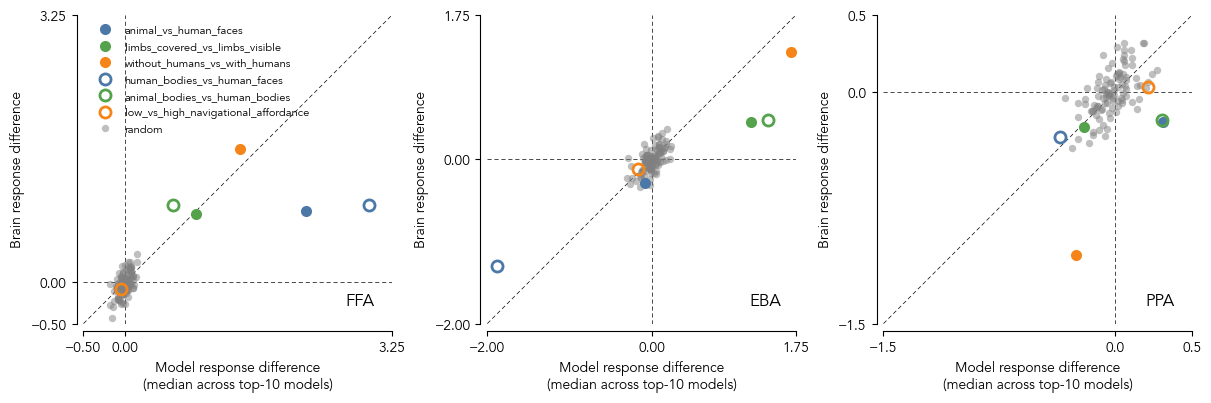

In [46]:
savefig = True
hide_y_info = False # Hide y-axis label and tick labels
figname = 'figS15_deltas_random_subsets.pdf'

category_colors = {
    'faces': '#4C78A8', # '#f09678',
    'scenes': '#F58518', # '#a6d2e5',
    'bodies': '#54A24B', # '#a7d6a1',
}
markersize = 8
comparison_marker_info = {
    'animal_vs_human_faces': {
        'markercolor': category_colors['faces'],
        'ec': 'none', 'mew': 0, 'marker': 'o',
        'alpha': 1, 'markersize': markersize, 'zorder': 10
    },
    'human_bodies_vs_human_faces': {
        'markercolor': 'none',
        'ec': category_colors['faces'], 'mew': 2, 'marker': 'o',
        'alpha': 1, 'markersize': markersize, 'zorder': 10
    },
    'limbs_covered_vs_limbs_visible': {
        'markercolor': category_colors['bodies'],
        'ec': 'none', 'mew': 0, 'marker': 'o',
        'alpha': 1, 'markersize': markersize, 'zorder': 10
    },
    'animal_bodies_vs_human_bodies': {
        'markercolor': 'none',
        'ec': category_colors['bodies'], 'mew': 2, 'marker': 'o',
        'alpha': 1, 'markersize': markersize, 'zorder': 10
    },
    'without_humans_vs_with_humans': {
        'markercolor': category_colors['scenes'],
        'ec': 'none', 'mew': 0, 'marker': 'o',
        'alpha': 1, 'markersize': markersize, 'zorder': 10
    },
    'low_vs_high_navigational_affordance': {
        'markercolor': 'none',
        'ec': category_colors['scenes'], 'mew': 2, 'marker': 'o',
        'alpha': 1, 'markersize': markersize, 'zorder': 10
    },
    'random': {
        'markercolor': 'gray',
        'ec': 'none', 'mew': 0, 'marker': 'o',
        'alpha': 0.5, 'markersize': markersize/1.5, 'zorder': 5
    },
}

# Processing FFA...
# Minimum and maximum mean delta across subjects and models for FFA: -0.42688684128571425, 2.9752473714285714


# Processing EBA...
# Minimum and maximum mean delta across subjects and models for EBA: -1.8798262614285715, 1.691197050714286


# Processing PPA...
# Minimum and maximum mean delta across subjects and models for PPA: -1.05605245, 0.3201884743857143

fig, axes = plt.subplots(1, len(frois), figsize=(4*len(frois), 5), constrained_layout=True)
plot_limits_dict = { # Keep it the same for plot 0 and 1 to allow slope interpretation,
    # For ylims, add a 1% offset to min to give some space below the lowest point, and set the max to accommodate the highest point across both plots
    'lim': {
        'FFA': [-0.5, 3.25],
        'EBA': [-2, 1.75],
        'PPA': [-1.5, 0.5], 
    }, # all min y-lims have a 0.05 offset to give some space below the lowest point, and all max y-lims are set to accommodate the highest point across both plots
    'ticks': {'FFA': np.array([-0.5, 0, 3.25]),'EBA': np.array([-2, 0, 1.75]),'PPA': np.array([-1.5, 0, 0.5])},
}

for froi_idx, froi in enumerate(frois):
    print(f'Processing {froi}...')
    ax_current = axes[froi_idx]
    ax_current.set_aspect('equal', adjustable='box') # Set aspect ratio to 1:1 to make the slope visually interpretable
    froi_deltas_df = all_bags_deltas_df[all_bags_deltas_df['froi'] == froi]
    # Figure out plot limits across all models and subjects for this froi to set the same limits for the successful, extra, and random bags plots to allow visual slope comparison
    print(f'Minimum and maximum mean delta across subjects and models for {froi}: {froi_deltas_df[["subjects_delta_mean", "models_delta_mean"]].min().min()}, {froi_deltas_df[["subjects_delta_mean", "models_delta_mean"]].max().max()}')
    for row_idx, row in froi_deltas_df.iterrows():
        hypothesis_label = row['hypothesis']
        comparison_label = row['comparison']
        comparison_label_str = None
        if comparison_label.startswith('bag1_vs_bag2'):
            if comparison_label == 'bag1_vs_bag2_idx=0':
                comparison_label_str = 'random'
        else:
            comparison_label_str = comparison_label
        if comparison_label_str is None:
            marker_kwargs = comparison_marker_info['random']
        else:
            marker_kwargs = comparison_marker_info[comparison_label_str]
        ax_current.plot(
            row['models_delta_mean'], row['subjects_delta_mean'], linestyle='None',
            marker=marker_kwargs['marker'], color=marker_kwargs['markercolor'], alpha=marker_kwargs['alpha'],
            markersize=marker_kwargs['markersize'],
            mec=marker_kwargs['ec'], mew=marker_kwargs['mew'],
            label=comparison_label_str,
            zorder=marker_kwargs['zorder']
        )
    # Plot x=0, y=0, and y=x lines to help visually compare the slopes across the successful, extra, and random bags
    ax_current.axhline(
            y=0, color='k', alpha=1, linewidth=0.5, zorder=-10,
            linestyle=(0, (6, 4))  # (offset, (dash_length, gap_length))
        )
    ax_current.axvline(
            x=0, color='k', alpha=1, linewidth=0.5, zorder=-10,
            linestyle=(0, (6, 4))  # (offset, (dash_length, gap_length))
        )
    ax_current.plot(
            plot_limits_dict['lim'][froi], plot_limits_dict['lim'][froi], color='k', alpha=1, linewidth=0.5, zorder=-10,
            linestyle=(0, (6, 4))  # (offset, (dash_length, gap_length))
        )
    ax_current.set_xlabel('Model response difference\n(median across top-10 models)')
    if hide_y_info:
        ax_current.set_yticklabels([])
        ax_current.set_ylabel('')
    else:
        ax_current.set_ylabel('Brain response difference')
    # ax_current.set_title(f'{froi} - Subject vs. Model Deltas')
    if froi_idx == 0: # Only add legend to the first plot to avoid redundancy, since the same color scheme is used across all plots
        ax_current.legend(frameon=False, loc='upper left', fontsize=8)
    ax_current.text(0.85, 0.1, froi, transform=ax_current.transAxes, fontsize=12, verticalalignment='top')
    ax_current.set_ylim(plot_limits_dict['lim'][froi])
    ax_current.set_yticks(plot_limits_dict['ticks'][froi])
    ax_current.set_xticks(plot_limits_dict['ticks'][froi])
    ax_current.spines['top'].set_visible(False)
    ax_current.spines['right'].set_visible(False)
    ax_current.spines['bottom'].set_position(('outward', 5))
    ax_current.spines['bottom'].set_bounds((np.min(plot_limits_dict['ticks'][froi]), np.max(plot_limits_dict['ticks'][froi])))
    ax_current.spines['left'].set_position(('outward', 5))
    ax_current.spines['left'].set_bounds((np.min(plot_limits_dict['ticks'][froi]), np.max(plot_limits_dict['ticks'][froi])))
    ax_current.set_xlim(plot_limits_dict['lim'][froi])
    print('\n')

# plt.tight_layout()
if savefig:
    plt.savefig(f'{plot_dir}/{figname}', dpi=300, transparent=True) # , bbox_inches='tight'
plt.show()
print('\n\n')

# Legacy

## Main figure: Fig 6

### Bags

In [ ]:
# Old

bags_old = {
    1: { # ~5000?
        'faces': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    1136, 1346, 2125, 7627, 8743, 12013, 12258, 14631, 15835, 16649,
                    18170, 19301, 19471, 21193, 21375
                ],
            },
            'bag2': {
                'label': 'Animal Faces',
                'nsdids': [
                    1162, 1487, 2429, 2795, 3532, 4221, 4719, 5156, 6137, 6315,
                    8213, 8486, 8489, 8757, 8858, 10319, 11431, 12460, 15180,
                    15555, 17505, 18569, 19079, 21064, 21723, 23796, 25131
                ],
            }
        },
        'human_faces_bodies': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    1136, 1346, 2125, 7627, 8743, 12013, 12258, 14631, 15835, 16649,
                    18170, 19301, 19471, 21193, 21375
                ],
            },
            'bag2': {
                'label': 'Human Bodies',
                'nsdids': [
                    1512, 3644, 6653, 6452, 8503, 10831, 9774, 11936, 11668, 12225, 12469,
                    18011, 15718, 16846, 14841, 16678, 14738, 23613, 22133, 20263, 27144,
                    20545, 23538, 22828, 28138, 20541, 28690, 31280, 36557, 33495, 37128, 
                    43345, 41563, 40001, 37621, 51914, 52447, 48202, 47272, 51008,
                    49530, 57460, 59576, 65647, 71502
                ],
            }
        },
        'animal_faces_bodies': {
            'bag1': {
                'label': 'Animal Faces',
                'nsdids': [
                    1162, 1487, 2429, 2795, 3532, 4221, 4719, 5156, 6137, 6315,
                    8213, 8486, 8489, 8757, 8858, 10319, 11431, 12460, 15180,
                    15555, 17505, 18569, 19079, 21064, 21723, 23796, 25131
                ],
            },
            'bag2': {
                'label': 'Animal Bodies',
                'nsdids': [
                    103, 104, 15240, 15536, 19736, 11611, 6793, 21755, 4685, 1378,
                    13106, 11949, 9452, 14883, 20034, 13377, 20049, 5683, 12490, 6022, 25368,
                    13299, 6555, 12010, 31106, 46990, 43162, 31415, 34318, 52060, 34030,
                    50981, 42749, 49170, 35049, 47918, 37954, 57114, 72710,
                    65005, 54552, 63396, 53402, 67649, 68896
                ],
            }
        },
        'human_faces_animal_bodies': {
            'bag2': {
                'label': 'Human Faces',
                'nsdids': [
                    1136, 1346, 2125, 7627, 8743, 12013, 12258, 14631, 15835, 16649,
                    18170, 19301, 19471, 21193, 21375
                ],
            },
            'bag1': {
                'label': 'Animal Bodies',
                'nsdids': [
                    103, 104, 15240, 15536, 19736, 11611, 6793, 21755, 4685, 1378,
                    13106, 11949, 9452, 14883, 20034, 13377, 20049, 5683, 12490, 6022, 25368,
                    13299, 6555, 12010, 31106, 46990, 43162, 31415, 34318, 52060, 34030,
                    50981, 42749, 49170, 35049, 47918, 37954, 57114, 72710,
                    65005, 54552, 63396, 53402, 67649, 68896
                ],
            }
        },
        'bodies': {
            'bag1': {
                'label': 'Human Bodies',
                'nsdids': [
                    1512, 3644, 6653, 6452, 8503, 10831, 9774, 11936, 11668, 12225, 12469,
                    18011, 15718, 16846, 14841, 16678, 14738, 23613, 22133, 20263, 27144,
                    20545, 23538, 22828, 28138, 20541, 28690, 31280, 36557, 33495, 37128, 
                    43345, 41563, 40001, 37621, 51914, 52447, 48202, 47272, 51008,
                    49530, 57460, 59576, 65647, 71502
                ],
            },
            'bag2': {
                'label': 'Animal Bodies',
                'nsdids': [
                    103, 104, 15240, 15536, 19736, 11611, 6793, 21755, 4685, 1378,
                    13106, 11949, 9452, 14883, 20034, 13377, 20049, 5683, 12490, 6022, 25368,
                    13299, 6555, 12010, 31106, 46990, 43162, 31415, 34318, 52060, 34030,
                    50981, 42749, 49170, 35049, 47918, 37954, 57114, 72710,
                    65005, 54552, 63396, 53402, 67649, 68896
                ],
            }
        },
        'scenes_liminal': {
            'bag1': {
                'label': 'Liminal Scenes',
                'nsdids': [
                    222, 3016, 3803, 5237, 7354, 7355, 7360, 8910,
                    10227, 10929, 11376, 11618, 18312, 19592,
                    20171, 21069, 21394, 22531, 23018
                ],
            },
            'bag2': {
                'label': 'Typical Scenes',
                'nsdids': [
                    1309, 452, 513, 1510, 2655, 13439, 13632, 20243, 20308, 20397, 20493
                ],
            }
        },
        'scenes_perspective': {
            'bag1': {
                'label': 'Vanishing Point',
                'nsdids': [
                    222, 3016, 3803, 5237, 7354, 7355, 7360, 8910,
                    10227, 10929, 11376, 11618, 18312, 19592,
                    20171, 21069, 21394, 22531, 23018
                ],
            },
            'bag2': {
                'label': 'No Vanishing Point',
                'nsdids': [
                    1309, 452, 513, 1510, 2655, 13439, 13632, 20243, 20308, 20397, 20493
                ],
            }
        }
    },
    2: { # # ~6800
        'faces': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    # 836, 1209, 7642, 7681, 16991, 18030, 18958, 21222, 21580, 22557, 28555,
                    # 28569, 28934, 28837, 30503, 30934, 32235, 32439, 33666, 34158, 34772,
                    # 36255, 44755, 45183, 45927, 48741, 50662, 51666, 56027
                    836, 1209, 7642, 7681, 16991, 18030, 21222, 22557, # 18958 21580
                    28934, 28837, 30934, 32235, 32439, 33666, 34158, # 28555, 28569, 30503
                    34772, 45183, 45927, 56027, # 36255 44755 48741, 50662, 51666
                    56373, 60189, 62821, 65027, 66244, 
                    71320, 68181, 66244, 65027, 62821, 60189, 56373
                ],
            },
            'bag2': {
                'label': 'Animal Faces',
                'nsdids': [
                    5, 333, 430, 743, 2473, 2943, 3928, 4155, 4741, 5005, 5082, 6837, 8749, # 890
                    9417, 9429, 10376, 10963, 12343, 13469, 13867, 14798, 15663, 16602, 16504, 
                    17312, 18455, 22161, 22481, 23007
                ],
            }
        },
        'human_faces_bodies': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    836, 1209, 7642, 7681, 16991, 18030, 18958, 21222, 21580, 22557, 28555,
                    28569, 28934, 28837, 30503, 30934, 32235, 32439, 33666, 34158, 34772,
                    36255, 44755, 45183, 45927, 48741, 50662, 51666, 56027
                ],
            },
            'bag2': {
                'label': 'Human Bodies',
                'nsdids': [
                    437, 1716, 2379, 3337, 4958, 7756, 9871, 9686, 10161, 13337, 14080, 14522,
                    15057, 15563, 16028, 16493, 17447, 18520, 20083, 20974, 22259, 24310, 26031,
                    26050, 26860, 27682, 27824, 30316, 30577, 33486
                ],
            }
        },
        'animal_faces_bodies': {
            'bag1': {
                'label': 'Animal Faces',
                'nsdids': [
                    5, 333, 430, 743, 2473, 2943, 3928, 4155, 4741, 5005, 5082, 6837, 8749, # 890
                    9417, 9429, 10376, 10963, 12343, 13469, 13867, 14798, 15663, 16602, 16504, 
                    17312, 18455, 22161, 22481, 23007
                ],
            },
            'bag2': {
                'label': 'Animal Bodies',
                'nsdids': [
                    44, 1163, 2665, 3684, 9363, 13578, 17070, 17146, 23628, 25482, 26640, 27637,
                    28387, 29961, 31413, 32166, 32837, 33769, 35316, 35352, 35641, 38705, 40208,
                    40908, 42107, 42622, 43957, 44326, 44595, 47713
                ],
            }
        },
        'human_faces_animal_bodies': {
            'bag2': { # ~8500
                'label': 'Human Faces',
                'nsdids': [
                    836, 1209, 7642, 7681, 16991, 18030, 21222, 22557, # 18958 21580
                    28934, 28837, 30934, 32235, 32439, 33666, 34158, # 28555, 28569, 30503
                    34772, 45183, 45927, 56027, # 36255 44755 48741, 50662, 51666
                    56373, 60189, 62821, 65027, 66244, 
                    71320, 68181, 66244, 65027, 62821, 60189, 56373 
                ], 
            },
            'bag1': {
                'label': 'Animal Bodies',
                'nsdids': [
                    44, 1163, 2665, 3684, 9363, 13578, 17070, 17146, 23628, 25482, 26640, 27637,
                    28387, 29961, 31413, 32166, 32837, 33769, 35316, 35352, 35641, 38705, 40208,
                    40908, 42107, 42622, 43957, 44326, 44595, 47713
                ],
            }
        },
        'bodies': {
            'bag1': {
                'label': 'Human Bodies',
                'nsdids': [
                    437, 1716, 2379, 3337, 4958, 7756, 9871, 9686, 10161, 13337, 14080, 14522,
                    15057, 15563, 16028, 16493, 17447, 18520, 20083, 20974, 22259, 24310, 26031,
                    26050, 26860, 27682, 27824, 30316, 30577, 33486
                ],
            },
            'bag2': {
                'label': 'Animal Bodies',
                'nsdids': [
                    44, 1163, 2665, 3684, 9363, 13578, 17070, 17146, 23628, 25482, 26640, 27637,
                    28387, 29961, 31413, 32166, 32837, 33769, 35316, 35352, 35641, 38705, 40208,
                    40908, 42107, 42622, 43957, 44326, 44595, 47713
                ],
            }
        },
        'scenes_liminal': {
            'bag1': {
                'label': 'Liminal Scenes',
                'nsdids': [
                    150, 328, 1317, 4050, 4414, 5716, 10676, 12988, 14486, 14717, 15478,
                    16906, 17187, 17277, 17328, 18701, 18815, 21472, 22663, 24589, 24661, 26049,
                    28124, 29193, 31024, 31227, 31658, 32393, 32495, 34930, 35055, 35570,
                    37251, 37293, 38179, 39214, 39431, 40442, 41713, 41772, 2480, 3099,
                ],
            },
            'bag2': {
                'label': 'Typical Scenes',
                'nsdids': [
                    645, 1085, 1219, 1518, 1777, 1908, 3683, 4237,
                    4534, 5221, 5387, 6492, 7012, 11163, 11828, 13050, 13162, 13810, 14435, 15994,
                    17282, 17803, 19084, 21991, 23503, 25888, 31486, 32927, 36245, 36678, 37975,
                    39799, 39881, 42526, 43576, 44489, 44488, 45032, # 5637
                ],
            }
        },
        'scenes_perspective': {
            'bag1': {
                'label': 'Vanishing Point',
                'nsdids': [
                    150, 328, 1317, 4050, 4414, 5716, 10676, 12988, 14486, 14717,
                    15478, 16906, 17187, 17277, 17328, 18701, 24589, 24661, 26049, 28124, # 18815, 21472, 22663,
                    29193, 31658, 32393, 32495, 35055, 35570, 37251, # 31024, 31227, 34930
                    37293, 38179, 39214, 41713, 41772 #  39431, 40442, 2480, 3099,
                ],
            },
            'bag2': {
                'label': 'No Vanishing Point',
                'nsdids': [
                    1085, 1219, 1908, 5221, # 645 1518, 1777 3683, 4237, 4534
                    5387, 7012, 11163, 11828, 13162, 13810, 15994, # 13050 14435 6492
                    17282, 17803, 19084, 21991, 31486, 32927,  # 23503, 25888 36245, 36678,
                    37975, 39799, 42526, 43576, 44489, 44488, 45032, # 5637 # 39881
                ],
            }
        }
    },
    3: { # ~5000
        'faces': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    # 129, 287, 7807, 8272, 8811, 9023, 11291, 11912, 13494, 14153, 14189, 16329,
                    # 18279, 19893, 21525, 25264, 28820, 32055, 33274, 33480, 4633, 41421,
                    # 41765, 42609, 45625, 46581, 8004
                    129, 287, 7807, 8272, 11912, 13494, 14153, # 8811, 9023, 11291
                    14189, 16329, 18279, 19893, 21525, 25264, 33274, 33480, # 32055 28820 4633
                    41421, 41765, 42609, # 45625, # 46581, # , 8004 # 
                    69127, 67185, 66970, 66476, # 64692, 
                    72186, 69810, 64696, 63139, 62880
                ],
            },
            'bag2': {
                'label': 'Animal Faces',
                'nsdids': [
                    109, 625, 1879, 3947, 4932, 6794, 7197, 7340, 7463, 7542, 7823, 9221, 9938,
                    11810, 12230, 12758, 16719, 18889, 21717, 23513, 27334, 28482, 29701, 32719,
                    37762, 43980
                ],
            }
        },
        'human_faces_bodies': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    129, 287, 7807, 8272, 8811, 9023, 11291, 11912, 13494, 14153, 14189, 16329,
                    18279, 19893, 21525, 25264, 28820, 32055, 33274, 33480, 4633, 41421,
                    41765, 42609, 45625, 46581, 8004
                ],
            },
            'bag2': {
                'label': 'Human Bodies',
                'nsdids': [
                    1045, 1397, 2262, 3568, 5864, 6650, 7338, 10644, 13690, 13794, 13804,
                    16357, 17793, 21374, 22770, 25027, 25911, 32797, 32964, 34159,
                    39313, 41204, 56009, 47058
                ],
            }
        },
        'animal_faces_bodies': {
            'bag1': {
                'label': 'Animal Faces',
                'nsdids': [
                    109, 625, 1879, 3947, 4932, 6794, 7197, 7340, 7463, 7542, 7823, 9221, 9938,
                    11810, 12230, 12758, 16719, 18889, 21717, 23513, 27334, 28482, 29701, 32719,
                    37762, 43980
                ],
            },
            'bag2': {
                'label': 'Animal Bodies',
                'nsdids': [
                    590, 705, 1847, 2043, 2230, 3101, 3218, 5662, 6931, 7702, 8060, 8099, 10439,
                    11138, 11152, 11284, 11401, 11739, 12124, 15305, 17931, 19948, 20000,
                    21837, 25688
                ],
            }
        },
        'human_faces_animal_bodies': {
            'bag2': {
                'label': 'Human Faces',
                'nsdids': [
                    # 129, 287, 7807, 8272, 8811, 9023, 11291, 11912, 13494, 14153, 14189, 16329,
                    # 18279, 19893, 21525, 25264, 28820, 32055, 33274, 33480, 4633, 41421,
                    # 41765, 42609, 45625, 46581, 8004
                    129, 287, 7807, 8272, 11912, 13494, 14153, # 8811, 9023, 11291
                    14189, 16329, 18279, 19893, 21525, 25264, 33274, 33480, # 32055 28820 4633
                    41421, 41765, 42609, # 45625, # 46581, # , 8004 # 
                    69127, 67185, 66970, 66476, # 64692, 
                    72186, 69810, 64696, 63139, 62880
                ],
            },
            'bag1': {
                'label': 'Animal Bodies',
                'nsdids': [
                    590, 705, 1847, 2043, 2230, 3101, 3218, 5662, 6931, 7702, 8060, 8099, 10439,
                    11138, 11152, 11284, 11401, 11739, 12124, 15305, 17931, 19948, 20000,
                    21837, 25688
                ],
            }
        },
        'bodies': {
            'bag1': {
                'label': 'Human Bodies',
                'nsdids': [
                    1045, 1397, 2262, 3568, 5864, 6650, 7338, 10644, 13690, 13794, 13804,
                    16357, 17793, 21374, 22770, 25027, 25911, 32797, 32964, 34159,
                    39313, 41204, 56009, 47058
                ],
            },
            'bag2': {
                'label': 'Animal Bodies',
                'nsdids': [
                    590, 705, 1847, 2043, 2230, 3101, 3218, 5662, 6931, 7702, 8060, 8099, 10439,
                    11138, 11152, 11284, 11401, 11739, 12124, 15305, 17931, 19948, 20000,
                    21837, 25688
                ],
            }
        },
        'scenes_liminal': {
            'bag1': {
                'label': 'Liminal Scenes',
                'nsdids': [
                    11, 406, 515, 1179, 1255, 2133, 2496, 2463, 2937, 3091,
                    3396, 3758, 5014, 7632, 8294, 8904, 8911, 8989, 9852, 10236,
                    11346, 12054, 12583, 12978, 13642, 15569, 19269, 20624, 22882
                ],
            },
            'bag2': {
                'label': 'Typical Scenes',
                'nsdids': [
                    1239, 1280, 2274, 2727, 3661, 4462, 7258, 8051, 8403, 9119, 11195, 12018,
                    12649, 14272, 14816, 17467, 17615, 18643, 20412,
                    22529, 29006, 27851, 31898, 31957, 32006, 32250, 32853, 32902, 33839, 34515
                ],
            }
        },
        'scenes_perspective': {
            'bag1': {
                'label': 'Vanishing Point',
                'nsdids': [
                    11, 515, 1179, 1255, 2133, 2496, 2463, 3091, # 406 2937
                    3396, 3758, 5014, 7632, 8904, 8911, 9852, # 8294 8989 10236
                    11346, 12583, 12978, 13642, 15569, 22882, # 12054 20624
                    64770, 63494, 62839, 54782, 54516, 47062
                ],
            },
            'bag2': {
                'label': 'No Vanishing Point',
                'nsdids': [ # 19269
                    1280, 2274, 2727, 3661, 4462, 7258, 8051, 8403, 9119, # 1239
                    11195, 12018, 12649, 14272, 14816, 17467, 17615, 18643, 20412, 22529,
                    27851, 31957, 32006, 32250, 32902, 34515 # 29006 31898 32853 33839
                ],
            }
        }
    },
    4: { # ~7800
        'faces': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    # 9167, 9222, 9491, 9536, 9693, 9915, 11185, 13213, 14181, 16931, 16947, 19407, 
                    # 20618, 21813, 23991, 24855, 25537, 26083, 26724, 27562, 28539, 28584, 28808,
                    # 30383, 30384, 31575, 32993, 33010, 33211, 33617, 35242, 35516, 35913, 37382, 
                    # 38610, 38914, 39605, 40411, 42009, 42972, 43439, 48671, 52258, 58238, 
                    9222, 9491, 9536, 9693, 9915, 11185, 13213, 14181, 16931, # 9167
                    16947, 19407, 21813, 23991, 24855, 25537, 26724, 27562, # 20618 26083
                    28584, 28808, 30383, 30384, 31575, 33211, 33617, # 28539 32993, 33010, 
                    35242, 35516, 37382, 38914, 40411, 42009, 42972, # 35913,  38610 39605
                    43439, 48671, 52258, 58238, # 
                ],
            },
            'bag2': {
                'label': 'Animal Faces',
                'nsdids': [
                    1091, 1322, 2427, 5755, 7404, 9724, 10874, 15239, 16687, 16989, 19921, 20267,
                    20895, 21467, 22539, 25524, 27495, 27727, 29016, 33375, 33857, 34008, 34980, 
                    35884, 37661, 38183, 38412, 38926, 42363, 44618, 45953, 47342, 47397, 48275, 
                    48452, 58469, 
                ],
            }
        },
        'human_faces_bodies': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    9167, 9222, 9491, 9536, 9693, 9915, 11185, 13213, 14181, 16931, 16947, 19407, 
                    20618, 21813, 23991, 24855, 25537, 26083, 26724, 27562, 28539, 28584, 28808,
                    30383, 30384, 31575, 32993, 33010, 33211, 33617, 35242, 35516, 35913, 37382, 
                    38610, 38914, 39605, 40411, 42009, 42972, 43439, 48671, 52258, 58238, 
                ],
            },
            'bag2': {
                'label': 'Human Bodies',
                'nsdids': [
                    17, 4598, 6409, 6628, 8810, 12511, 12985, 14579, 14678, 16902, 17882, 18217, 
                    18628, 19100, 19205, 19625, 20360, 20399, 20821, 22308, 22681, 25571, 26563,
                    28966, 30379, 30749, 33122, 33329, 33477, 34482, 39638, 41000, 42905, 45061, 
                    46327, 47383, 50935
                ],
            }
        },
        'animal_faces_bodies': {
            'bag1': {
                'label': 'Animal Faces',
                'nsdids': [
                    1091, 1322, 2427, 5755, 7404, 9724, 10874, 15239, 16687, 16989, 19921, 20267,
                    20895, 21467, 22539, 25524, 27495, 27727, 29016, 33375, 33857, 34008, 34980, 
                    35884, 37661, 38183, 38412, 38926, 42363, 44618, 45953, 47342, 47397, 48275, 
                    48452, 58469, 
                ],
            },
            'bag2': {
                'label': 'Animal Bodies',
                'nsdids': [
                    3690, 6114, 9470, 9906, 11567, 14359, 17153, 17472, 19272, 19960, 20245, 20721,
                    21931, 22420, 24930, 30469, 31033, 31230, 34988, 34755, 35620, 35900, 36011, 
                    37165, 37804, 37980, 38083, 40989, 41644, 41728, 43041, 43262, 43460, 43831, 
                    45744, 46297, 
                ],
            }
        },
        'human_faces_animal_bodies': {
            'bag2': {
                'label': 'Human Faces',
                'nsdids': [
                    9222, 9491, 9536, 9693, 9915, 11185, 13213, 14181, 16931, # 9167
                    16947, 19407, 21813, 23991, 24855, 25537, 26724, 27562, # 20618 26083
                    28584, 28808, 30383, 30384, 31575, 33211, 33617, # 28539 32993, 33010, 
                    35242, 35516, 37382, 38914, 40411, 42009, 42972, # 35913,  38610 39605
                    43439, 48671, 52258, 58238, # 
                ],
            },
            'bag1': {
                'label': 'Animal Bodies',
                'nsdids': [
                    3690, 6114, 9470, 9906, 11567, 14359, 17153, 17472, 19272, 19960, 20245, 20721,
                    21931, 22420, 24930, 30469, 31033, 31230, 34988, 34755, 35620, 35900, 36011, 
                    37165, 37804, 37980, 38083, 40989, 41644, 41728, 43041, 43262, 43460, 43831, 
                    45744, 46297, 
                ],
            }
        },
        'bodies': {
            'bag1': {
                'label': 'Human Bodies',
                'nsdids': [
                    17, 4598, 6409, 6628, 8810, 12511, 12985, 14579, 14678, 16902, 17882, 18217, 
                    18628, 19100, 19205, 19625, 20360, 20399, 20821, 22308, 22681, 25571, 26563,
                    28966, 30379, 30749, 33122, 33329, 33477, 34482, 39638, 41000, 42905, 45061, 
                    46327, 47383, 50935
                ],
            },
            'bag2': {
                'label': 'Animal Bodies',
                'nsdids': [
                    3690, 6114, 9470, 9906, 11567, 14359, 17153, 17472, 19272, 19960, 20245, 20721,
                    21931, 22420, 24930, 30469, 31033, 31230, 34988, 34755, 35620, 35900, 36011, 
                    37165, 37804, 37980, 38083, 40989, 41644, 41728, 43041, 43262, 43460, 43831, 
                    45744, 46297, 
                ],
            }
        },
        'scenes_liminal': {
            'bag1': {
                'label': 'Liminal Scenes',
                'nsdids': [
                    496, 648, 1451, 5824, 6204, 7327, 12416, 13193, 17023, 20544, 21074, 21753, 
                    22071, 23747, 24853, 25932, 26792, 29147, 33771, 34465, 34639, 35828, 36751, 
                    41941, 44509, 47841, 48570, 50173, 50251, 50333, 51133, 52416, 52487, 53174, 
                    53600, 53642, 54875, 56260, 56704, 62583, 63531, 65991, 66086, 68223, 69065, 
                ],
            },
            'bag2': {
                'label': 'Typical Scenes',
                'nsdids': [
                    77, 199, 6244, 6870, 6856, 7692, 8485, 8599, 9948, 11308, 11296, 13385, 14019,
                    15669, 17432, 20328, 22197, 24099, 24174, 25707, 26392, 27004, 27442, 29403,
                    29463, 29898, 30975, 34710, 35341, 35416, 36442, 36445, 38503, 38530, 38822,
                    39121, 39205, 39851, 42031, 42535, 43390, 44513, 45354, 46780, 47811, 48479,
                ],
            }
        },
        'scenes_perspective': {
            'bag1': {
                'label': 'Vanishing Point',
                'nsdids': [
                    496, 648, 1451, 5824, 6204, 7327, 12416, 13193, 17023, 20544, #
                    21753, 22071, 23747, 24853,  29147, 33771, 34465, # 21074 25932, 26792,
                    34639, 41941, 48570, 50251, 50333, # 35828 36751 47841 50173
                    52416, 53600, 56260, 62583, # 52487, 53174, 53642 56704
                    65991, 66086, 68223, 69065 # 63531
                ],
            },
            'bag2': {
                'label': 'No Vanishing Point',
                'nsdids': [ # 44509 51133 54875
                    44509, 51133, 54875, 8599, 9948, 11308, # 77, 199, 6244, 6870, 6856, 7692, 8485,
                    14019, 15669, 17432, 22197, 24174, # 11296 20328 24099 25707 13385
                    26392, 27004, 30975, 34710, 35341, # 27442, 29403, 29463, 29898, 35416
                    38822, 39121, 39205, 42031, # 36442, 36445, 38503, 38530,  39851
                    42535, 43390, 44513, 46780, 47811, 48479, # 45354
                    71292, 69123, 68736, 65846
                ],
            }
        }
    },
    5: { # ?
        'faces': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    # 6904, 8173, 6448, 11729, # 4028, 4829, 8512, 21297 9684, 9231, 
                    # 13637, 19527, 18751, 20254, 21507, 24104, 25468, # 11685, 12659, 27109
                    6904, 8173, 6448, 11729, # 4028, 4829, 8512, 21297, 9684, 9231, 
                    13637, 19527, 18751, 20254, 21507, 24104, 25468, # 11685, 12659, 27109
                    1856, 7431, 8027, 11729, 15586, 17250, 34529, 35821, 
                    46134, 46535, 46672, 50057, 52408, 57482, 61579, 62878, 68979, 
                    69647, 72197, # 14421
                ],
            },
            'bag2': {
                'label': 'Animal Faces',
                'nsdids': [
                    2180, 2192, 4047, 6779, 8162, 19799, 2945, 2894, 3906, 10137, 10002, 8799,
                    12036, 14592, 16190, 18624, 19238, 19799, 23346, 21993, 21489, 21563, 24423,
                    25326, 28175, 28447, 28728, 1742, 2945
                ],
            }
        },
        'human_faces_bodies': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [],
            },
            'bag2': {
                'label': 'Human Bodies',
                'nsdids': [],
            }
        },
        'animal_faces_bodies': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [],
            },
            'bag2': {
                'label': 'Human Bodies',
                'nsdids': [],
            }
        },
        'human_faces_animal_bodies': {
            'bag2': {
                'label': 'Human Faces',
                'nsdids': [
                    6904, 8173, 6448, 11729, # 4028, 4829, 8512, 21297, 9684, 9231, 
                    13637, 19527, 18751, 20254, 21507, 24104, 25468, # 11685, 12659, 27109
                    1856, 7431, 8027, 11729, 15586, 17250, 34529, 35821, 
                    46134, 46535, 46672, 50057, 52408, 57482, 61579, 62878, 68979, 
                    69647, 72197,  # 14421
                ],
            },
            'bag1': { # ~5300
                'label': 'Animal Bodies',
                'nsdids': [
                    2412, 3043, 4252, 4745, 5317, 6979, 7609, 7615, 8381, 9242, 10570, 
                    12616, 15192, 16956, 21711, 22904, 23805, 25872, 26160, 28931, 32391, 
                    34763, 36348, 38090, 43142, 
                    69215, 59912, 56702, 52404, 50370, 49319, 
                ],
            }
        },
        'bodies': {
            'bag1': {
                'label': 'Human Bodies',
                'nsdids': [],
            },
            'bag2': {
                'label': 'Animal Bodies',
                'nsdids': [],
            }
        },
        'scenes_liminal': {
            'bag1': {
                'label': 'Liminal Scenes',
                'nsdids': [
                    7895, 457, 1434, 2276, 3737, 3456, 4573, 6254, 7895, 6397, 5546, 10124,
                    9873, 11701, 11225, 10826, 11692, 12698, 13159, 13695, 13441, 12437, 14750,
                    16988, 16514, 19081, 19638, 19819, 21302, 23199, 23136, 25291,
                    23432, 23911, 23430, 26046, 26071, 27123, 28499, 28261, 29575, 
                    30717, 29875
                ],
            },
            'bag2': {
                'label': 'Typical Scenes',
                'nsdids': [
                    2820, 5115, 4464, 7545, 5298, 5396, 5002, 1021, 7982, 11667, 10996,
                    14339, 14948, 14201, 15360, 18044, 22647, 23322, 24059, 27361,
                    26436, 25752, 26356, 28784, 6993, 19739
                ],
            }
        },
        'scenes_perspective': {
            'bag1': {
                'label': 'Vanishing Point',
                'nsdids': [
                    7895, 457, 1434, 3737, 3456, 7895, 6397, # 2276 4573, 6254,
                    10124, 9873, 11701, 10826, 13159, 13695,  # 5546 11225 11692, 12698,
                    13441, 14750, 16988, 19081, 19819, 21302,  # 12437 16514 19638 23199
                    23911, 23430, 26046, 26071, 27123, 28499, 28261,  # 23136, 25291, 23432, 
                    29875  # 29575, 30717, 
                ],
            },
            'bag2': {
                'label': 'No Vanishing Point',
                'nsdids': [
                    2820, 5115, 4464, 7545, 5298, 5396, 5002, 7982, 11667, # 1021
                    10996, 14339, 14948, 14201, 15360, 18044, 22647, 24059, 27361, # 23322
                    26436, 25752, 26356, 28784, 6993, 19739, 69530 #
                ],
            }
        }
    },
    6: { # ~6770
        'faces': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    # 136, 368, 914, 3302, 4355, 4616, 5078, 5175, 6888, 7076, 57105, 
                    # 7897, 8329, 8706, 11439, 14186, 15987, 17311, 17364, 17852, 52915, 
                    # 18147, 19223, 19538, 24997, 25845, 26213, 26420, 30570, 37714, 42368, 44375,
                    # 29020, 32322,
                    136, 368, 914, 3302, 4355, 4616, 5078, 6888, # 5175, 7076
                    57105, 8329, 8706, 11439, 17311, 17364, # 7897, 14186, 15987, 17852
                    52915, 18147, 19223, 19538, 24997, 25845, 26213, 26420, 30570, 37714, #
                    42368, 44375, 29020, 32322, # 
                ],
            },
            'bag2': {
                'label': 'Animal Faces',
                'nsdids': [
                    217, 1613, 3167, 3126, 3827, 4435, 5621, 5688, 6312, 6410, 
                    9157, 9185, 10528, 10778, 10830, 11145, 11556, 12526, 13034,
                    13763, 14814, 17711, 17900, 19160, 23180, 25579, 26868, 27450, 
                    34111, 38000, 
                ],
            }
        },
        'human_faces_bodies': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    136, 368, 914, 3302, 4355, 4616, 5078, 5175, 6888, 7076, 57105, 
                    7897, 8329, 8706, 11439, 14186, 15987, 17311, 17364, 17852, 52915, 
                    18147, 19223, 19538, 24997, 25845, 26213, 26420, 30570, 37714, 42368, 44375,
                    29020, 32322,
                ],
            },
            'bag2': {
                'label': 'Human Bodies',
                'nsdids': [
                    106, 1303, 4547, 4676, 7841, 8588, 8830, 9295, 9442, 9475, 57999,
                    9676, 12326, 12904, 13979, 17687, 17817, 24280, 25419, 27289, 57915,
                    38680, 40104, 41422, 41930, 50862, 53385, 53428, 54805, 55168, 56232, 57797
                ],
            }
        },
        'animal_faces_bodies': {
            'bag1': {
                'label': 'Animal Faces',
                'nsdids': [
                    217, 1613, 3167, 3126, 3827, 4435, 5621, 5688, 6312, 6410, 
                    9157, 9185, 10528, 10778, 10830, 11145, 11556, 12526, 13034,
                    13763, 14814, 17711, 17900, 19160, 23180, 25579, 26868, 27450, 
                    34111, 38000, 
                ],
            },
            'bag2': {
                'label': 'Animal Bodies',
                'nsdids': [
                    245, 1617, 1941, 1953, 2923, 4296, 4983, 5151, 5410, 6453,
                    6907, 8770, 9619, 10787, 11740, 12896, 15855, 16241, 16878, 16890, 
                    16971, 19434, 24102, 24667, 26426, 26429, 33557, 37434, 37767, 38216, 39257
                ],
            },
        },
        'human_faces_animal_bodies': {
            'bag2': {
                'label': 'Human Faces',
                'nsdids': [
                    136, 368, 914, 3302, 4355, 4616, 5078, 6888, # 5175, 7076
                    57105, 8329, 8706, 11439, 17311, 17364, # 7897, 14186, 15987, 17852
                    52915, 18147, 19223, 19538, 24997, 25845, 26213, 26420, 30570, 37714, #
                    42368, 44375, 29020, 32322, # 
                ],
            },
            'bag1': {
                'label': 'Animal Bodies',
                'nsdids': [
                    245, 1617, 1941, 2923, 4296, 4983, 5151, 5410, 6453,
                    6907, 8770, 9619, 10787, 11740, 12896, 15855, 16241, 16878, 16890, 
                    16971, 19434, 24102, 24667, 26426, 26429, 33557, 37434, 37767, 38216, 39257
                ],
            }
        },
        'bodies': {
            'bag1': {
                'label': 'Human Bodies',
                'nsdids': [
                    106, 1303, 4547, 4676, 7841, 8588, 8830, 9295, 9442, 9475, 57999,
                    9676, 12326, 12904, 13979, 17687, 17817, 24280, 25419, 27289, 57915,
                    38680, 40104, 41422, 41930, 50862, 53385, 53428, 54805, 55168, 56232, 57797
                ],
            },
            'bag2': {
                'label': 'Animal Bodies',
                'nsdids': [
                    245, 1617, 1941, 1953, 2923, 4296, 4983, 5151, 5410, 6453,
                    6907, 8770, 9619, 10787, 11740, 12896, 15855, 16241, 16878, 16890, 
                    16971, 19434, 24102, 24667, 26426, 26429, 33557, 37434, 37767, 38216, 39257
                ],
            },
        },
        'scenes_liminal': {
            'bag1': {
                'label': 'Liminal Scenes',
                'nsdids': [
                    122, 834, 1017, 1151, 1688, 2167, 2380, 2798, 3065, 3447,
                    3538, 4178, 4733, 4780, 5541, 5570, 6154, 6556, 7794, 8322,
                    8376, 8943, 9784, 12199, 13350, 14341, 17126, 17723, 18788, 
                    19156, 19616, 19666, 20129, 21804, 22436, 22814, 26024, 26671,
                    27213, 30586, 32312, 32318, 37415, 39580, 40071, 43962, 48780, 50196
                ],
            },
            'bag2': {
                'label': 'Typical Scenes',
                'nsdids': [
                    18, 744, 1417, 3366, 5294, 6294, 8049, 8726, 8817, 9190,
                    9719, 11366, 13730, 15322, 16108, 17229, 17594, 17880, 17964,
                    18038, 19299, 22407, 22626, 23298, 23817, 25222, 25265, 27779, 28649,
                    28822, 30071, 34666, 35219, 37663, 39035, 40192, 40319, 41024, 41349
                ],
            }
        },
        'scenes_perspective': {
            'bag1': {
                'label': 'Vanishing Point',
                'nsdids': [
                    122, 834, 1017, 1688, 2167, 2380, 3065, 3447, #  1151 2798
                    4733, 4780, 5570, 6556, 7794, # 3538, 4178,   5541 6154 8322
                    8376, 8943, 9784, 13350, 14341, 17723, 18788, # 12199 17126 19156
                    19616, 21804, 22436, 22814, 27213, #  19666, 20129,  26024, 26671, 
                    30586, 32312, 32318, 37415, 39580, 40071, 43962, 48780, 50196 # 
                ],
            },
            'bag2': {
                'label': 'No Vanishing Point',
                'nsdids': [
                    18, 744, 1417, 3366, 5294, 6294, 8726, 9190, #  8049, 8817
                    9719, 11366, 13730, 15322, 16108, 17880, 17964, 18038, #  17229, 17594, 
                    19299, 22626, 23298, 25222, 25265, 28649, 28822, # 22407 23817 27779
                    30071, 34666, 35219, 37663, 39035, 40192, 40319, 41024, 41349 # 
                ],
            }
        }
    },
    7: { # ~6050
        'faces': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    # 491, 2612, 4146, 4264, 7810, 8405, 9833, 11115, 11621, 14017, 15514, 16276, 
                    # 19601, 19851, 20047, 20867, 23488, 24567, 25599, 27345, 27332, 28130, 28402, 
                    # 28947, 29539, 32811, 32864, 33142, 33182, 33853, 33668, 37066, 38075, 40106, 
                    # 40461, 40589, 
                    2612, 4146, 4264, 7810, 8405, 11115, 11621, 14017, # 491 9833
                    16276, 20047, 23488, 24567, 25599, 27345, # 15514, 19601, 19851, 20867
                    28402, 28947, 29539, # 32811, 32864, 33142, 33182, 33853, 27332, 28130, 
                    38075, 40106, 40461, #, 40589, #  33668, 37066, 
                    72166, 72027, 71748, 70931, 70008, 68200, 65560, 61445, 57768, 
                    57121, 54318, 54106, 52037,  # 54740 57210
                ],
            },
            'bag2': {
                'label': 'Animal Faces',
                'nsdids': [
                    240, 962, 1020, 2439, 2643, 3236, 4288, 4641, 5593, 6498, 9099, 9769, 10982, 
                    12637, 12740, 12927, 14283, 18126, 18137, 18231, 18922, 19310, 21774, 22623, 
                    22908, 24450, 24725, 29411, 29782, 30593, 31035, 31092, 31133, 31600, 33331, 
                    # 33401, 33770, 35713, 40492, 
                ],
            }
        },
        'human_faces_bodies': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    491, 2612, 4146, 4264, 7810, 8405, 9833, 11115, 11621, 14017, 15514, 16276, 
                    19601, 19851, 20047, 20867, 23488, 24567, 25599, 27345, 27332, 28130, 28402, 
                    28947, 29539, 32811, 32864, 33142, 33182, 33853, 33668, 37066, 38075, 40106, 
                    40461, 40589, 
                ],
            },
            'bag2': {
                'label': 'Human Bodies',
                'nsdids': [
                    1222, 1292, 2913, 3450, 5512, 14054, 14073, 14322, 14546, 16064, 16695, 18093, 
                    18196, 19512, 20785, 22694, 25383, 25621, 28236, 30227, 31194, 32037, 32586, 
                    32925, 33216, 33356, 33383, 33959, 34216, 34375, 34636, 34694, 35990, 36642, 
                    36657, 38014, 38348, 39015, 39607, 
                ],
            }
        },
        'animal_faces_bodies': {
            'bag1': {
                'label': 'Animal Faces',
                'nsdids': [
                    240, 962, 1020, 2439, 2643, 3236, 4288, 4641, 5593, 6498, 9099, 9769, 10982, 
                    12637, 12740, 12927, 14283, 18126, 18137, 18231, 18922, 19310, 21774, 22623, 
                    22908, 24450, 24725, 29411, 29782, 30593, 31035, 31092, 31133, 31600, 33331, 
                    33401, 33770, 35713, 40492, 
                ],
            },
            'bag2': {
                'label': 'Animal Bodies',
                'nsdids': [
                    2461, 3071, 3279, 3473, 3497, 5573, 5894, 7165, 7386, 7474, 8508, 10081, 10944, 
                    11047, 12603, 14759, 15422, 15597, 16164, 16871, 16874, 16943, 19590, 20048, 
                    20891, 21028, 21213, 21207, 21402, 22399, 22582, 22641, 23268, 25240, 26781, 
                    28034, 28223, 28483, 29855, 29856, 31011, 34170, 44771, 
                ],
            }
        },
        'human_faces_animal_bodies': {
            'bag2': {
                'label': 'Human Faces',
                'nsdids': [
                    # 491, 2612, 4146, 4264, 7810, 8405, 9833, 11115, 11621, 14017, 15514, 16276, 
                    # 19601, 19851, 20047, 20867, 23488, 24567, 25599, 27345, 27332, 28130, 28402, 
                    # 28947, 29539, 32811, 32864, 33142, 33182, 33853, 33668, 37066, 38075, 40106, 
                    # 40461, 40589, 
                    2612, 4146, 4264, 7810, 8405, 11115, 11621, 14017, # 491 9833
                    16276, 20047, 23488, 24567, 25599, 27345, # 15514, 19601, 19851, 20867
                    28402, 28947, 29539, # 32811, 32864, 33142, 33182, 33853, 27332, 28130, 
                    38075, 40106, 40461, #, 40589, #  33668, 37066, 
                    72166, 72027, 71748, 70931, 70008, 68200, 65560, 61445, 57768, 
                    57121, 54318, 54106, 52037,  # 54740 57210  
                ],
            },
            'bag1': {
                'label': 'Animal Bodies',
                'nsdids': [
                    2461, 3071, 3279, 3473, 3497, 5573, 5894, 7165, 7386, 7474, 8508, 10081, 10944, 
                    11047, 12603, 14759, 15422, 15597, 16164, 16871, 16874, 16943, 19590, 20048, 
                    20891, 21028, 21213, 21207, 21402, 22399, 22582, 22641, 23268, 25240, 26781, 
                    28034, 28223,
                    # 28483, 29855, 29856, 31011, 34170, 44771, 
                ],
            }
        },
        'bodies': {
            'bag1': {
                'label': 'Human Bodies',
                'nsdids': [
                    1222, 1292, 2913, 3450, 5512, 14054, 14073, 14322, 14546, 16064, 16695, 18093, 
                    18196, 19512, 20785, 22694, 25383, 25621, 28236, 30227, 31194, 32037, 32586, 
                    32925, 33216, 33356, 33383, 33959, 34216, 34375, 34636, 34694, 35990, 36642, 
                    36657, 38014, 38348, 39015, 39607, 
                ],
            },
            'bag2': {
                'label': 'Animal Bodies',
                'nsdids': [
                    2461, 3071, 3279, 3473, 3497, 5573, 5894, 7165, 7386, 7474, 8508, 10081, 10944, 
                    11047, 12603, 14759, 15422, 15597, 16164, 16871, 16874, 16943, 19590, 20048, 
                    20891, 21028, 21213, 21207, 21402, 22399, 22582, 22641, 23268, 25240, 26781, 
                    28034, 28223, 28483, 29855, 29856, 31011, 34170, 44771, 
                ],
            }
        },
        'scenes_liminal': {
            'bag1': {
                'label': 'Liminal Scenes',
                'nsdids': [
                    461, 2629, 2931, 7124, 8686, 10362, 12427, 15183, 16982,  19644, 19881, 22977, 
                    26072, 26939, 27247, 28873, 30335, 30755, 32002, 32183,  32292, 33724, 35267, 
                    36060, 36494, 38654, 41161, 41500, 41659, 42666, 43609, 44205, 44306, 48431,
                    48673
                ],
            },
            'bag2': {
                'label': 'Typical Scenes',
                'nsdids': [
                    116, 449, 810, 1703, 2635, 3087, 4633, 4856, 5816, 7900, 9316, 10658, 11157, 
                    11814, 12021, 14330, 15020, 15147, 15511, 16641, 17160, 19019, 19861, 20526, 
                    21161, 21799, 26190, 33444, 33925, 36579, 36860, 39751, 40988, 41805, 41940,
                    42283, 42264, 
                ],
            }
        },
        'scenes_perspective': {
            'bag1': {
                'label': 'Vanishing Point',
                'nsdids': [
                    461, 2629, 7124, 8686, 10362, 12427, 15183, #  2931,  16982, 19644, 
                    19881, 22977, 26072, 27247, 28873, 30335, 30755, 32002, #  26939 32183
                    32292, 33724, 35267, 38654, 41500, #  36060, 36494, 41659, 42666,
                    43609, # 48431, 48673 # 
                    72949, 60287, 53162, 49803, 46956, 44771, 
                ],
            },
            'bag2': {
                'label': 'No Vanishing Point',
                'nsdids': [ # 41161 44205, 44306
                    449, 810, 1703, 3087, 4856, 5816, 7900, #  116,  2635, 4633
                    10658, 15020, 15147, 15511, 16641, # 9316 11157, 11814, 12021, 14330, 
                    17160, 19019, 19861, 20526, 21161, #  21799, 26190, 33444, 33925, 36579, # 
                    36860, 41940, 42283, 42264, # 39751, 40988, 41805, 
                    71947, 71794, 71755, 69927, 59262, 
                ],
            }
        }
    },
    8: { # ~6900
        'faces': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    # 220, 948, 2531, 2645, 2783, 3589, 5109, 5126, 5409, 7779, 9008, 9037, 9608, 
                    # 10198, 11534, 13093, 14048, 15650, 16642, 17018, 17068, 17243, 17534, 20876, 
                    # 21556, 22034, 24109, 25402, 27467, 59941, 
                    2783, 5109, 5126, #, 5409, 7779, # 220, 948, 2531, 2645, 3589
                    9037, 9608, 11534, 13093, 17018, # 9008, 10198 14048, 15650, 16642, 
                    17068, 17243, 17534, 25402, 59941, # 20876, 21556, 22034, 24109,  27467,
                    63975, 71984, 72059, 72458, # 72383
                    71005, 70246, 65214, 64168, 62862, 62255, # 58694, 68994 64083
                    54640, 50851
                ],
            },
            'bag2': {
                'label': 'Animal Faces',
                'nsdids': [
                    878, 1237, 1245, 1418, 3672, 5307, 6390, 8141, 8900, 9040, 10169, 10683, 11658, 
                    11716, 12855, 13429, 14975, 16546, 17194, 18265, 22833, 24625, 25438, 27762,
                    27867, 29905, 
                ],
            }
        },
        'human_faces_bodies': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    # 220, 948, 2531, 2645, 2783, 3589, 5109, 5126, 5409, 7779, 9008, 9037, 9608, 
                    # 10198, 11534, 13093, 14048, 15650, 16642, 17018, 17068, 17243, 17534, 20876, 
                    # 21556, 22034, 24109, 25402, 27467, 59941, 
                    2783, 5109, 5126, #, 5409, 7779, # 220, 948, 2531, 2645, 3589
                    9037, 9608, 11534, 13093, 17018, # 9008, 10198 14048, 15650, 16642, 
                    17068, 17243, 17534, 25402, 59941, # 20876, 21556, 22034, 24109,  27467,
                    63975, 71984, 72059, 72383, 72458,
                    71005, 70246, 65214, 64168, 64083, 62862, 62255, 58694, 68994
                ],
            },
            'bag2': {
                'label': 'Human Bodies',
                'nsdids': [
                    21, 463, 550, 937, 4151, 5531, 7579, 7677, 8270, 8841, 9635, 9776, 10367, 13490, 
                    16118, 17641, 17730, 18861, 19641, 20340, 20982, 21532, 21761, 22178, 25648,
                    25976, 44902, 
                ],
            }
        },
        'animal_faces_bodies': {
            'bag1': {
                'label': 'Animal Faces',
                'nsdids': [
                    878, 1237, 1245, 1418, 3672, 5307, 6390, 8141, 8900, 9040, 10169, 10683, 11658, 
                    11716, 12855, 13429, 14975, 16546, 17194, 18265, 22833, 24625, 25438, 27762,
                    27867, 29905, 
                ],
            },
            'bag2': {
                'label': 'Animal Bodies',
                'nsdids': [
                    76, 633, 768, 751, 1360, 1665, 1868, 2916, 3487, 4272, 4382, 5407, 7734, 
                    8446, 9308, 9501, 10720, 11979, 11995, 12400, 12369, 13436, 13473, 13797, 
                    14348, 14418, 16869, 17414, 
                ],
            }
        },
        'human_faces_animal_bodies': {
            'bag2': {
                'label': 'Human Faces',
                'nsdids': [
                    # 220, 948, 2531, 2645, 2783, 3589, 5109, 5126, 5409, 7779, 9008, 9037, 9608, 
                    # 10198, 11534, 13093, 14048, 15650, 16642, 17018, 17068, 17243, 17534, 20876, 
                    # 21556, 22034, 24109, 25402, 27467, 59941, 
                    2783, 5109, 5126, #, 5409, 7779, # 220, 948, 2531, 2645, 3589
                    9037, 9608, 11534, 13093, 17018, # 9008, 10198 14048, 15650, 16642, 
                    17068, 17243, 17534, 25402, 59941, # 20876, 21556, 22034, 24109,  27467,
                    63975, 71984, 72059, 72458, # 72383
                    71005, 70246, 65214, 64168, 62862, 62255, # 58694, 68994 64083
                    54640, 50851
                ],
            },
            'bag1': {
                'label': 'Animal Bodies',
                'nsdids': [
                    76, 633, 768, 751, 1360, 1665, 1868, 2916, 3487, 4272, 4382, 5407, 7734, 
                    8446, 9308, 9501, 10720, 11979, 11995, 12400, 12369, 13436, 13473, 13797, 
                    14348, 14418, 16869, 17414, 
                ],
            }
        },
        'bodies': {
            'bag1': {
                'label': 'Human Bodies',
                'nsdids': [
                    21, 463, 550, 937, 4151, 5531, 7579, 7677, 8270, 8841, 9635, 9776, 10367, 13490, 
                    16118, 17641, 17730, 18861, 19641, 20340, 20982, 21532, 21761, 22178, 25648,
                    25976, 44902, 
                ],
            },
            'bag2': {
                'label': 'Animal Bodies',
                'nsdids': [
                    76, 633, 768, 751, 1360, 1665, 1868, 2916, 3487, 4272, 4382, 5407, 7734, 
                    8446, 9308, 9501, 10720, 11979, 11995, 12400, 12369, 13436, 13473, 13797, 
                    14348, 14418, 16869, 17414, 
                ],
            }
        },
        'scenes_liminal': {
            'bag1': {
                'label': 'Liminal Scenes',
                'nsdids': [
                    1648, 2027, 5124, 6356, 9049, 13323, 21380, 23665, 26449, 27955, 29716, 29823,
                    30180, 30611, 33542, 37487, 37981, 43607, 44187, 45758, 49150, 50578, 55330, 
                    55934, 56320, 56467, 60213
                ],
            },
            'bag2': {
                'label': 'Typical Scenes',
                'nsdids': [
                    929, 3365, 4380, 4858, 6091, 6683, 7161, 9246, 10264, 11028, 14247, 14569, 
                    18651, 20509, 22378, 25734, 26992, 27998, 28526, 29143, 29222, 29483, 31793,
                    31891, 32165, 32297, 32256, 32828, 33490, 
                ],
            }
        },
        'scenes_perspective': {
            'bag1': {
                'label': 'Vanishing Point',
                'nsdids': [
                    1648, 2027, 6356, 9049, 13323, 21380, 23665, 26449, 27955, # 5124
                    29716, 29823, 30180, 43607, 44187, 45758, #   30611, 33542, 37487, 37981, 
                    49150, 50578, 55934, 56320, 56467, 60213, # 55330
                    72029, 70040, 69525, 67399, 66667, 
                ],
            },
            'bag2': {
                'label': 'No Vanishing Point',
                'nsdids': [
                    929, 3365, 4380, 4858, 6091, 6683, 7161, 11028, #  9246, 10264,
                    20509, 25734, 26992, 27998, #  14247, 14569, 18651, 22378 28526, 29143,
                    29483, 32165, 32297, 32256, 33490, # 29222 31793, 31891,  32828
                    71445, 71307, 70549, 70088, 69931, 69583, 68038, 67986, 67178, 65969
                ],
            }
        }
    },
}

# bag_nsamples_df = []

# comparisons_considered = ['faces', 'human_faces_animal_bodies', 'scenes_perspective']
# bags_considered = ['Human Faces', 'Animal Faces','Animal Bodies', 'Vanishing Point', 'No Vanishing Point']
# for subject in range(2, 9):
#     sbj_row = {'subject': subject}
#     sbj_bags = bags[subject]
#     for comparison_type in sbj_bags:
#         if comparison_type not in comparisons_considered:
#             continue
#         comparison = sbj_bags[comparison_type]
#         for bag_key in list(comparison.keys()):
#             bag = comparison[bag_key]
#             if bag['label'] in bags_considered:
#                 sbj_row[bag['label']] = len(bag['nsdids'])
#     bag_nsamples_df.append(sbj_row)
# bag_nsamples_df = pd.DataFrame(bag_nsamples_df)
# display(bag_nsamples_df)

### a, b, c

In [9]:
frois = ['FFA', 'PPA', 'EBA']
subject = 1
model_name = 'resnet50imagenet1kv2'

froi_515_df_dict = {}
for froi in frois:
    print(f"Loading data for {froi}...")
    froi_515_df_dict[froi], _, _, _, _ = get_data(
        subject, froi, subset=515, model_name=model_name
    )

Loading data for FFA...
loading annotations into memory...
Done (t=7.15s)
creating index...
index created!
loading annotations into memory...
Done (t=0.50s)
creating index...
index created!
loading annotations into memory...
Done (t=0.31s)
creating index...
index created!
loading annotations into memory...
Done (t=0.02s)
creating index...
index created!
Full subset, 
Mean Pearson r: 0.6459, RDMR: 0.3385
Loading data for PPA...
loading annotations into memory...
Done (t=7.17s)
creating index...
index created!
loading annotations into memory...
Done (t=0.49s)
creating index...
index created!
loading annotations into memory...
Done (t=0.30s)
creating index...
index created!
loading annotations into memory...
Done (t=0.02s)
creating index...
index created!
Full subset, 
Mean Pearson r: 0.6966, RDMR: 0.2800
Loading data for EBA...
loading annotations into memory...
Done (t=7.27s)
creating index...
index created!
loading annotations into memory...
Done (t=0.49s)
creating index...
index creat

FFA diffs min: 0.005176139064133167, max: 3.433906078338623
PPA diffs min: 0.001626485143788159, max: 1.967289686203003
EBA diffs min: 0.0002875679638236761, max: 2.0667526721954346


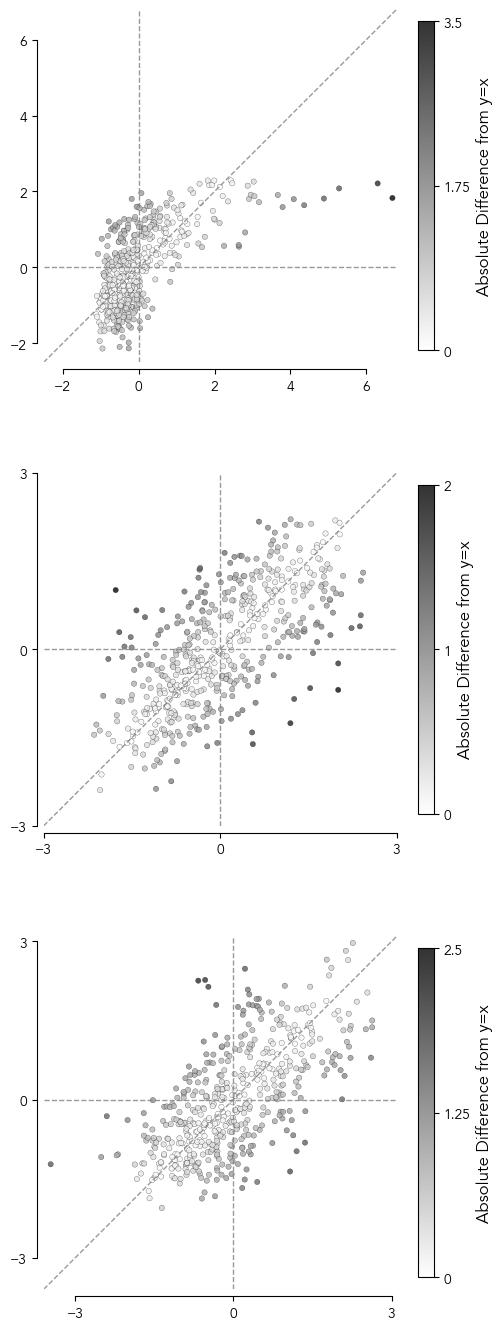

In [69]:
froi_lims = {
    'FFA': [-2.5, 6.8],
    'PPA': [-3, 3],
    'EBA': [-3.6, 3.1],
}
froi_ticks = {
    'FFA': np.array([-2, 0, 2, 4, 6]),
    'PPA': np.array([-3, 0, 3]),
    'EBA': np.array([-3, 0, 3]),
}

fig, ax = plt.subplots(3, 1, figsize=(5, 14), constrained_layout=False)
for i, froi in enumerate(frois):
    froi_515_df = froi_515_df_dict[froi]
    # y=x line
    lims = froi_lims[froi]
    ax[i].plot(lims, lims, '--', color='gray', linewidth=1, alpha = 0.8)
    # x=0 line
    ax[i].plot([0, 0], lims, '--', color='gray', linewidth=1, alpha = 0.8)
    # y=0 line
    ax[i].plot(lims, [0, 0], '--', color='gray', linewidth=1, alpha = 0.8)
    # Scatter plot
    diffs = froi_515_df['subject_response'] - froi_515_df['model_response']
    distances = np.abs(diffs)/np.sqrt(2) # Divide by sqrt(2) to get the distance to the y=x line
    print(f"{froi} diffs min: {distances.min()}, max: {distances.max()}")
    max_dist = distances.max()
    cbar_max = np.ceil(max_dist * 2) / 2  # Round up to the nearest 0.5
    scatter = ax[i].scatter(
        froi_515_df['model_response'],
        froi_515_df['subject_response'],
        s=15,                 # Marker size
        c=distances,          # Use distances for color mapping
        cmap='binary',        # Grayscale colormap (black for high values)
        alpha=0.8,            # Use a fixed alpha for all points for clarity
        edgecolors=(0, 0, 0, 0.2),   # Optional: add a faint edge
        linewidths=0.2,
        vmin=0,
        vmax=cbar_max
    )
    cbar = fig.colorbar(scatter, ax=ax[i], shrink=0.8, fraction=0.1, format='%g')
    # cbar_ticks = np.arange(0, cbar_max + 0.1, 0.5) # The +0.1 ensures the endpoint is included
    cbar.set_ticks([0, cbar_max / 2, cbar_max])
    cbar.set_label('Absolute Difference from y=x', fontsize=12, weight='bold')
    # Set limits and labels
    ax[i].set_xlim(lims)
    ax[i].set_ylim(lims)
    ax[i].set_aspect('equal', 'box')
    # ax[i].set_title(froi)
    ax[i].set_xticks(froi_ticks[froi])
    ax[i].set_yticks(froi_ticks[froi])
    # ax.set_ylabel(r'$\Delta$voxel/unit-averaged activation' + f'\n({bag1_info['label']} - {bag2_info['label']})')
    ax[i].spines['top'].set_visible(False)
    ax[i].spines['right'].set_visible(False)
    ax[i].spines['left'].set_position(('outward', 5))
    ax[i].spines['bottom'].set_position(('outward', 5))
    ax[i].spines['bottom'].set_bounds(froi_ticks[froi].min(), froi_ticks[froi].max())
    ax[i].spines['left'].set_bounds(froi_ticks[froi].min(), froi_ticks[froi].max())
# plt.suptitle(f'Subject {subject}, {model_name}')
plt.savefig(f'{PLOTS_DIR}/fig6_abc_scatter_{model_name}_subject{subject}.pdf', dpi=300, bbox_inches='tight')
plt.tight_layout()
plt.show()
plt.close()


#### Store 515 stimuli

In [82]:
all_stimuli, nsdids = nsd.get_subset_stimuli(NSD_DIR, 515)
stim515_dir = f'{PLOTS_DIR}/stimuli515'
os.makedirs(stim515_dir, exist_ok=True)
for idx, nsdid in enumerate(nsdids):
    stim = Image.fromarray(all_stimuli[idx])
    stim.save(f'{stim515_dir}/nsdid_{nsdid}_idx_{sidx:03d}_nsd515stim.png')

### d, e, f

#### Stimuli

In [12]:
all_stimuli, _ = nsd.get_subset_stimuli(NSD_DIR, None)

In [ ]:
# Loop over subjects 2-8, make a folder
# For Faces and scenes_perspective, loop over bags, make a folder for them
# Save the first 3 images from each bag
for subject in range(2, 9):
    subject_dir = f'{PLOTS_DIR}/stimuli/subject_{subject}'
    if not os.path.exists(subject_dir):
        os.makedirs(subject_dir, exist_ok=True)
    for category in ['faces', 'scenes_perspective', 'human_faces_animal_bodies']:
        category_dir = f'{subject_dir}/{category}'
        if not os.path.exists(category_dir):
            os.makedirs(category_dir, exist_ok=True)
        for bag in ['bag1', 'bag2']:
            bag_label = bags[subject][category][bag]['label']
            bag_nsdids = bags[subject][category][bag]['nsdids']
            bag_dir = f'{category_dir}/{bag_label}'
            if not os.path.exists(bag_dir):
                os.makedirs(bag_dir, exist_ok=True)
            # Save the first 3 images from this bag
            for imgidx in range(15):
                nsd_id = bag_nsdids[imgidx]
                img = all_stimuli[nsd_id]
                # Save the image as a jpg
                img = Image.fromarray(img)
                img.save(f'{bag_dir}/{nsd_id}.jpg')
                # print(f"Saved image {nsd_id} to {bag_dir}/{nsd_id}.jpg")

#### Boxplots

In [44]:
# STIMULI = nsd.get_stimuli_dataset(NSD_DIR, transform=None, subset=None).all_stimuli

frois = ['FFA', 'PPA', 'EBA']
subjects = [2, 3, 4, 5, 6, 7, 8]  # NSD subjects
mean_zscored_responses_df_path = f'results/exploration/explore_interpret/subject_specific_mean_zscored_responses.csv'
resp_df = pd.read_csv(mean_zscored_responses_df_path)

froi_bags = {
    'FFA': 'faces',
    'PPA': 'scenes_perspective',
    'EBA': 'human_faces_animal_bodies',
}
model_color = '#944e1f' # Brown
subject_color = '#fde0c5' # Light peach

#### Model-specific

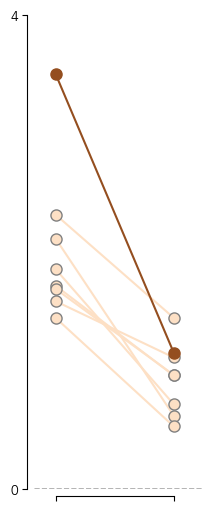

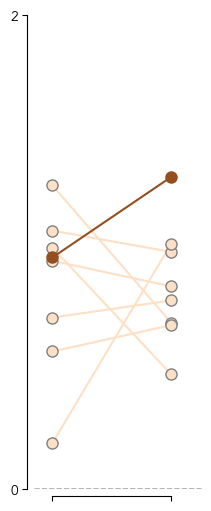

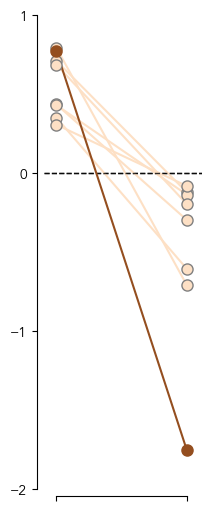

In [ ]:
savefig = False

froi_lims = {
    'FFA': [0, 4],
    'PPA': [0, 2],
    'EBA': [-2, 1],
}
froi_ticks = {
    'FFA': np.array([0, 4]),
    'PPA': np.array([0, 2]),
    'EBA': np.array([-2, -1, 0, 1]),
}

model_name = 'resnet50imagenet1kv2'
subset = None # 515 for shared, None for subject-specific set
# x_system_offset = 0.2
# x_category_offset = 0.0425
for froi in frois:
    # froi = 'FFA'
    bag_type = froi_bags[froi]
    fig, axes = plt.subplots(1, 1, figsize=(2, 5), constrained_layout=True)
    y_lims = froi_lims[froi]
    y_ticks = froi_ticks[froi]
    for sidx, system in enumerate(['subject', model_name]):
        ax = axes
        system_responses_bag1 = []
        system_responses_bag2 = []
        color = subject_color if system == 'subject' else model_color
        for subject in subjects:
            bag1_nsdids = bags[subject][bag_type]['bag1']['nsdids']
            bag2_nsdids = bags[subject][bag_type]['bag2']['nsdids']
            sbj_froi_mdl_subset_resp_df =resp_df[
                (resp_df['subject'] == subject) &
                (resp_df['froi'] == froi)
            ]
            system_responses_bag1_ = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_nsdids)
            ][f'{system}_response']
            system_responses_bag1.append(np.median(system_responses_bag1_))
            system_responses_bag2_ = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_nsdids)
            ][f'{system}_response']
            system_responses_bag2.append(np.median(system_responses_bag2_))
        # Add a vertical line at x=0
        ax.axhline(y=0, color='k', linestyle='--', linewidth=1, alpha=0.8)
        if system == 'subject':
            for sbjidx, subject in enumerate(subjects):
                ax.plot(
                    [0, 1],
                    [system_responses_bag1[sbjidx], system_responses_bag2[sbjidx]],
                    '-',
                    color=subject_color,
                    alpha=1
                )
                ax.errorbar(
                    [0, 1],
                    [
                        system_responses_bag1[sbjidx],
                        system_responses_bag2[sbjidx]
                    ],
                    # xerr=[
                    #     np.std(system_responses_bag1)/np.sqrt(len(system_responses_bag1)),
                    #     np.std(system_responses_bag2)/np.sqrt(len(system_responses_bag2))
                    # ],
                    fmt='o',
                    color=subject_color,
                    alpha=1,
                    markersize=8,
                    linewidth=0,
                    zorder=4,
                    capsize=0,
                    mec='gray'
                )
        else:
            ax.plot(
                [0, 1],
                [np.median(system_responses_bag1), np.median(system_responses_bag2)],
                '-',
                color=model_color,
                alpha=1
            )
            ax.errorbar(
                [0, 1],
                [
                    np.median(system_responses_bag1),
                    np.median(system_responses_bag2)
                ],
                xerr=[
                    np.std(system_responses_bag1)/np.sqrt(len(system_responses_bag1)),
                    np.std(system_responses_bag2)/np.sqrt(len(system_responses_bag2))
                ],
                fmt='o',
                color=model_color,
                alpha=1,
                markersize=8,
                linewidth=0,
                zorder=5,
                capsize=0,
            )
        # # Add individual points
        # for i, x in zip([1, 0], [system_responses_bag1, system_responses_bag2]):
        #     ax.scatter(x, [i]*len(x), s=15, alpha=0.8, color='gray', label=f'Bag {i+1}' if sidx == 0 else "", edgecolor=None, linewidth=0.2, zorder=2)
        ax.set_xticks([0, 1])
        ax.set_xticklabels([])
        ax.set_ylim(y_lims)
        ax.set_yticks(y_ticks)
        # ax.set_xlabel(system + ' Response (z-scored)')
        # ax.set_title('Model' if system == model_name else 'Subject')
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_position(('outward', 5))
        ax.spines['bottom'].set_position(('outward', 5))
        ax.spines['left'].set_bounds(y_ticks.min(), y_ticks.max())
        ax.spines['bottom'].set_bounds(0, 1)
        # if sidx == 1:
        #     ax.set_yticks([])  # Hide y-axis ticks for the second plot
        #     ax.set_yticklabels([])  # Hide y-axis labels for the second plot
        #     ax.spines['left'].set_visible(False)
    # plt.suptitle(f'Subject-Specific Stimuli Subset in {froi} (Model: {model_name})', y=1.02)
    # plt.tight_layout()
    if savefig:
        plt.savefig(f'{PLOTS_DIR}/fig6_lineplot_{froi}_{model_name}.pdf', dpi=300, bbox_inches='tight')
    else:
        plt.show()
    plt.close()

## Supplementary

In [8]:
# STIMULI = nsd.get_stimuli_dataset(NSD_DIR, transform=None, subset=None).all_stimuli

frois = ['FFA', 'PPA', 'EBA']
subjects = [2, 3, 4, 5, 6, 7, 8]  # NSD subjects
mean_zscored_responses_df_path = f'results/exploration/explore_interpret/subject_specific_mean_zscored_responses.csv'
resp_df = pd.read_csv(mean_zscored_responses_df_path)

froi_bags = {
    'FFA': 'faces',
    'PPA': 'scenes',
    'EBA': 'bodies',
}
model_color = '#944e1f' # Brown
subject_color = '#fde0c5' # Light peach

### Individual model deltas (+ve hypothesis)

### Stats: Linear Mixed Model

In [42]:
for model_name in TOP_MODEL_NAMES:
    print()
    print(f"Analyzing model: {model_name}")
    # model_name = 'resnet50imagenet1kv2'
    froi = 'PPA'
    bag_type = froi_bags[froi]
    bag1_label = '_'.join(bags[2][bag_type]['bag1']['label'].split())
    bag2_label = '_'.join(bags[2][bag_type]['bag2']['label'].split())

    data_df = []
    # Get a df with columns: nsd_id, subject, response, system (subject/model), category (bag1/bag2)
    for subject in subjects:
        bag1_nsdids = bags[subject][bag_type]['bag1']['nsdids']
        bag2_nsdids = bags[subject][bag_type]['bag2']['nsdids']
        sbj_froi_mdl_subset_resp_df =resp_df[
            (resp_df['subject'] == subject) &
            (resp_df['froi'] == froi)
        ]
        for nsd_id in bag1_nsdids:
            sbj_resp = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'] == nsd_id
            ]['subject_response'].values[0]
            mdl_resp = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'] == nsd_id
            ][f'{model_name}_response'].values[0]
            data_df.append({
                'nsd_id': nsd_id,
                'response': sbj_resp,
                'subject': subject,
                'system': 'subject',
                'category': bag1_label
            })
            data_df.append({
                'nsd_id': nsd_id,
                'response': mdl_resp,
                'subject': subject,
                'system': 'model',
                'category': bag1_label
            })
        for nsd_id in bag2_nsdids:
            sbj_resp = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'] == nsd_id
            ]['subject_response'].values[0]
            mdl_resp = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'] == nsd_id
            ][f'{model_name}_response'].values[0]
            data_df.append({
                'nsd_id': nsd_id,
                'response': sbj_resp,
                'subject': subject,
                'system': 'subject',
                'category': bag2_label
            })
            data_df.append({
                'nsd_id': nsd_id,
                'response': mdl_resp,
                'subject': subject,
                'system': 'model',
                'category': bag2_label
            })
    data_df = pd.DataFrame(data_df)
    data_df['system'] = pd.Categorical(data_df['system'], categories=['subject', 'model'], ordered=True)
    data_df['category'] = pd.Categorical(data_df['category'], categories=[bag1_label, bag2_label], ordered=True)
    data_df['subject'] = pd.Categorical(data_df['subject'], categories=subjects, ordered=True)
    # display(data_df)

    lmm_model = smf.mixedlm(
        "response ~ system * category + C(subject)", 
        data_df, 
        groups=data_df["subject"], 
        # re_formula="~category" # Random slopes for category within subjects
    )
    results = lmm_model.fit(method='lbfgs', reml=True, maxiter=2000, full_output=True)
    print(results.summary())

    # fe = smf.ols("response ~ system * category + C(subject)", data=data_df).fit()
    # print(fe.summary())


Analyzing model: resnet50imagenet1kv2
                            Mixed Linear Model Regression Results
Model:                          MixedLM             Dependent Variable:             response 
No. Observations:               784                 Method:                         REML     
No. Groups:                     7                   Scale:                          0.6440   
Min. group size:                104                 Log-Likelihood:                 -951.6824
Max. group size:                132                 Converged:                      Yes      
Mean group size:                112.0                                                        
---------------------------------------------------------------------------------------------
                                               Coef.    Std.Err.     z    P>|z| [0.025 0.975]
---------------------------------------------------------------------------------------------
Intercept                                       0

### Plot: Individual models

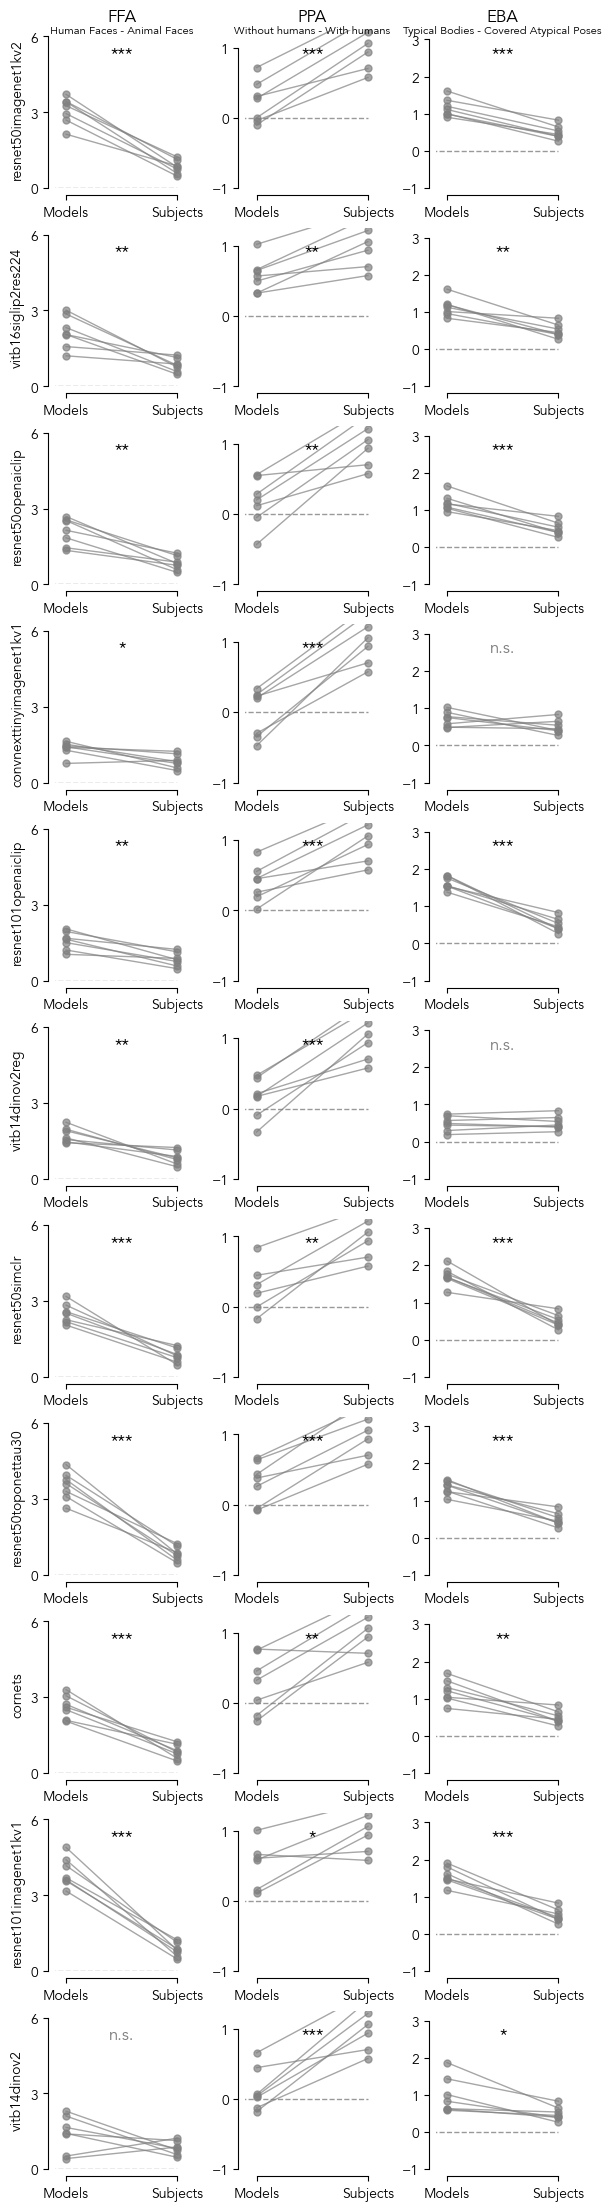

In [5]:
savefig = False

froi_lims = {
    'FFA': [0, 6.25],
    'PPA': [-1, 1.25],
    'EBA': [-1, 3.25],
}
froi_ticks = {
    'FFA': np.array([0, 3, 6]),
    'PPA': np.array([-1, 0, 1]),
    'EBA': np.array([-1, 0, 1, 2, 3]),
}

fig, axes = plt.subplots(len(TOP_MODEL_NAMES), len(frois), figsize=(2*len(frois), 2*len(TOP_MODEL_NAMES)), constrained_layout=True)
for midx, model_name in enumerate(TOP_MODEL_NAMES):
    subset = None # 515 for shared, None for subject-specific set
    # x_system_offset = 0.2
    # x_category_offset = 0.0425
    for fidx, froi in enumerate(frois):
        ax = axes[midx, fidx]
        bag_type = froi_bags[froi]
        y_lims = froi_lims[froi]
        y_ticks = froi_ticks[froi]
        data_points = []
        for subject in subjects:
            bag1_nsdids = bags[subject][bag_type]['bag1']['nsdids']
            bag2_nsdids = bags[subject][bag_type]['bag2']['nsdids']
            sbj_froi_mdl_subset_resp_df =resp_df[
                (resp_df['subject'] == subject) &
                (resp_df['froi'] == froi)
            ]
            subject_bag1_resp = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_nsdids)
            ]['subject_response']
            subject_bag2_resp = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_nsdids)
            ]['subject_response']
            model_bag1_resp = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_nsdids)
            ][f'{model_name}_response']
            model_bag2_resp = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_nsdids)
            ][f'{model_name}_response']
            subject_delta = np.median(subject_bag1_resp) - np.median(subject_bag2_resp)
            model_delta = np.median(model_bag1_resp) - np.median(model_bag2_resp)
            data_points.append((model_delta, subject_delta))
        data_points = np.array(data_points)
        subject_delta_normt, subject_delta_normp = shapiro(data_points[:, 1])
        model_delta_normt, model_delta_normp = shapiro(data_points[:, 0])
        if subject_delta_normp < 0.05:
            print(f"{froi}, {model_name} subjects delta not normal (Shapiro p={subject_delta_normp:.4f})")
        if model_delta_normp < 0.05:
            print(f"{froi}, {model_name} model delta not normal (Shapiro p={model_delta_normp:.4f})")
        # y=0 line
        ax.plot([-1, 1], [0, 0], '--', color='gray', linewidth=1, alpha = 0.8)
        # Paired line plot
        for didx, dpt in enumerate(data_points):
            ax.plot(
                [0, 1],
                [dpt[0], dpt[1]],
                '-o',
                markersize=5,
                linewidth=1,
                color='gray',
                alpha=0.7,
                zorder=2
            )
        # Do a paired t-test and report the p-value
        t_stat, p_val = ttest_rel(data_points[:, 0], data_points[:, 1])
        # print(f"{froi}, {model_name}: t={t_stat:.2f}, p={p_val:.4f}")
        # Add significance asterisks
        if p_val < 0.001:
            sig_label = '***'
        elif p_val < 0.01:
            sig_label = '**'
        elif p_val < 0.05:
            sig_label = '*'
        else:
            sig_label = 'n.s.'
        ax.text(0.5, y_lims[1] - 0.1*(y_lims[1]-y_lims[0]), sig_label, ha='center', va='top', fontsize=12, color='black' if sig_label != 'n.s.' else 'gray')
        # ax.plot(data_points, '-o', color='gray', alpha=0.7, markersize=5, linewidth=1, zorder=2)
        ax.set_xticks([0, 1])
        ax.set_xticklabels(['Models', 'Subjects'])
        ax.set_xlim([-0.1, 1.1])
        ax.set_ylim(y_lims)
        ax.set_yticks(y_ticks)
        # ax.set_xlabel(system + ' Response (z-scored)')
        # ax.set_title('Model' if system == model_name else 'Subject')
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_position(('outward', 5))
        ax.spines['bottom'].set_position(('outward', 5))
        ax.spines['left'].set_bounds(y_ticks.min(), y_ticks.max())
        ax.spines['bottom'].set_bounds(0, 1)
        ax.set_ylabel(model_name if fidx == 0 else "")
        type_label = f'{bags[2][froi_bags[froi]]["bag1"]["label"]} - {bags[2][froi_bags[froi]]["bag2"]["label"]}'
        # ax.set_title(f'{froi}\n' + fr'\small({type_label})' if midx == 0 else "")
        if midx == 0:
            # ax.set_title(f"{froi}\n{type_label}", fontsize=12)
            # then shrink only the second line
            ax.title.set_text(f"{froi}")
            ax.title.set_fontsize(12)  # main size
            # manually shrink the second line
            # ax.set_title(f"{type_label}", fontsize=12, loc="center")
            # ax.text(0.5, 1.02, froi, transform=ax.transAxes,
            #         ha='center', va='bottom', fontsize=12)
            ax.text(0.5, 0.96, type_label, transform=ax.transAxes,
                    ha='center', va='bottom', fontsize=8)
        else:
            ax.set_title("")
if savefig:
    plt.savefig(f'{PLOTS_DIR}/supfig_lineplot_allmodelsfrois.pdf', dpi=300, bbox_inches='tight')
else:
    plt.show()
plt.close()

#### EBA: Human faces vs. Animal faces

EBA, vitb16siglip2res224 model delta not normal (Shapiro p=0.0276)
PPA, resnet101openaiclip model delta not normal (Shapiro p=0.0426)
PPA, cornets model delta not normal (Shapiro p=0.0387)


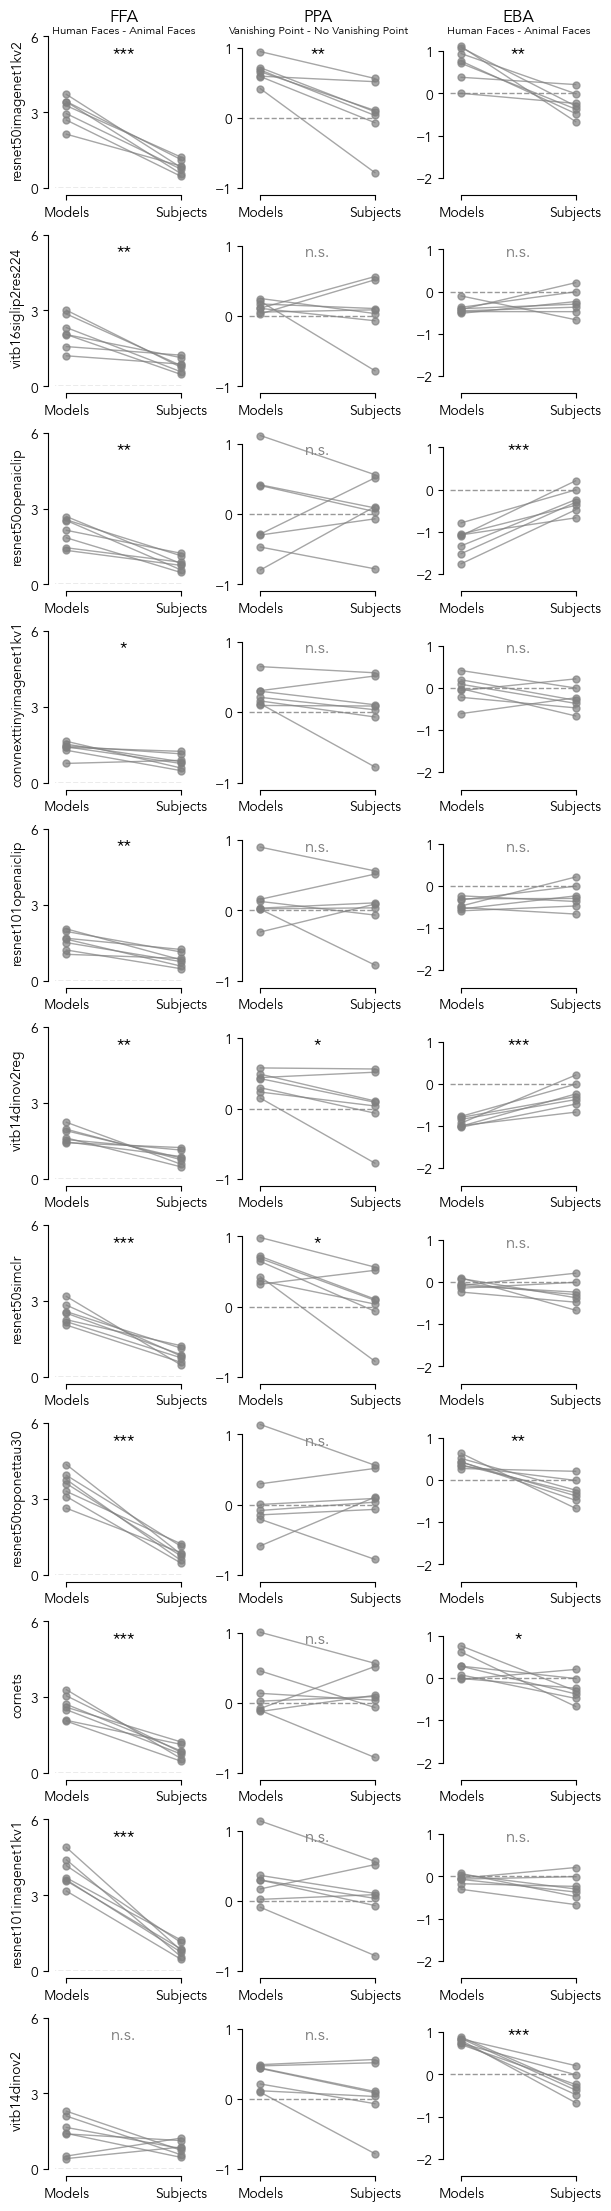

In [8]:
froi_bags = {
    'FFA': 'faces',
    'PPA': 'scenes_perspective',
    'EBA': 'faces',
}

savefig = False

froi_lims = {
    'FFA': [0, 6.25],
    'PPA': [-1, 1.25],
    'EBA': [-2.25, 1.5],
}
froi_ticks = {
    'FFA': np.array([0, 3, 6]),
    'PPA': np.array([-1, 0, 1]),
    'EBA': np.array([-2, -1, 0, 1]),
}

fig, axes = plt.subplots(len(TOP_MODEL_NAMES), len(frois), figsize=(2*len(frois), 2*len(TOP_MODEL_NAMES)), constrained_layout=True)
for midx, model_name in enumerate(TOP_MODEL_NAMES):
    subset = None # 515 for shared, None for subject-specific set
    # x_system_offset = 0.2
    # x_category_offset = 0.0425
    for fidx, froi in enumerate(frois):
        ax = axes[midx, fidx]
        bag_type = froi_bags[froi]
        y_lims = froi_lims[froi]
        y_ticks = froi_ticks[froi]
        data_points = []
        for subject in subjects:
            bag1_nsdids = bags[subject][bag_type]['bag1']['nsdids']
            bag2_nsdids = bags[subject][bag_type]['bag2']['nsdids']
            sbj_froi_mdl_subset_resp_df =resp_df[
                (resp_df['subject'] == subject) &
                (resp_df['froi'] == froi)
            ]
            subject_bag1_resp = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_nsdids)
            ]['subject_response']
            subject_bag2_resp = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_nsdids)
            ]['subject_response']
            model_bag1_resp = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_nsdids)
            ][f'{model_name}_response']
            model_bag2_resp = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_nsdids)
            ][f'{model_name}_response']
            subject_delta = np.median(subject_bag1_resp) - np.median(subject_bag2_resp)
            model_delta = np.median(model_bag1_resp) - np.median(model_bag2_resp)
            data_points.append((model_delta, subject_delta))
        data_points = np.array(data_points)
        subject_delta_normt, subject_delta_normp = shapiro(data_points[:, 1])
        model_delta_normt, model_delta_normp = shapiro(data_points[:, 0])
        if subject_delta_normp < 0.05:
            print(f"{froi}, {model_name} subjects delta not normal (Shapiro p={subject_delta_normp:.4f})")
        if model_delta_normp < 0.05:
            print(f"{froi}, {model_name} model delta not normal (Shapiro p={model_delta_normp:.4f})")
        # y=0 line
        ax.plot([-1, 1], [0, 0], '--', color='gray', linewidth=1, alpha = 0.8)
        # Paired line plot
        for didx, dpt in enumerate(data_points):
            ax.plot(
                [0, 1],
                [dpt[0], dpt[1]],
                '-o',
                markersize=5,
                linewidth=1,
                color='gray',
                alpha=0.7,
                zorder=2
            )
        # Do a paired t-test and report the p-value
        t_stat, p_val = ttest_rel(data_points[:, 0], data_points[:, 1])
        # print(f"{froi}, {model_name}: t={t_stat:.2f}, p={p_val:.4f}")
        # Add significance asterisks
        if p_val < 0.001:
            sig_label = '***'
        elif p_val < 0.01:
            sig_label = '**'
        elif p_val < 0.05:
            sig_label = '*'
        else:
            sig_label = 'n.s.'
        ax.text(0.5, y_lims[1] - 0.1*(y_lims[1]-y_lims[0]), sig_label, ha='center', va='top', fontsize=12, color='black' if sig_label != 'n.s.' else 'gray')
        # ax.plot(data_points, '-o', color='gray', alpha=0.7, markersize=5, linewidth=1, zorder=2)
        ax.set_xticks([0, 1])
        ax.set_xticklabels(['Models', 'Subjects'])
        ax.set_xlim([-0.1, 1.1])
        ax.set_ylim(y_lims)
        ax.set_yticks(y_ticks)
        # ax.set_xlabel(system + ' Response (z-scored)')
        # ax.set_title('Model' if system == model_name else 'Subject')
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_position(('outward', 5))
        ax.spines['bottom'].set_position(('outward', 5))
        ax.spines['left'].set_bounds(y_ticks.min(), y_ticks.max())
        ax.spines['bottom'].set_bounds(0, 1)
        ax.set_ylabel(model_name if fidx == 0 else "")
        type_label = f'{bags[2][froi_bags[froi]]["bag1"]["label"]} - {bags[2][froi_bags[froi]]["bag2"]["label"]}'
        # ax.set_title(f'{froi}\n' + fr'\small({type_label})' if midx == 0 else "")
        if midx == 0:
            # ax.set_title(f"{froi}\n{type_label}", fontsize=12)
            # then shrink only the second line
            ax.title.set_text(f"{froi}")
            ax.title.set_fontsize(12)  # main size
            # manually shrink the second line
            # ax.set_title(f"{type_label}", fontsize=12, loc="center")
            # ax.text(0.5, 1.02, froi, transform=ax.transAxes,
            #         ha='center', va='bottom', fontsize=12)
            ax.text(0.5, 0.96, type_label, transform=ax.transAxes,
                    ha='center', va='bottom', fontsize=8)
        else:
            ax.set_title("")
if savefig:
    raise NotImplementedError
    # plt.savefig(f'{PLOTS_DIR}/supfig_lineplot_allmodelsfrois.pdf', dpi=300, bbox_inches='tight')
else:
    plt.show()
plt.close()

### Plot: Across models

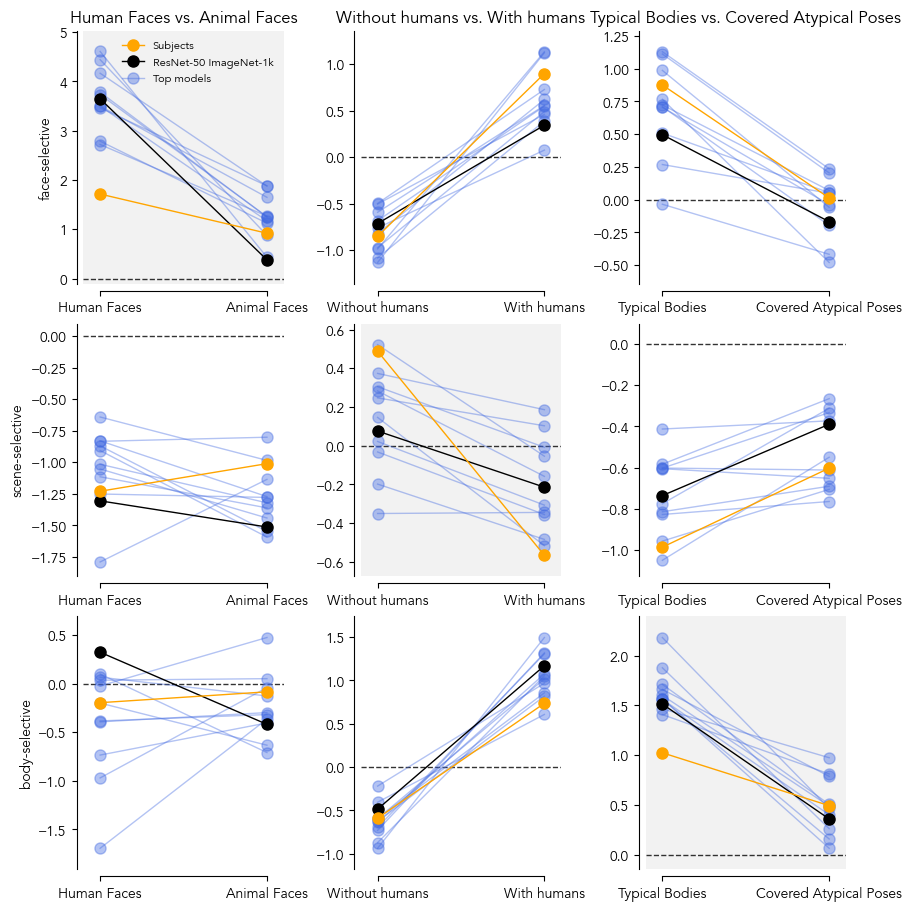

In [7]:
savefig = False

bag_types = ['faces', 'scenes', 'bodies']
frois = ['FFA', 'PPA', 'EBA']

froi_lims = {
    'FFA': [0, 6.25],
    'PPA': [-1, 1.25],
    'EBA': [-1, 3.25],
}
froi_ticks = {
    'FFA': np.array([0, 3, 6]),
    'PPA': np.array([-1, 0, 1]),
    'EBA': np.array([-1, 0, 1, 2, 3]),
}
froi_labels = {
    'FFA': 'face-selective',
    'PPA': 'scene-selective',
    'EBA': 'body-selective',
}
rn50imgnet_color = 'k' # Black
othermodels_color = "royalblue"
subjects_color = 'orange'

fig, axes = plt.subplots(len(frois), len(bag_types), figsize=(3*len(bag_types), 3*len(frois)), constrained_layout=True)
for bidx, bag_type in enumerate(bag_types):
    bag1_label = bags[2][bag_type]['bag1']['label']
    bag2_label = bags[2][bag_type]['bag2']['label']
    for fidx, froi in enumerate(frois):
        ax = axes[fidx, bidx]
        if fidx == bidx: # Highlight the diagonal
            ax.set_facecolor((0.5, 0.5, 0.5, 0.1))
        ax_pts = []
        y_lims = froi_lims[froi]
        y_ticks = froi_ticks[froi]
        # y=0 line
        ax.axhline(y=0, color='k', linestyle='--', linewidth=1, alpha=0.8)
        for model_name in reversed(TOP_MODEL_NAMES):
            model_pts = []
            for subject in range(2, 9):
                bag1_nsdids = bags[subject][bag_type]['bag1']['nsdids']
                bag2_nsdids = bags[subject][bag_type]['bag2']['nsdids']
                model_responses_bag1_median = np.median(resp_df[
                    (resp_df['subject'] == subject) &
                    (resp_df['froi'] == froi) &
                    (resp_df['nsd_id'].isin(bag1_nsdids))
                ][f'{model_name}_response'])
                model_responses_bag2_median = np.median(resp_df[
                    (resp_df['subject'] == subject) &
                    (resp_df['froi'] == froi) &
                    (resp_df['nsd_id'].isin(bag2_nsdids))
                ][f'{model_name}_response'])
                model_pts.append((model_responses_bag1_median, model_responses_bag2_median))
            model_pts = np.array(model_pts)
            model_pts_medians = np.median(model_pts, axis=0)
            ax_pts += model_pts_medians.tolist()
            ax.plot(
                [0, 1],
                [model_pts_medians[0], model_pts_medians[1]],
                '-o',
                color=rn50imgnet_color if model_name == 'resnet50imagenet1kv2' else othermodels_color,
                alpha=1 if model_name == 'resnet50imagenet1kv2' else 0.4,
                markersize=8,
                linewidth=1,
                # zorder=5,
                # label=model_name if model_name == 'resnet50imagenet1kv2' else ("other models" if bidx == 0 and fidx == 0 else ""),
            )
        # Add median across subjects
        subject_pts = []
        for subject in range(2, 9):
            bag1_nsdids = bags[subject][bag_type]['bag1']['nsdids']
            bag2_nsdids = bags[subject][bag_type]['bag2']['nsdids']
            subject_responses_bag1_median = np.median(resp_df[
                (resp_df['subject'] == subject) &
                (resp_df['froi'] == froi) &
                (resp_df['nsd_id'].isin(bag1_nsdids))
            ]['subject_response'])
            subject_responses_bag2_median = np.median(resp_df[
                (resp_df['subject'] == subject) &
                (resp_df['froi'] == froi) &
                (resp_df['nsd_id'].isin(bag2_nsdids))
            ]['subject_response'])
            subject_pts.append((subject_responses_bag1_median, subject_responses_bag2_median))
        subject_pts = np.array(subject_pts)
        subject_pts_medians = np.median(subject_pts, axis=0)
        ax_pts += subject_pts_medians.tolist()
        ax.plot(
            [0, 1],
            [subject_pts_medians[0], subject_pts_medians[1]],
            '-o',
            color=subjects_color,
            alpha=1,
            markersize=8,
            linewidth=1,
            # zorder=6,
            label='Subjects' if bidx == 0 and fidx == 0 else "",
        )
        # Plot properties
        ax_pts = np.array(ax_pts)
        ax_min = np.min([ax_pts.min() - 0.1*(ax_pts.max() - ax_pts.min()), -0.1])
        ax_max = np.max([ax_pts.max() + 0.1*(ax_pts.max() - ax_pts.min()), 0.1])
        # Set legend labels manually
        ax.plot([], [], '-o', color=rn50imgnet_color, alpha=1, markersize=8, linewidth=1, label='ResNet-50 ImageNet-1k')
        ax.plot([], [], '-o', color=othermodels_color, alpha=0.4, markersize=8, linewidth=1, label='Top models')
        ax.set_xticks([0, 1])
        ax.set_xticklabels([bag1_label, bag2_label])
        ax.set_xlim([-0.1, 1.1])
        ax.set_ylim(ax_min, ax_max)
        # ax.set_yticks(y_ticks)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_position(('outward', 5))
        ax.spines['bottom'].set_position(('outward', 5))
        # ax.spines['left'].set_bounds(y_ticks.min(), y_ticks.max())
        ax.spines['bottom'].set_bounds(0, 1)
        ax.set_ylabel(froi_labels[froi] if bidx == 0 else "")
        type_label = f'{bag1_label} vs. {bag2_label}'
        if fidx == 0:
            ax.set_title(f"{type_label}", fontsize=12)
        else:
            ax.set_title("")
        if bidx == 0 and fidx == 0:
            ax.legend(frameon=False, fontsize=8, loc='upper right')
if savefig:
    raise NotImplementedError
    # plt.savefig(f'{PLOTS_DIR}/supfig_lineplot_allmodelsfrois.pdf', dpi=300, bbox_inches='tight')
else:
    plt.show()
plt.close()

### Plot: Held-out models

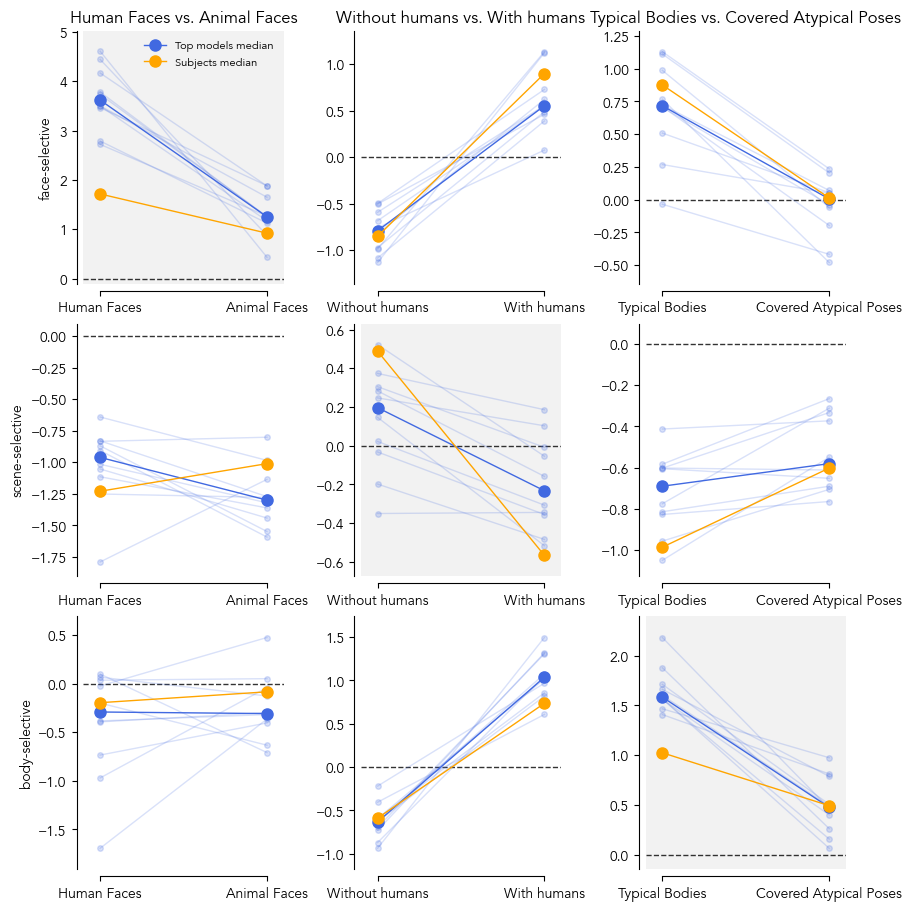

In [8]:
savefig = False

bag_types = ['faces', 'scenes', 'bodies']
frois = ['FFA', 'PPA', 'EBA']

froi_lims = {
    'FFA': [0, 6.25],
    'PPA': [-1, 1.25],
    'EBA': [-1, 3.25],
}
froi_ticks = {
    'FFA': np.array([0, 3, 6]),
    'PPA': np.array([-1, 0, 1]),
    'EBA': np.array([-1, 0, 1, 2, 3]),
}
froi_labels = {
    'FFA': 'face-selective',
    'PPA': 'scene-selective',
    'EBA': 'body-selective',
}
# rn50imgnet_color = 'k' # Black
othermodels_color = "royalblue"
subjects_color = 'orange'

fig, axes = plt.subplots(len(frois), len(bag_types), figsize=(3*len(bag_types), 3*len(frois)), constrained_layout=True)
for bidx, bag_type in enumerate(bag_types):
    bag1_label = bags[2][bag_type]['bag1']['label']
    bag2_label = bags[2][bag_type]['bag2']['label']
    for fidx, froi in enumerate(frois):
        ax = axes[fidx, bidx]
        if fidx == bidx: # Highlight the diagonal
            ax.set_facecolor((0.5, 0.5, 0.5, 0.1))
        ax_pts = []
        y_lims = froi_lims[froi]
        y_ticks = froi_ticks[froi]
        models_pts = []
        # y=0 line
        ax.axhline(y=0, color='k', linestyle='--', linewidth=1, alpha=0.8)
        for model_name in reversed(TOP_MODEL_NAMES):
            if model_name == 'resnet50imagenet1kv2':
                continue # Skip ResNet-50 ImageNet-1k
            model_pts = []
            for subject in range(2, 9):
                bag1_nsdids = bags[subject][bag_type]['bag1']['nsdids']
                bag2_nsdids = bags[subject][bag_type]['bag2']['nsdids']
                model_responses_bag1_median = np.median(resp_df[
                    (resp_df['subject'] == subject) &
                    (resp_df['froi'] == froi) &
                    (resp_df['nsd_id'].isin(bag1_nsdids))
                ][f'{model_name}_response'])
                model_responses_bag2_median = np.median(resp_df[
                    (resp_df['subject'] == subject) &
                    (resp_df['froi'] == froi) &
                    (resp_df['nsd_id'].isin(bag2_nsdids))
                ][f'{model_name}_response'])
                model_pts.append((model_responses_bag1_median, model_responses_bag2_median))
            model_pts = np.array(model_pts)
            model_pts_medians = np.median(model_pts, axis=0)
            ax_pts += model_pts_medians.tolist()
            models_pts.append(model_pts_medians)
            ax.plot(
                [0, 1],
                [model_pts_medians[0], model_pts_medians[1]],
                '-o',
                color=rn50imgnet_color if model_name == 'resnet50imagenet1kv2' else othermodels_color,
                alpha=1 if model_name == 'resnet50imagenet1kv2' else 0.2,
                markersize=4,
                linewidth=1,
                # zorder=5,
                # label=model_name if model_name == 'resnet50imagenet1kv2' else ("other models" if bidx == 0 and fidx == 0 else ""),
            )
        # Plot median across models
        models_pts = np.array(models_pts)
        models_pts_medians = np.median(models_pts, axis=0)
        ax_pts += models_pts_medians.tolist()
        ax.plot(
            [0, 1],
            [models_pts_medians[0], models_pts_medians[1]],
            '-o',
            color=othermodels_color,
            alpha=1,
            markersize=8,
            linewidth=1,
            # zorder=6,
            label='Top models median' if bidx == 0 and fidx == 0 else "",
        )
        # Add median across subjects
        subject_pts = []
        for subject in range(2, 9):
            bag1_nsdids = bags[subject][bag_type]['bag1']['nsdids']
            bag2_nsdids = bags[subject][bag_type]['bag2']['nsdids']
            subject_responses_bag1_median = np.median(resp_df[
                (resp_df['subject'] == subject) &
                (resp_df['froi'] == froi) &
                (resp_df['nsd_id'].isin(bag1_nsdids))
            ]['subject_response'])
            subject_responses_bag2_median = np.median(resp_df[
                (resp_df['subject'] == subject) &
                (resp_df['froi'] == froi) &
                (resp_df['nsd_id'].isin(bag2_nsdids))
            ]['subject_response'])
            subject_pts.append((subject_responses_bag1_median, subject_responses_bag2_median))
        subject_pts = np.array(subject_pts)
        subject_pts_medians = np.median(subject_pts, axis=0)
        ax_pts += subject_pts_medians.tolist()
        ax.plot(
            [0, 1],
            [subject_pts_medians[0], subject_pts_medians[1]],
            '-o',
            color=subjects_color,
            alpha=1,
            markersize=8,
            linewidth=1,
            # zorder=6,
            label='Subjects median' if bidx == 0 and fidx == 0 else "",
        )
        # Plot properties
        ax_pts = np.array(ax_pts)
        ax_min = np.min([ax_pts.min() - 0.1*(ax_pts.max() - ax_pts.min()), -0.1])
        ax_max = np.max([ax_pts.max() + 0.1*(ax_pts.max() - ax_pts.min()), 0.1])
        # Set legend labels manually
        # ax.plot([], [], '-o', color=rn50imgnet_color, alpha=1, markersize=8, linewidth=1, label='ResNet-50 ImageNet-1k')
        # ax.plot([], [], '-o', color=othermodels_color, alpha=1, markersize=8, linewidth=1, label='Top models')
        ax.set_xticks([0, 1])
        ax.set_xticklabels([bag1_label, bag2_label])
        ax.set_xlim([-0.1, 1.1])
        ax.set_ylim(ax_min, ax_max)
        # ax.set_yticks(y_ticks)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_position(('outward', 5))
        ax.spines['bottom'].set_position(('outward', 5))
        # ax.spines['left'].set_bounds(y_ticks.min(), y_ticks.max())
        ax.spines['bottom'].set_bounds(0, 1)
        ax.set_ylabel(froi_labels[froi] if bidx == 0 else "")
        type_label = f'{bag1_label} vs. {bag2_label}'
        if fidx == 0:
            ax.set_title(f"{type_label}", fontsize=12)
        else:
            ax.set_title("")
        if bidx == 0 and fidx == 0:
            ax.legend(frameon=False, fontsize=8, loc='upper right')
if savefig:
    raise NotImplementedError
    # plt.savefig(f'{PLOTS_DIR}/supfig_lineplot_allmodelsfrois.pdf', dpi=300, bbox_inches='tight')
else:
    plt.show()
plt.close()

### Plot: Held-out models deltas

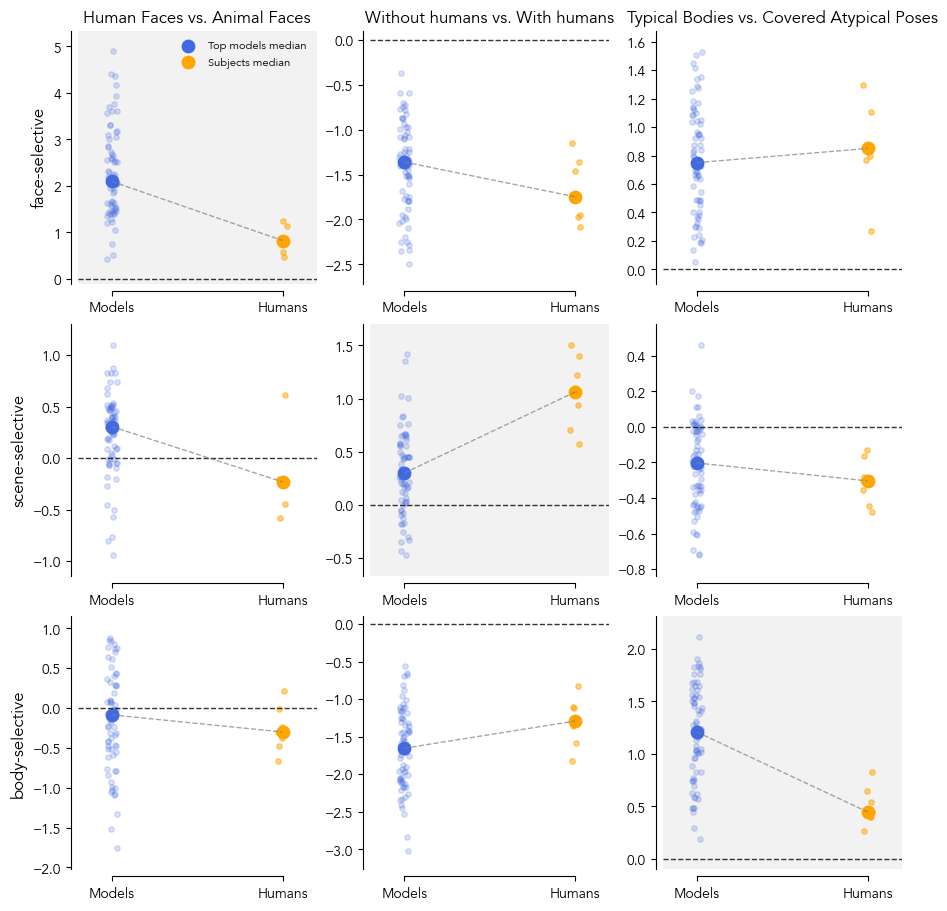

In [10]:
savefig = False

bag_types = ['faces', 'scenes', 'bodies']
frois = ['FFA', 'PPA', 'EBA']

froi_lims = {
    'FFA': [0, 6.25],
    'PPA': [-1, 1.25],
    'EBA': [-1, 3.25],
}
froi_ticks = {
    'FFA': np.array([0, 3, 6]),
    'PPA': np.array([-1, 0, 1]),
    'EBA': np.array([-1, 0, 1, 2, 3]),
}
froi_labels = {
    'FFA': 'face-selective',
    'PPA': 'scene-selective',
    'EBA': 'body-selective',
}
othermodels_color = "royalblue"
subjects_color = 'orange'

fig, axes = plt.subplots(len(frois), len(bag_types), figsize=(3*len(bag_types), 3*len(frois)), constrained_layout=True)
for bidx, bag_type in enumerate(bag_types):
    bag1_label = bags[2][bag_type]['bag1']['label']
    bag2_label = bags[2][bag_type]['bag2']['label']
    for fidx, froi in enumerate(frois):
        ax = axes[fidx, bidx]
        if fidx == bidx: # Highlight the diagonal
            ax.set_facecolor((0.5, 0.5, 0.5, 0.1))
        ax_pts = []
        y_lims = froi_lims[froi]
        y_ticks = froi_ticks[froi]
        
        # y=0 line
        ax.axhline(y=0, color='k', linestyle='--', linewidth=1, alpha=0.8)
        
        # Calculate model deltas
        model_deltas = []
        for model_name in reversed(TOP_MODEL_NAMES):
            if model_name == 'resnet50imagenet1kv2':
                continue # Skip ResNet-50 ImageNet-1k
            
            model_subject_deltas = []
            for subject in range(2, 9):
                bag1_nsdids = bags[subject][bag_type]['bag1']['nsdids']
                bag2_nsdids = bags[subject][bag_type]['bag2']['nsdids']
                model_responses_bag1_median = np.median(resp_df[
                    (resp_df['subject'] == subject) &
                    (resp_df['froi'] == froi) &
                    (resp_df['nsd_id'].isin(bag1_nsdids))
                ][f'{model_name}_response'])
                model_responses_bag2_median = np.median(resp_df[
                    (resp_df['subject'] == subject) &
                    (resp_df['froi'] == froi) &
                    (resp_df['nsd_id'].isin(bag2_nsdids))
                ][f'{model_name}_response'])
                
                # Calculate delta between bag1 and bag2 (switched from bag2 - bag1)
                delta = model_responses_bag1_median - model_responses_bag2_median
                model_subject_deltas.append(delta)
            
            model_deltas.append(model_subject_deltas)
            
            # Plot individual model deltas with jitter
            for i, delta in enumerate(model_subject_deltas):
                jitter = np.random.uniform(-0.03, 0.03)
                ax.scatter(0 + jitter, delta, color=othermodels_color, alpha=0.2, s=15)
                ax_pts.append(delta)
        
        # Calculate median model delta
        model_deltas = np.array(model_deltas)
        model_median_delta = np.median(model_deltas)
        ax_pts.append(model_median_delta)
        
        # Plot median model delta
        ax.scatter(0, model_median_delta, color=othermodels_color, s=80, marker='o', 
                   label='Top models median' if bidx == 0 and fidx == 0 else "")
        
        # Calculate subject deltas
        subject_deltas = []
        for subject in range(2, 9):
            bag1_nsdids = bags[subject][bag_type]['bag1']['nsdids']
            bag2_nsdids = bags[subject][bag_type]['bag2']['nsdids']
            subject_responses_bag1_median = np.median(resp_df[
                (resp_df['subject'] == subject) &
                (resp_df['froi'] == froi) &
                (resp_df['nsd_id'].isin(bag1_nsdids))
            ]['subject_response'])
            subject_responses_bag2_median = np.median(resp_df[
                (resp_df['subject'] == subject) &
                (resp_df['froi'] == froi) &
                (resp_df['nsd_id'].isin(bag2_nsdids))
            ]['subject_response'])
            
            # Calculate delta between bag1 and bag2 (switched from bag2 - bag1)
            delta = subject_responses_bag1_median - subject_responses_bag2_median
            subject_deltas.append(delta)
            
            # Plot individual subject deltas with jitter
            jitter = np.random.uniform(-0.03, 0.03)
            ax.scatter(1 + jitter, delta, color=subjects_color, alpha=0.5, s=15)
            ax_pts.append(delta)
        
        # Calculate median subject delta
        subject_deltas = np.array(subject_deltas)
        subject_median_delta = np.median(subject_deltas)
        ax_pts.append(subject_median_delta)
        
        # Plot median subject delta
        ax.scatter(1, subject_median_delta, color=subjects_color, s=80, marker='o',
                   label='Subjects median' if bidx == 0 and fidx == 0 else "")
        
        # Connect median points with a line
        ax.plot([0, 1], [model_median_delta, subject_median_delta], '--', color='gray', alpha=0.7, linewidth=1)
        
        # Plot properties
        ax_pts = np.array(ax_pts)
        ax_range = ax_pts.max() - ax_pts.min()
        ax_min = np.min([ax_pts.min() - 0.1 * ax_range, -0.1])
        ax_max = np.max([ax_pts.max() + 0.1 * ax_range, 0.1])
        
        ax.set_xticks([0, 1])
        ax.set_xticklabels(['Models', 'Humans'])
        ax.set_xlim([-0.2, 1.2])
        ax.set_ylim(ax_min, ax_max)
        
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_position(('outward', 5))
        ax.spines['bottom'].set_position(('outward', 5))
        ax.spines['bottom'].set_bounds(0, 1)
        
        # Update labels to reflect bag1 - bag2 instead of bag2 - bag1
        # \n{bag1_label} - {bag2_label}
        ax.set_ylabel(f"{froi_labels[froi]}" if bidx == 0 else "", fontsize=12)
        type_label = f'{bag1_label} vs. {bag2_label}'
        if fidx == 0:
            ax.set_title(f"{type_label}", fontsize=12)
        else:
            ax.set_title("")
            
        if bidx == 0 and fidx == 0:
            ax.legend(frameon=False, fontsize=8, loc='upper right')
            
if savefig:
    raise NotImplementedError
    # plt.savefig(f'{PLOTS_DIR}/supfig_delta_models_vs_humans.pdf', dpi=300, bbox_inches='tight')
else:
    plt.show()
plt.close()

## Alternate z-scoring

In [12]:
# STIMULI = nsd.get_stimuli_dataset(NSD_DIR, transform=None, subset=None).all_stimuli

frois = ['FFA', 'PPA', 'EBA']
subjects = [2, 3, 4, 5, 6, 7, 8]  # NSD subjects
mean_responses_df_path = f'results/exploration/explore_interpret/subject_specific_mean_responses.csv'
resp_df = pd.read_csv(mean_responses_df_path)

froi_bags = {
    'FFA': 'faces',
    'PPA': 'scenes',
    'EBA': 'bodies',
}
model_color = '#944e1f' # Brown
subject_color = '#fde0c5' # Light peach

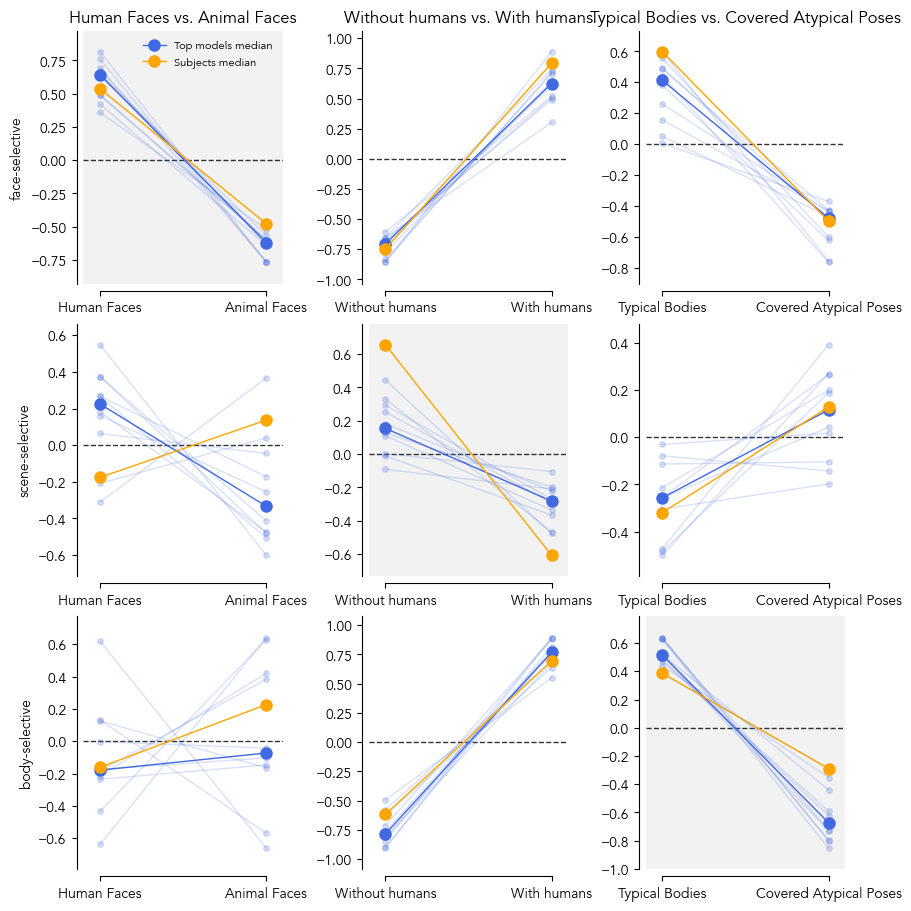

In [13]:
savefig = False

bag_types = ['faces', 'scenes', 'bodies']
frois = ['FFA', 'PPA', 'EBA']

froi_lims = {
    'FFA': [0, 6.25],
    'PPA': [-1, 1.25],
    'EBA': [-1, 3.25],
}
froi_ticks = {
    'FFA': np.array([0, 3, 6]),
    'PPA': np.array([-1, 0, 1]),
    'EBA': np.array([-1, 0, 1, 2, 3]),
}
froi_labels = {
    'FFA': 'face-selective',
    'PPA': 'scene-selective',
    'EBA': 'body-selective',
}
# rn50imgnet_color = 'k' # Black
othermodels_color = "royalblue"
subjects_color = 'orange'

fig, axes = plt.subplots(len(frois), len(bag_types), figsize=(3*len(bag_types), 3*len(frois)), constrained_layout=True)
for bidx, bag_type in enumerate(bag_types):
    bag1_label = bags[2][bag_type]['bag1']['label']
    bag2_label = bags[2][bag_type]['bag2']['label']
    for fidx, froi in enumerate(frois):
        ax = axes[fidx, bidx]
        if fidx == bidx: # Highlight the diagonal
            ax.set_facecolor((0.5, 0.5, 0.5, 0.1))
        ax_pts = []
        y_lims = froi_lims[froi]
        y_ticks = froi_ticks[froi]
        models_pts = []
        # y=0 line
        ax.axhline(y=0, color='k', linestyle='--', linewidth=1, alpha=0.8)
        for model_name in reversed(TOP_MODEL_NAMES):
            if model_name == 'resnet50imagenet1kv2':
                continue # Skip ResNet-50 ImageNet-1k
            model_pts = []
            for subject in range(2, 9):
                bag1_nsdids = bags[subject][bag_type]['bag1']['nsdids']
                bag2_nsdids = bags[subject][bag_type]['bag2']['nsdids']
                bag1_pts = np.array(resp_df[
                    (resp_df['subject'] == subject) &
                    (resp_df['froi'] == froi) &
                    (resp_df['nsd_id'].isin(bag1_nsdids))
                ][f'{model_name}_response'])
                bag2_pts = np.array(resp_df[
                    (resp_df['subject'] == subject) &
                    (resp_df['froi'] == froi) &
                    (resp_df['nsd_id'].isin(bag2_nsdids))
                ][f'{model_name}_response'])
                # Calculate combined bags mean and std for z-scoring
                combined_bags = np.concatenate([bag1_pts, bag2_pts])
                combined_mean = np.mean(combined_bags)
                combined_std = np.std(combined_bags)
                # Z-score the model responses within the combined bags
                bag1_pts_z = (bag1_pts - combined_mean) / combined_std
                bag2_pts_z = (bag2_pts - combined_mean) / combined_std
                # Calculate median of z-scored responses
                model_responses_bag1_median = np.median(bag1_pts_z)
                model_responses_bag2_median = np.median(bag2_pts_z)
                model_pts.append((model_responses_bag1_median, model_responses_bag2_median))
            model_pts = np.array(model_pts)
            model_pts_medians = np.median(model_pts, axis=0)
            ax_pts += model_pts_medians.tolist()
            models_pts.append(model_pts_medians)
            ax.plot(
                [0, 1],
                [model_pts_medians[0], model_pts_medians[1]],
                '-o',
                color=rn50imgnet_color if model_name == 'resnet50imagenet1kv2' else othermodels_color,
                alpha=1 if model_name == 'resnet50imagenet1kv2' else 0.2,
                markersize=4,
                linewidth=1,
                # zorder=5,
                # label=model_name if model_name == 'resnet50imagenet1kv2' else ("other models" if bidx == 0 and fidx == 0 else ""),
            )
        # Plot median across models
        models_pts = np.array(models_pts)
        models_pts_medians = np.median(models_pts, axis=0)
        ax_pts += models_pts_medians.tolist()
        ax.plot(
            [0, 1],
            [models_pts_medians[0], models_pts_medians[1]],
            '-o',
            color=othermodels_color,
            alpha=1,
            markersize=8,
            linewidth=1,
            # zorder=6,
            label='Top models median' if bidx == 0 and fidx == 0 else "",
        )
        # Add median across subjects
        subject_pts = []
        for subject in range(2, 9):
            bag1_nsdids = bags[subject][bag_type]['bag1']['nsdids']
            bag2_nsdids = bags[subject][bag_type]['bag2']['nsdids']
            bag1_pts = np.array(resp_df[
                (resp_df['subject'] == subject) &
                (resp_df['froi'] == froi) &
                (resp_df['nsd_id'].isin(bag1_nsdids))
            ]['subject_response'])
            bag2_pts = np.array(resp_df[
                (resp_df['subject'] == subject) &
                (resp_df['froi'] == froi) &
                (resp_df['nsd_id'].isin(bag2_nsdids))
            ]['subject_response'])
            # Calculate combined bags mean and std for z-scoring
            combined_bags = np.concatenate([bag1_pts, bag2_pts])
            combined_mean = np.mean(combined_bags)
            combined_std = np.std(combined_bags)
            # Z-score the model responses within the combined bags
            bag1_pts_z = (bag1_pts - combined_mean) / combined_std
            bag2_pts_z = (bag2_pts - combined_mean) / combined_std
            # Calculate median of z-scored responses
            subject_responses_bag1_median = np.median(bag1_pts_z)
            subject_responses_bag2_median = np.median(bag2_pts_z)
            subject_pts.append((subject_responses_bag1_median, subject_responses_bag2_median))
        subject_pts = np.array(subject_pts)
        subject_pts_medians = np.median(subject_pts, axis=0)
        ax_pts += subject_pts_medians.tolist()
        ax.plot(
            [0, 1],
            [subject_pts_medians[0], subject_pts_medians[1]],
            '-o',
            color=subjects_color,
            alpha=1,
            markersize=8,
            linewidth=1,
            # zorder=6,
            label='Subjects median' if bidx == 0 and fidx == 0 else "",
        )
        # Plot properties
        ax_pts = np.array(ax_pts)
        ax_min = np.min([ax_pts.min() - 0.1*(ax_pts.max() - ax_pts.min()), -0.1])
        ax_max = np.max([ax_pts.max() + 0.1*(ax_pts.max() - ax_pts.min()), 0.1])
        # Set legend labels manually
        # ax.plot([], [], '-o', color=rn50imgnet_color, alpha=1, markersize=8, linewidth=1, label='ResNet-50 ImageNet-1k')
        # ax.plot([], [], '-o', color=othermodels_color, alpha=1, markersize=8, linewidth=1, label='Top models')
        ax.set_xticks([0, 1])
        ax.set_xticklabels([bag1_label, bag2_label])
        ax.set_xlim([-0.1, 1.1])
        ax.set_ylim(ax_min, ax_max)
        # ax.set_yticks(y_ticks)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_position(('outward', 5))
        ax.spines['bottom'].set_position(('outward', 5))
        # ax.spines['left'].set_bounds(y_ticks.min(), y_ticks.max())
        ax.spines['bottom'].set_bounds(0, 1)
        ax.set_ylabel(froi_labels[froi] if bidx == 0 else "")
        type_label = f'{bag1_label} vs. {bag2_label}'
        if fidx == 0:
            ax.set_title(f"{type_label}", fontsize=12)
        else:
            ax.set_title("")
        if bidx == 0 and fidx == 0:
            ax.legend(frameon=False, fontsize=8, loc='upper right')
if savefig:
    raise NotImplementedError
    # plt.savefig(f'{PLOTS_DIR}/supfig_lineplot_allmodelsfrois.pdf', dpi=300, bbox_inches='tight')
else:
    plt.show()
plt.close()